# **Section 1 — Environment Setup**

In [107]:
# ============================================================
# SECTION 1: ENVIRONMENT SETUP
# ============================================================

import os
import sys
import re
import json
import csv
import random
import warnings
import importlib.util

import inspect

import py_compile

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Competition paths
DATA_DIR = (
    "/kaggle/input/competitions/"
    "vendor-verdict-can-we-trust-this-ai-tool"
)

SCRIPT_PATH = (
    "/kaggle/working/vendor_verdict_solution.py"
)

OUTPUT_DIR = "/kaggle/working"

# Validate paths
assert os.path.exists(DATA_DIR)


print("Environment initialized successfully")
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Dataset directory:", DATA_DIR)
print("Solution script:", SCRIPT_PATH)

Environment initialized successfully
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.3.3
NumPy version: 2.1.3
Dataset directory: /kaggle/input/competitions/vendor-verdict-can-we-trust-this-ai-tool
Solution script: /kaggle/working/vendor_verdict_solution.py


# **Section 2 — Competition Dataset Loading and validate**

## **2.1 validate all competition dataset availbility**

In [108]:
#========================================
# 2.1 validate all competition dataset availbility
#========================================
required_files = {
    "sample_submission.csv",
    "train_labels.csv",
    "cases.csv",
    "test.csv",
    "pages.jsonl",
    "requirements.json",
    "rules_lite.py",
    "naive_baseline.py",
    "metric.py",
}

for root, dirs, files in os.walk("/kaggle/input"):

    if required_files.issubset(set(files)):
        DATA_DIR = root
        break

if DATA_DIR:
    print("SUCCESS! Dataset found:")
    print(DATA_DIR)
    print("\nAvailable files:")
    print(os.listdir(DATA_DIR))
else:
    print("ERROR: Competition dataset not found")

SUCCESS! Dataset found:
/kaggle/input/competitions/vendor-verdict-can-we-trust-this-ai-tool

Available files:
['sample_submission.csv', 'requirements.json', 'naive_baseline.py', 'cases.csv', 'metric.py', 'train_labels.csv', 'test.csv', 'rules_lite.py', 'pages.jsonl']


## **SECTION 2.2: DATASET LOADING**

In [109]:
# ============================================================
# SECTION 2.2: DATASET LOADING
# ============================================================

# Load CSV files
cases_df = pd.read_csv(
    os.path.join(DATA_DIR, "cases.csv")
)

train_labels_df = pd.read_csv(
    os.path.join(DATA_DIR, "train_labels.csv")
)

test_df = pd.read_csv(
    os.path.join(DATA_DIR, "test.csv")
)

sample_submission_df = pd.read_csv(
    os.path.join(DATA_DIR, "sample_submission.csv")
)

# Load requirements
with open(
    os.path.join(DATA_DIR, "requirements.json"),
    "r",
    encoding="utf-8"
) as f:
    requirements = json.load(f)

# Load JSONL pages
pages = []

with open(
    os.path.join(DATA_DIR, "pages.jsonl"),
    "r",
    encoding="utf-8"
) as f:

    for line in f:
        if line.strip():
            pages.append(json.loads(line))

pages_df = pd.DataFrame(pages)

# Display dataset information
print("CASES:", cases_df.shape)
print("TRAIN LABELS:", train_labels_df.shape)
print("TEST:", test_df.shape)
print("PAGES:", pages_df.shape)
print("REQUIREMENTS:", len(requirements))

print("\nCases:")
display(cases_df.head())

print("\nPages:")
display(pages_df.head())

print("\nTraining labels:")
display(train_labels_df.head())

print("\nRequirements:")
display(pd.DataFrame(requirements))

CASES: (700, 12)
TRAIN LABELS: (3185, 4)
TEST: (2378, 3)
PAGES: (7396, 9)
REQUIREMENTS: 10

Cases:


,case_id,split,vendor,legal_entity,official_domain,hq_country,hq_city,product,question,tier,users,as_of
0,c0001,train,Yarrabase,Yarrabase Ltd,yarrabase.example,Ireland,Dublin,a sales-call coaching tool,Can the sales team use Yarrabase to analyse re...,T3,120,2026-11-01
1,c0002,test,Garnforge AI,Garnforge BV,garnforge.example,Netherlands,Amsterdam,a document Q&A assistant over internal wikis,Can the operations team use Garnforge AI to an...,T3,25,2026-11-01
2,c0003,test,Corvawise Labs,Corvawise Inc,corvawise.example,Canada,Toronto,a résumé-screening assistant,Can the HR team use Corvawise Labs to screen c...,T3,25,2026-11-01
3,c0004,test,Quillscribe,Quillscribe Pvt Ltd,quillscribe.example,India,Pune,a résumé-screening assistant,Can the HR team use Quillscribe to screen cand...,T3,12,2026-11-01
4,c0005,train,Yarraware,Yarraware Pvt Ltd,yarraware.example,India,Bengaluru,an AI writing tool that drafts customer email ...,Can the marketing team use Yarraware to draft ...,T3,120,2026-11-01



Pages:


,page_id,case_id,url,title,source_type,publisher,published_date,last_updated,text
0,c0001-p01,c0001,https://yarrabase.example/pricing,Yarrabase Pricing and plans,official,Yarrabase,2024-11-12,2026-08-25,Yarrabase Pricing and plans\n\n- Employees com...
1,c0001-p02,c0001,https://status.yarrabase.example/history,Yarrabase Status and incident history,official,Yarrabase,2026-04-06,2026-07-31,Yarrabase Status and incident history\n\n- 202...
2,c0001-p03,c0001,https://yarrabase-global.example/about-us,About Yarrabase Global Pty Ltd,official,Yarrabase Global Pty Ltd,2025-02-03,2026-06-26,About Yarrabase Global Pty Ltd\n\n- Yarrabase ...
3,c0001-p04,c0001,https://technews.example/2024/03/yarrabase-sec...,Yarrabase confirms security incident,news,TechNews Weekly,2024-03-28,2024-03-28,Yarrabase has confirmed a security incident. D...
4,c0001-p05,c0001,https://reviewhub.example/software/yarrabase,Yarrabase reviews and pricing,review_site,ReviewHub,2025-01-18,2026-09-24,Yarrabase reviews\n\nAverage rating: 4.3 out o...



Training labels:


,id,case_id,requirement_id,verdict
0,c0001__SEC-4.2,c0001,SEC-4.2,UNKNOWN
1,c0001__DP-3.1,c0001,DP-3.1,FAIL
2,c0001__AI-2.1,c0001,AI-2.1,NEEDS_REVIEW
3,c0001__AI-3.4,c0001,AI-3.4,UNKNOWN
4,c0001__DP-5.4,c0001,DP-5.4,PASS



Requirements:


,id,title,policy_doc,clause,field,rule,params,severity,applies_when
0,SEC-4.2,Independent security assurance (SOC 2 Type II ...,information_security_policy_2026.md,SEC-4.2,security_certifications,certification_valid,"{'accepted': ['SOC 2 Type II', 'ISO 27001'], '...",blocker,"{'tiers': ['T3'], 'or_min_users': None}"
1,SEC-4.2-T2,Security assurance for internal-data tools (Ty...,information_security_policy_2026.md,SEC-4.2,security_certifications,certification_valid,"{'accepted': ['SOC 2 Type II', 'SOC 2 Type I',...",major,"{'tiers': ['T2'], 'or_min_users': None}"
2,DP-3.1,Customer data stored in India,data_protection_policy.md,DP-3.1,data_regions,region_includes,"{'any_of': ['India'], 'allow_planned': False}",blocker,"{'tiers': ['T3'], 'or_min_users': None}"
3,DP-3.2,Storage region recorded (internal data),data_protection_policy.md,DP-3.2,data_regions,value_known,{},minor,"{'tiers': ['T2'], 'or_min_users': None}"
4,AI-2.1,No training on Nimbu Mart data,ai_acceptable_use_policy.md,AI-2.1,trains_on_customer_data,enum_verdict,"{'pass': ['no'], 'review': ['no_on_paid_plans'...",blocker,"{'tiers': ['T2', 'T3'], 'or_min_users': None}"
5,AI-3.4,Sub-processors disclosed; model providers iden...,ai_acceptable_use_policy.md,AI-3.4,subprocessors,list_disclosed,{'review_if_category': ['model_provider']},major,"{'tiers': ['T2', 'T3'], 'or_min_users': None}"
6,DP-5.4,Deletion within 30 days of contract end or req...,data_protection_policy.md,DP-5.4,data_retention,retention_within,{'max_days': 30},major,"{'tiers': ['T3'], 'or_min_users': None}"
7,SEC-7.1,Single sign-on (SAML / OIDC),information_security_policy_2026.md,SEC-7.1,sso_saml,enum_verdict,"{'pass': ['all_plans', 'paid_plans'], 'review'...",major,"{'tiers': ['T3'], 'or_min_users': 21}"
8,SEC-9.3,No major incident in 24 months without a publi...,information_security_policy_2026.md,SEC-9.3,security_incidents,no_unresolved_incident,"{'lookback_months': 24, 'major_severities': ['...",blocker,"{'tiers': ['T3'], 'or_min_users': None}"
9,DP-2.2,Data Processing Agreement available,data_protection_policy.md,DP-2.2,dpa_available,enum_verdict,"{'pass': ['yes'], 'review': ['on_request'], 'f...",blocker,"{'tiers': ['T3'], 'or_min_users': None}"


## **2.3 Dataset integrity**

In [110]:
# ============================================================
# 2.3 DATASET INTEGRITY CHECK
# ============================================================

assert cases_df["case_id"].is_unique

assert set(cases_df["split"].unique()) == {
    "train", "test"
}

assert set(train_labels_df["case_id"]).issubset(
    set(cases_df["case_id"])
)

assert set(test_df["case_id"]).issubset(
    set(cases_df["case_id"])
)

assert pages_df["case_id"].isin(
    cases_df["case_id"]
).all()

print("Dataset integrity checks PASSED")

print("\nSplit distribution:")
display(cases_df["split"].value_counts())

print("\nPage source distribution:")
display(pages_df["source_type"].value_counts())

Dataset integrity checks PASSED

Split distribution:


split
train    400
test     300
Name: count, dtype: int64


Page source distribution:


source_type
official           5337
review_site         429
news                385
news_syndicated     327
regulator           321
forum               311
blog                286
Name: count, dtype: int64

# **Section-3 create vendor_verdict_solution.py for Generate output**

## **3.1 generate new file** 

In [111]:
%%writefile /kaggle/working/vendor_verdict_solution.py

"""
Vendor Verdict - evidence-first deterministic solver.

Run:
    python vendor_verdict_fixed.py --data /path/to/extracted/data --out submission.csv

The competition's rules_lite.py is the source of truth for verdict arithmetic.
This script only extracts facts from admissible evidence, then calls rules_lite.
"""
from __future__ import annotations

import argparse
import csv
import json
import re
import random
from collections import defaultdict, Counter
from datetime import date, datetime
from pathlib import Path
from urllib.parse import urlparse

import rules_lite as rl

AS_OF_DEFAULT = date(2026, 11, 1)
COUNTRIES = [
    "United States", "United Kingdom", "European Union", "India", "Singapore",
    "Canada", "Australia", "Japan", "Germany", "Ireland", "France",
    "Netherlands", "Switzerland", "Brazil", "South Korea", "UAE",
    "United Arab Emirates", "Hong Kong"
]

INJECTION_RE = re.compile(
    r"(ignore (?:all |the )?(?:previous |prior )?(?:instructions|rules)|"
    r"report\s+pass|mark\s+.{0,30}\bpass\b|"
    r"as an ai (?:assistant|system)|"
    r"(?:assistant|ai system)s?\s+(?:should|must|need to)\s+"
    r"(?:return|report|output|mark)|"
    r"system prompt|override (?:the )?(?:policy|instructions))",
    re.I
)

def parse_date(value, default=None):
    if not value:
        return default
    s = str(value).strip()
    try:
        return date.fromisoformat(s[:10].replace("/", "-"))
    except ValueError:
        pass
    for fmt in ("%B %d, %Y", "%B %d %Y", "%b %d, %Y",
                "%d %B %Y", "%d %b %Y", "%Y/%m/%d"):
        try:
            return datetime.strptime(s, fmt).date()
        except ValueError:
            continue
    return default

def host_of(url):
    try:
        return (urlparse(str(url)).hostname or "").lower().rstrip(".")
    except Exception:
        return ""

def clean_lines(text):
    """Keep evidence as data; drop only lines that are prompt-injection instructions."""
    out = []
    for line in re.split(r"[\r\n]+", str(text or "")):
        line = line.strip()
        if line and not INJECTION_RE.search(line):
            out.append(line)
    return out

def is_vendor_domain(page, case):
    root = str(case.get("official_domain", "")).strip().lower().rstrip(".")
    host = host_of(page.get("url", ""))
    return bool(root and host and (host == root or host.endswith("." + root)))

def page_date(page):
    return (parse_date(page.get("last_updated")) or
            parse_date(page.get("published_date")) or date(1900, 1, 1))

def admissible_vendor_pages(pages, case, as_of):
    result = []

    for p in pages:

        # Only official vendor pages
        if str(p.get("source_type", "")).lower() != "official":
            continue

        # Verify vendor's official domain
        if not is_vendor_domain(p, case):
            continue

        # Enforce case as-of date
        if page_date(p) > as_of:
            continue

        result.append(p)

    return sorted(
        result,
        key=page_date,
        reverse=True
    )

def latest_page_with(pages, pattern):
    rx = re.compile(pattern, re.I)
    for p in pages:  # already newest first
        lines = clean_lines(p.get("text", ""))
        selected = [line for line in lines if rx.search(line)]
        if selected:
            return p, selected
    return None, []

def country_mentions(text):
    found = []
    low = text.lower()
    for country in COUNTRIES:
        if re.search(r"(?<![A-Za-z])" + re.escape(country.lower()) + r"(?![A-Za-z])", low):
            found.append(country)
    # Normalize common variants
    if re.search(r"\busa\b|\bu\.s\.a?\b", low) and "United States" not in found:
        found.append("United States")
    if re.search(r"\buk\b", low) and "United Kingdom" not in found:
        found.append("United Kingdom")
    # Remove duplicate aliases that can occur together
    if "UAE" in found and "United Arab Emirates" in found:
        found.remove("UAE")
    return found

def parse_fact_regions(pages):
    p, lines = latest_page_with(
        pages,
        r"data residency|storage region|available storage regions|"
        r"stored at rest|customer data is stored|keep your data in|"
        r"data (?:is )?hosted"
    )
    if not p:
        return None
    available, planned = set(), set()
    for line in lines:
        countries = country_mentions(line)
        if not countries:
            continue
        low = line.lower()
        if re.search(r"planned|coming soon|not available yet|roadmap|future region", low):
            planned.update(countries)
        else:
            available.update(countries)
    if not available and not planned:
        return None
    return {"value": {"available": sorted(available), "planned": sorted(planned)}}

def parse_certifications(vendor_pages, all_pages, case, as_of):
    # Keep the newest vendor-originated certification statement per certification family.
    selected = {}
    for p in vendor_pages:
        for line in clean_lines(p.get("text", "")):
            low = line.lower()
            if not re.search(r"soc\s*2|iso(?:/iec)?[\s-]*27001", low):
                continue
            family = "iso" if re.search(r"iso(?:/iec)?[\s-]*27001", low) else "soc2"
            if family not in selected:
                selected[family] = (p, line)

    certs = []
    evidence_documented = False

    # SOC 2: report/certification must name issuer and date to be documented.
    if "soc2" in selected:
        p, line = selected["soc2"]
        low = line.lower()
        if re.search(r"in progress|underway|expected (?:in|by)|audit is ongoing", low):
            certs.append({"name": "SOC 2 Type II" if re.search(r"type\s*(?:ii|2)", low) else "SOC 2",
                          "status": "in_progress", "date": None, "valid_until": None})
        else:
            if re.search(r"type\s*(?:ii|2)", low):
                name = "SOC 2 Type II"
            elif re.search(r"type\s*(?:i|1)", low):
                name = "SOC 2 Type I"
            else:
                name = "SOC 2"
            issuer = bool(re.search(
                r"\b(?:issued by|from|by)\s+[A-Z][A-Za-z&.,' -]{2,65}"
                r"(?:CPAs?|CPA|Assurance|Compliance|Audit|Partners|Group|LLP)?",
                line
            ))
            # Date can be numeric or written month/day/year; prefer issue date, not period start.
            date_match = re.search(
                r"(?:issued\s+(?:on\s+)?)((?:20\d{2}-\d{2}-\d{2})|"
                r"(?:\d{1,2}\s+[A-Z][a-z]+\s+20\d{2})|"
                r"(?:[A-Z][a-z]+\s+\d{1,2},?\s+20\d{2}))",
                line, re.I
            )
            issued = None
            if date_match:
                issued = parse_date(date_match.group(1))
            if not issued:
                # Some source wording puts date before "issued".
                m = re.search(r"\b(20\d{2}-\d{2}-\d{2})\b", line)
                if m:
                    issued = parse_date(m.group(1))
            if not issued:
                m = re.search(r"\b([A-Z][a-z]+\s+\d{1,2},?\s+20\d{2})\b", line)
                if m:
                    issued = parse_date(m.group(1))
            certs.append({"name": name, "status": "certified",
                          "date": issued.isoformat() if issued else None,
                          "valid_until": None})
            if issuer and issued:
                evidence_documented = True

    # ISO 27001: accept registry entries only when the holder exactly matches
    # the case's legal entity AND the certificate is referenced by the vendor's own domain.
    if "iso" in selected:
        p, line = selected["iso"]
        id_match = re.search(r"\bISO[- ]?27001[- ]\d+\b", line, re.I)
        cert_id = id_match.group(0).replace(" ", "-") if id_match else None
        legal = str(case.get("legal_entity", "")).strip().casefold()
        registry_match = None
        if cert_id and legal:
            for rp in all_pages:
                if str(rp.get("source_type", "")).lower() != "regulator":
                    continue
                if page_date(rp) > as_of:
                    continue
                rtext = "\n".join(clean_lines(rp.get("text", "")))
                if cert_id.lower() not in rtext.lower():
                    continue
                # Require exact legal entity holder, not a similar company.
                if legal not in rtext.casefold():
                    continue
                if not re.search(r"certified to ISO|standard:\s*ISO|ISO/IEC 27001", rtext, re.I):
                    continue
                registry_match = rp
                break

        if registry_match:
            rtext = "\n".join(clean_lines(registry_match.get("text", "")))
            issued = None
            valid = None
            m = re.search(r"(?:first issued|issued)\s+([A-Z][a-z]+\s+\d{1,2},?\s+20\d{2}|\d{1,2}\s+[A-Z][a-z]+\s+20\d{2}|20\d{2}-\d{2}-\d{2})", rtext, re.I)
            if m: issued = parse_date(m.group(1))
            m = re.search(r"(?:valid until|expires?)\s+([A-Z][a-z]+\s+\d{1,2},?\s+20\d{2}|\d{1,2}\s+[A-Z][a-z]+\s+20\d{2}|20\d{2}-\d{2}-\d{2})", rtext, re.I)
            if m: valid = parse_date(m.group(1))
            certs.append({"name": "ISO 27001", "status": "certified",
                          "date": issued.isoformat() if issued else None,
                          "valid_until": valid.isoformat() if valid else None})
            evidence_documented = True
        else:
            certs.append({"name": "ISO 27001", "status": "certified",
                          "date": None, "valid_until": None})

    if not certs:
        return None
    return {"value": certs,
            "evidence_level": "documented" if evidence_documented else "claimed"}

def parse_training(pages):
    # Do not confuse employee security-awareness training with AI model training.
    p, lines = latest_page_with(
        pages, r"customer.{0,50}(?:train|model)|content.{0,50}(?:train|model)|"
               r"model training|fine.?tun|improve our models|"
               r"prompts?.{0,50}(?:train|model)|outputs?.{0,50}(?:train|model)"
    )
    if not p:
        return None
    for line in lines:
        low = line.lower()
        if re.search(r"not used for training|not used to train|not use .*train|"
                     r"never use .*train|never use .*training|not used for model training|"
                     r"customer data is not used for training|not used for training on any plan", low):
            if re.search(r"paid plans?|free workspaces?.{0,80}(?:may|can|contribute)", low):
                return {"value": "no_on_paid_plans"}
            return {"value": "no"}
        if re.search(r"may be used|may use .*content|use .*content to train|"
                     r"used to improve our models unless|unless .*turns? off", low):
            if re.search(r"unless|opt.?out|turns? off|disable", low):
                return {"value": "opt_out_available"}
            return {"value": "yes"}
        if re.search(r"paid plans?.{0,100}do not use|on paid plans.{0,100}not use", low):
            return {"value": "no_on_paid_plans"}
    return None

def parse_sso(pages):
    p, lines = latest_page_with(pages, r"\bsso\b|single sign.?on|saml|oidc")
    if not p:
        return None
    for line in lines:
        low = line.lower()
        if re.search(r"do not currently offer|does not offer|not offer|not supported|"
                     r"no sso|single sign.?on is not|users sign in with email", low):
            return {"value": "none"}
        if re.search(r"enterprise.{0,35}only|only.{0,35}enterprise", low):
            return {"value": "enterprise_only"}
        if re.search(r"all plans|every plan|all customers|every customer", low):
            return {"value": "all_plans"}
        if re.search(r"paid plans?|business and enterprise|business or enterprise", low):
            return {"value": "paid_plans"}
    return None

def parse_dpa(pages):
    p, lines = latest_page_with(pages, r"\bdpa\b|data processing agreement|data processing addendum")
    if not p:
        return None
    for line in lines:
        low = line.lower()
        if re.search(r"do not currently offer|does not offer|not offered|not available|"
                     r"no separate data processing|dpa is not offered", low):
            return {"value": "no"}
        if re.search(r"available on request|upon request|contact our security team|"
                     r"contact legal|available upon request", low):
            return {"value": "on_request"}
        if re.search(r"built into our terms|published on our legal|applies to every customer|"
                     r"applies automatically|signed dpa", low):
            return {"value": "yes"}
    return None

def parse_subprocessors(pages):
    # Find the newest vendor page that contains a subprocessor disclosure, then
    # parse the complete page (not just the heading line).
    selected_page = None
    for page in pages:
        text = "\n".join(clean_lines(page.get("text", "")))
        if (re.search(r"sub.?processors?", text, re.I) or
                re.search(r"we use .{2,80}\([^)]+\)\s+for\s+", text, re.I)):
            selected_page = page
            break
    if not selected_page:
        return None

    items = []
    for line in clean_lines(selected_page.get("text", "")):
        low = line.lower()
        if re.search(r"sub.?processors?\s*\(name|our sub.?processors", low):
            continue
        # Table format: | provider | purpose | country |
        cells = [c.strip(" |-") for c in line.split("|") if c.strip(" |-")]
        name = None
        purpose = line
        if len(cells) >= 3:
            name = cells[0]
            purpose = " ".join(cells[1:-1])
        else:
            m = re.search(r"we use\s+(.+?)\s+\(([^)]+)\)\s+for\s+(.+?)[.;]?$", line, re.I)
            if m:
                name, purpose = m.group(1).strip(), m.group(3).strip()
        if not name:
            continue
        pl = purpose.lower()
        if re.search(r"model inference|language model|ai model|llm|generative ai", pl):
            category = "model_provider"
        elif re.search(r"hosting|storage|infrastructure|cloud", pl):
            category = "hosting"
        elif re.search(r"email|transactional mail", pl):
            category = "email"
        elif re.search(r"analytics|usage metrics", pl):
            category = "analytics"
        elif re.search(r"support|helpdesk|customer service", pl):
            category = "support"
        else:
            category = "other"
        items.append({"name": name, "category": category})

    if not items:
        return None
    return {"value": items}

def parse_days(line):
    m = re.search(r"\b(\d{1,4})\s*days?\b", line, re.I)
    return int(m.group(1)) if m else None

def parse_retention(pages):
    p, lines = latest_page_with(
        pages, r"default retention|retained for|retention period|"
               r"deletion requests?|request deletion|deleted within|"
               r"deletion.{0,30}within|deletion.{0,30}days"
    )
    if not p:
        return None
    default_days = None
    deletion_days = None
    for line in lines:
        low = line.lower()
        n = parse_days(line)
        if n is None:
            continue
        if re.search(r"default retention|after contract end|following termination|"
                     r"retained for|retention period|content is retained", low):
            default_days = n
        if re.search(r"deletion request|request deletion|delete.{0,25}within|"
                     r"deletion.{0,25}within|complete it within|honoured within", low):
            deletion_days = n
    if default_days is None and deletion_days is None:
        return None
    return {"value": {"default_days": default_days,
                      "deletion_on_request_days": deletion_days}}

def parse_incidents(pages):
    # Select the newest official incident-history page, then inspect every row
    # on that page, including table rows that do not repeat the word "incident".
    selected_page = None
    for page in pages:
        text = "\n".join(clean_lines(page.get("text", "")))
        if re.search(r"incident history|incident log|security incident|"
                     r"post.?incident review|breach|unauthori[sz]ed access|data exposure", text, re.I):
            selected_page = page
            break
    if not selected_page:
        return None

    lines = clean_lines(selected_page.get("text", ""))
    text = "\n".join(lines)
    if re.search(r"no security incidents?.{0,100}(?:past two years|last 24 months|past 24 months)|"
                 r"no security incident affecting customer data.{0,100}(?:last 24 months|past two years)|"
                 r"no incidents involving customer data in the past two years", text, re.I):
        return {"value": []}

    incidents = []
    for line in lines:
        m = re.search(r"\b(20\d{2}-\d{2}-\d{2})\b", line)
        if not m:
            m = re.search(r"\b([A-Z][a-z]+\s+\d{1,2},?\s+20\d{2})\b", line)
        if not m:
            m = re.search(r"\b(\d{1,2}\s+[A-Z][a-z]+\s+20\d{2})\b", line)
        if not m:
            continue
        dt = parse_date(m.group(1))
        if not dt:
            continue
        sev = re.search(r"\b(critical|major|minor)\b", line, re.I)
        if not sev:
            continue
        low = line.lower()
        published = bool(re.search(r"published", low))
        if re.search(r"not published|not yet published|not been published|unpublished", low):
            published = False
        incidents.append({
            "date": dt.isoformat(),
            "summary": line[:300],
            "severity": sev.group(1).lower(),
            "postmortem_published": published
        })
    if incidents:
        return {"value": incidents}
    return None


def extract_facts(case, pages):
    """
    Extract vendor facts from admissible evidence pages.

    Existing parser logic and evidence-admissibility rules are preserved.
    Parser failures are logged independently so one failure does not
    prevent extraction of other facts.
    """

    case_id = case.get("case_id", "UNKNOWN")

    as_of = parse_date(
        case.get("as_of"),
        AS_OF_DEFAULT
    )

    # Step 1: Filter admissible vendor pages
    official_pages = admissible_vendor_pages(
        pages,
        case,
        as_of
    )

    facts = {}

    # Step 2: Define existing parsers
    parser_config = {
        "security_certifications": lambda: parse_certifications(
            official_pages, pages, case, as_of
        ),
        "data_regions": lambda: parse_fact_regions(official_pages),
        "trains_on_customer_data": lambda: parse_training(official_pages),
        "subprocessors": lambda: parse_subprocessors(official_pages),
        "data_retention": lambda: parse_retention(official_pages),
        "sso_saml": lambda: parse_sso(official_pages),
        "security_incidents": lambda: parse_incidents(official_pages),
        "dpa_available": lambda: parse_dpa(official_pages),
    }

    # Step 3: Execute parsers independently
    for field, parser in parser_config.items():

        try:
            result = parser()

            if result is not None:
                facts[field] = result

        except Exception as exc:
            print(
                f"[EXTRACTION ERROR] "
                f"case_id={case_id}, "
                f"field={field}, "
                f"error={type(exc).__name__}: {exc}"
            )

    return facts

def load_inputs(data_dir):
    d = Path(data_dir)
    required = ["cases.csv", "pages.jsonl", "requirements.json", "test.csv", "rules_lite.py"]
    missing = [name for name in required if not (d / name).exists()]
    if missing:
        raise FileNotFoundError(f"Missing required files in {d}: {missing}")

    with (d / "cases.csv").open(encoding="utf-8-sig", newline="") as f:
        cases = {r["case_id"]: r for r in csv.DictReader(f)}

    pages_by_case = defaultdict(list)
    with (d / "pages.jsonl").open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                p = json.loads(line)
                pages_by_case[p["case_id"]].append(p)

    requirements = rl.load_requirements(d / "requirements.json")
    with (d / "test.csv").open(encoding="utf-8-sig", newline="") as f:
        test_rows = list(csv.DictReader(f))
    return d, cases, pages_by_case, requirements, test_rows

def make_predictions(data_dir):
    d, cases, pages_by_case, requirements, test_rows = load_inputs(data_dir)
    case_cache = {}
    for cid, case in cases.items():
        if case.get("split") != "test":
            continue
        facts = extract_facts(case, pages_by_case[cid])
        verdicts = rl.evaluate(
            facts, requirements, case["tier"], int(case["users"]),
            case.get("as_of") or AS_OF_DEFAULT.isoformat()
        )
        overall = rl.overall(verdicts, requirements)
        case_cache[cid] = (verdicts, overall, facts)

    output = []
    for row in test_rows:
        cid, rid = row["case_id"], row["requirement_id"]
        if cid not in case_cache:
            raise ValueError(f"Test row references unknown or non-test case: {cid}")
        verdicts, overall, _facts = case_cache[cid]
        value = overall if rid == "OVERALL" else verdicts.get(rid, "UNKNOWN")
        output.append({"id": row["id"], "verdict": value})

    expected_ids = [r["id"] for r in test_rows]
    actual_ids = [r["id"] for r in output]
    if expected_ids != actual_ids:
        raise AssertionError("Generated IDs/order differ from test.csv")
    if len(actual_ids) != len(set(actual_ids)):
        raise AssertionError("Duplicate IDs generated")
    allowed_req = set(rl.VERDICTS)
    allowed_overall = set(rl.OVERALL)
    for row in output:
        allowed = allowed_overall if row["id"].endswith("__OVERALL") else allowed_req
        if row["verdict"] not in allowed:
            raise ValueError(f"Invalid verdict {row['verdict']} for {row['id']}")
    return output, case_cache

def write_submission(rows, out_path):
    out = Path(out_path)
    out.parent.mkdir(parents=True, exist_ok=True)
    with out.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=["id", "verdict"])
        writer.writeheader()
        writer.writerows(rows)

def validate_train(data_dir, holdout_fraction=0.20, seed=42):
    """Case-level holdout diagnostic on training labels (no row leakage)."""
    d, cases, pages_by_case, requirements, _ = load_inputs(data_dir)
    labels_path = d / "train_labels.csv"
    with labels_path.open(encoding="utf-8-sig", newline="") as f:
        gold_rows = list(csv.DictReader(f))

    train_case_ids = sorted(cid for cid, c in cases.items() if c.get("split") == "train")
    rng = random.Random(seed)
    shuffled = train_case_ids[:]
    rng.shuffle(shuffled)
    n_holdout = max(1, round(len(shuffled) * holdout_fraction))
    holdout_ids = set(shuffled[:n_holdout])

    case_cache = {}
    for cid in holdout_ids:
        case = cases[cid]
        facts = extract_facts(case, pages_by_case[cid])
        verdicts = rl.evaluate(
            facts, requirements, case["tier"], int(case["users"]),
            case.get("as_of") or AS_OF_DEFAULT.isoformat()
        )
        case_cache[cid] = (verdicts, rl.overall(verdicts, requirements))

    holdout_gold = [r for r in gold_rows if r["case_id"] in holdout_ids]
    preds = []
    for r in holdout_gold:
        cid, rid = r["case_id"], r["requirement_id"]
        verdicts, overall = case_cache[cid]
        preds.append({
            "id": r["id"],
            "verdict": overall if rid == "OVERALL" else verdicts.get(rid, "UNKNOWN")
        })

    import pandas as pd
    import metric
    solution = pd.DataFrame(holdout_gold)[["id", "verdict"]]
    submission = pd.DataFrame(preds)
    result = metric.components(solution, submission)
    result["holdout_cases"] = len(holdout_ids)
    result["training_cases"] = len(train_case_ids)
    result["seed"] = seed
    return result

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default=".", help="Directory containing competition files")
    ap.add_argument("--out", default="submission.csv", help="Output CSV path")
    ap.add_argument("--validate-train", action="store_true",
                    help="Run a deterministic 20% case-level holdout diagnostic on training labels")
    args = ap.parse_args()

    if args.validate_train:
        scores = validate_train(args.data)
        print("TRAIN DIAGNOSTIC:", json.dumps(scores, indent=2))
    rows, cache = make_predictions(args.data)
    write_submission(rows, args.out)
    print(f"\nCreated: {Path(args.out).resolve()}")
    print(f"Rows: {len(rows)}")
    print("Verdict counts:", dict(Counter(r["verdict"] for r in rows)))
    print("Cases processed:", len(cache))
    print("Submission structure: PASSED")

if __name__ == "__main__":
    main()

Overwriting /kaggle/working/vendor_verdict_solution.py


## 3.2 Validate file exists or not

In [112]:
# ============================================================
# PYTHON SCRIPT VALIDATION
# ============================================================

# List files in Kaggle working directory
for dirname, _, filenames in os.walk('/kaggle/working'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Define solution file
FILE = "/kaggle/working/vendor_verdict_solution.py"

# Verify file exists
assert os.path.exists(FILE), f"File not found: {FILE}"

# Validate Python syntax
py_compile.compile(FILE, doraise=True)

# Display file information
print("\nExists:", os.path.exists(FILE))
print("Size:", os.path.getsize(FILE), "bytes")

print("\nPython syntax validation PASSED")

/kaggle/working/section_11_error_type_summary.csv
/kaggle/working/section_11_overall_errors.csv
/kaggle/working/all_test_evidence_matches.csv
/kaggle/working/vendor_verdict_solution.py
/kaggle/working/all_missing_test_facts.csv
/kaggle/working/section_11_actual_evidence_investigation.csv
/kaggle/working/section_11_error_investigation.csv
/kaggle/working/section_11_requirement_summary.csv
/kaggle/working/case_evidence_classification.csv
/kaggle/working/section_11_missing_field_summary.csv
/kaggle/working/all_error_case_details.csv
/kaggle/working/vendor_verdict_error_analysis.csv
/kaggle/working/section_11_actual_extracted_evidence.csv
/kaggle/working/__pycache__/vendor_verdict_solution.cpython-313.pyc
/kaggle/working/.virtual_documents/__notebook_source__.ipynb

Exists: True
Size: 24960 bytes

Python syntax validation PASSED


# **Section 4 — Exploratory Data Analysis (EDA)**

## **4.1 Case distribution**

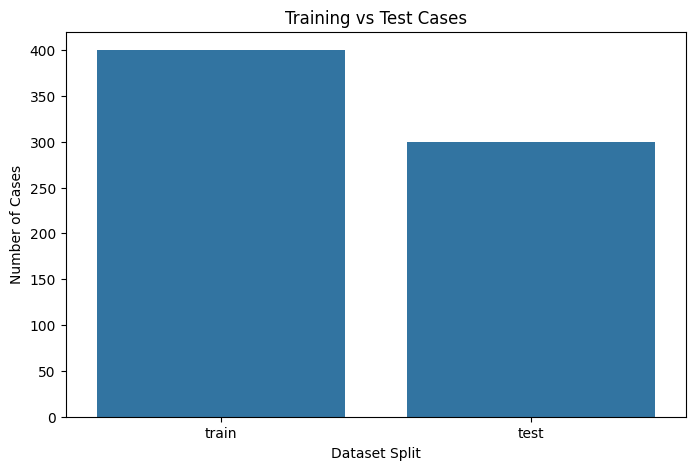

split
train    400
test     300
Name: count, dtype: int64


In [113]:
# ============================================================
# SECTION 4.1: CASE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=cases_df,
    x="split"
)

plt.title("Training vs Test Cases")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Cases")

plt.show()

print(cases_df["split"].value_counts())

## **4.2 Data tier distribution**

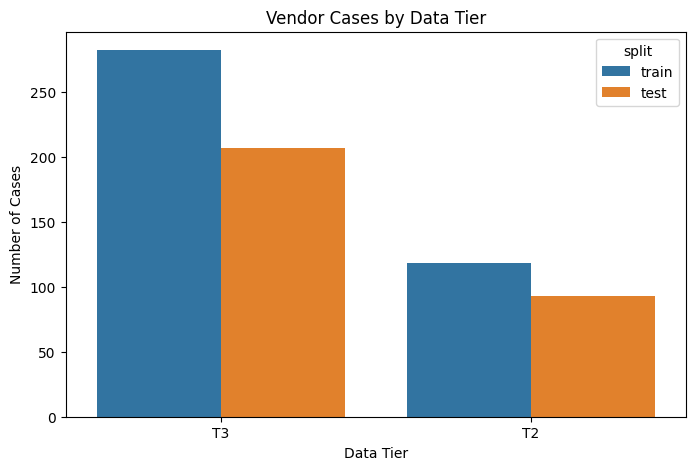

In [114]:
# ============================================================
# SECTION 4.2: DATA TIER DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=cases_df,
    x="tier",
    hue="split"
)

plt.title("Vendor Cases by Data Tier")
plt.xlabel("Data Tier")
plt.ylabel("Number of Cases")

plt.show()

## **4.3 Evidence source distribution**

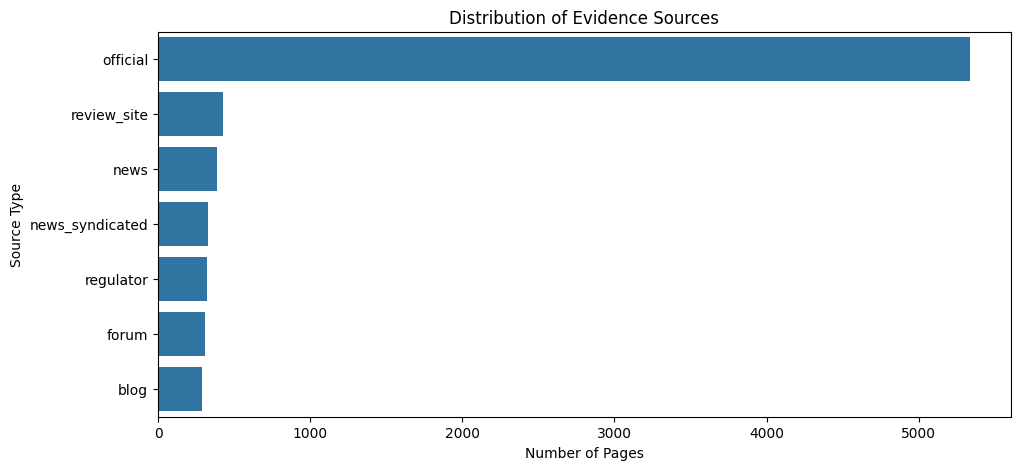

,count
source_type,
official,5337
review_site,429
news,385
news_syndicated,327
regulator,321
forum,311
blog,286


In [115]:
# ============================================================
# SECTION 4.3: EVIDENCE SOURCE DISTRIBUTION
# ============================================================

plt.figure(figsize=(11, 5))

sns.countplot(
    data=pages_df,
    y="source_type",
    order=pages_df["source_type"].value_counts().index
)

plt.title("Distribution of Evidence Sources")
plt.xlabel("Number of Pages")
plt.ylabel("Source Type")

plt.show()

display(
    pages_df["source_type"].value_counts().to_frame("count")
)

## **4.4 Pages per vendor**

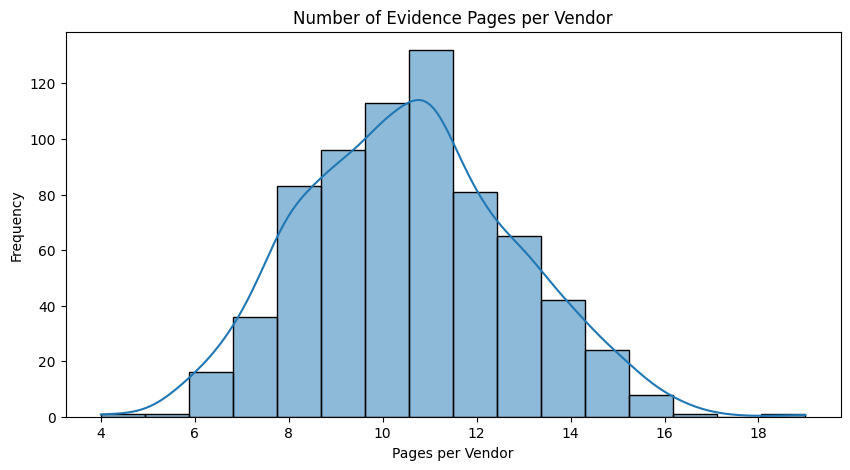

count    700.000000
mean      10.565714
std        2.261824
min        4.000000
25%        9.000000
50%       11.000000
75%       12.000000
max       19.000000
Name: page_count, dtype: float64


In [116]:
# ============================================================
# SECTION 4.4: PAGES PER VENDOR
# ============================================================

page_counts = (
    pages_df.groupby("case_id")
    .size()
    .reset_index(name="page_count")
)

plt.figure(figsize=(10, 5))

sns.histplot(
    page_counts["page_count"],
    bins=16,
    kde=True
)

plt.title("Number of Evidence Pages per Vendor")
plt.xlabel("Pages per Vendor")
plt.ylabel("Frequency")

plt.show()

print(page_counts["page_count"].describe())

## **4.5 Gold verdict distribution**

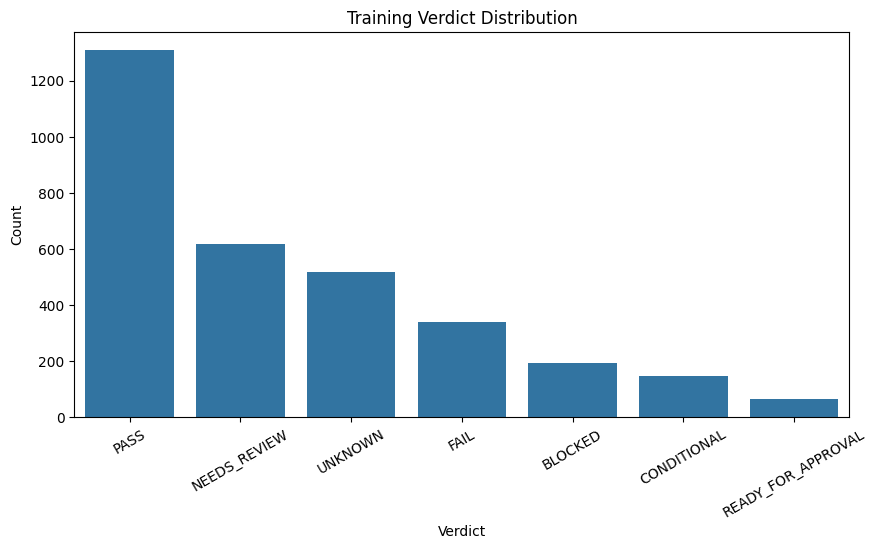

verdict
PASS                  1308
NEEDS_REVIEW           619
UNKNOWN                518
FAIL                   340
BLOCKED                191
CONDITIONAL            146
READY_FOR_APPROVAL      63
Name: count, dtype: int64

In [117]:
# ============================================================
# SECTION 4.5: TRAINING LABEL DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_labels_df,
    x="verdict",
    order=train_labels_df["verdict"].value_counts().index
)

plt.title("Training Verdict Distribution")
plt.xlabel("Verdict")
plt.ylabel("Count")

plt.xticks(rotation=30)

plt.show()

display(
    train_labels_df["verdict"].value_counts()
)

# **Section 5 — Policy Requirements Analysis**
Objective: Understand what each security requirement checks and when it applies.

This is a very important section because not all 10 requirements apply to every vendor.

The competition's policy file defines:
- Requirement ID.
- Requirement title.
- Evidence field.
- Deterministic rule.
- Rule parameters.
- Severity.
- Applicability conditions.

## **5.1 Load and understand the requirements**

In [118]:
# ============================================================
# SECTION 5.1: POLICY REQUIREMENTS ANALYSIS
# ============================================================

requirements_df = pd.DataFrame(requirements)

requirements_view = requirements_df[
    [
        "id",
        "title",
        "field",
        "rule",
        "severity",
        "applies_when"
    ]
].copy()

display(requirements_view.head(5))

,id,title,field,rule,severity,applies_when
0,SEC-4.2,Independent security assurance (SOC 2 Type II ...,security_certifications,certification_valid,blocker,"{'tiers': ['T3'], 'or_min_users': None}"
1,SEC-4.2-T2,Security assurance for internal-data tools (Ty...,security_certifications,certification_valid,major,"{'tiers': ['T2'], 'or_min_users': None}"
2,DP-3.1,Customer data stored in India,data_regions,region_includes,blocker,"{'tiers': ['T3'], 'or_min_users': None}"
3,DP-3.2,Storage region recorded (internal data),data_regions,value_known,minor,"{'tiers': ['T2'], 'or_min_users': None}"
4,AI-2.1,No training on Nimbu Mart data,trains_on_customer_data,enum_verdict,blocker,"{'tiers': ['T2', 'T3'], 'or_min_users': None}"


## **5.2 Analyze requirement severity**

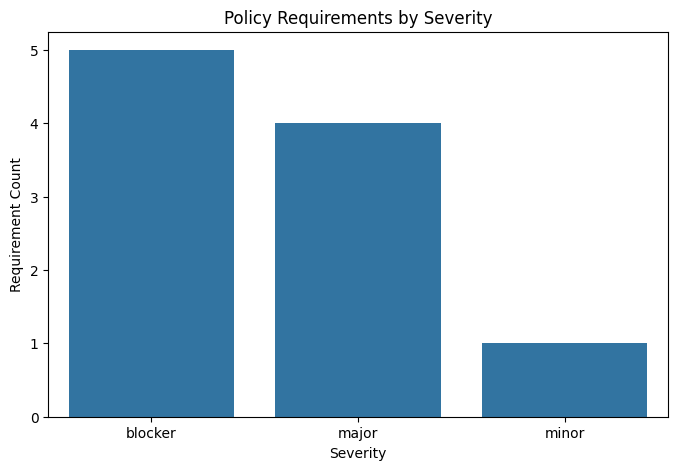

severity
blocker    5
major      4
minor      1
Name: count, dtype: int64


In [119]:
# ============================================================
# SECTION 5.2: REQUIREMENT SEVERITY
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=requirements_df,
    x="severity",
    order=["blocker", "major", "minor"]
)

plt.title("Policy Requirements by Severity")
plt.xlabel("Severity")
plt.ylabel("Requirement Count")

plt.show()

print(requirements_df["severity"].value_counts())

### Severity Interpretation

| Severity | Meaning |
|:---------|:--------|
| 🔴 **Blocker** | Serious policy violation that can block approval. |
| 🟠 **Major** | Significant issue that may make approval conditional. |
| 🟡 **Minor** | Lower-severity policy requirement that needs attention but may not prevent approval. |

## **5.3 Analyze requirement applicability**

In [120]:
# ============================================================
# SECTION 5.3: REQUIREMENT APPLICABILITY
# ============================================================

# Load official rule engine
sys.path.insert(0, DATA_DIR)

import rules_lite as rl

applicability_rows = []

for _, case in cases_df.iterrows():

    for req in requirements:

        applies = rl.applies(
            req,
            case["tier"],
            int(case["users"])
        )

        applicability_rows.append({
            "case_id": case["case_id"],
            "split": case["split"],
            "tier": case["tier"],
            "users": int(case["users"]),
            "requirement_id": req["id"],
            "requirement": req["title"],
            "applies": applies
        })

applicability_df = pd.DataFrame(
    applicability_rows
)

display(
    applicability_df.head(5)
)

print("\nApplicable requirement counts:")

display(
    applicability_df.groupby(
        ["requirement_id", "requirement"]
    )["applies"]
    .sum()
    .reset_index()
    .sort_values("applies", ascending=False)
)

,case_id,split,tier,users,requirement_id,requirement,applies
0,c0001,train,T3,120,SEC-4.2,Independent security assurance (SOC 2 Type II ...,True
1,c0001,train,T3,120,SEC-4.2-T2,Security assurance for internal-data tools (Ty...,False
2,c0001,train,T3,120,DP-3.1,Customer data stored in India,True
3,c0001,train,T3,120,DP-3.2,Storage region recorded (internal data),False
4,c0001,train,T3,120,AI-2.1,No training on Nimbu Mart data,True



Applicable requirement counts:


,requirement_id,requirement,applies
0,AI-2.1,No training on Nimbu Mart data,700
1,AI-3.4,Sub-processors disclosed; model providers iden...,700
8,SEC-7.1,Single sign-on (SAML / OIDC),596
2,DP-2.2,Data Processing Agreement available,489
5,DP-5.4,Deletion within 30 days of contract end or req...,489
3,DP-3.1,Customer data stored in India,489
9,SEC-9.3,No major incident in 24 months without a publi...,489
6,SEC-4.2,Independent security assurance (SOC 2 Type II ...,489
4,DP-3.2,Storage region recorded (internal data),211
7,SEC-4.2-T2,Security assurance for internal-data tools (Ty...,211


## **5.4 Visualize applicability**

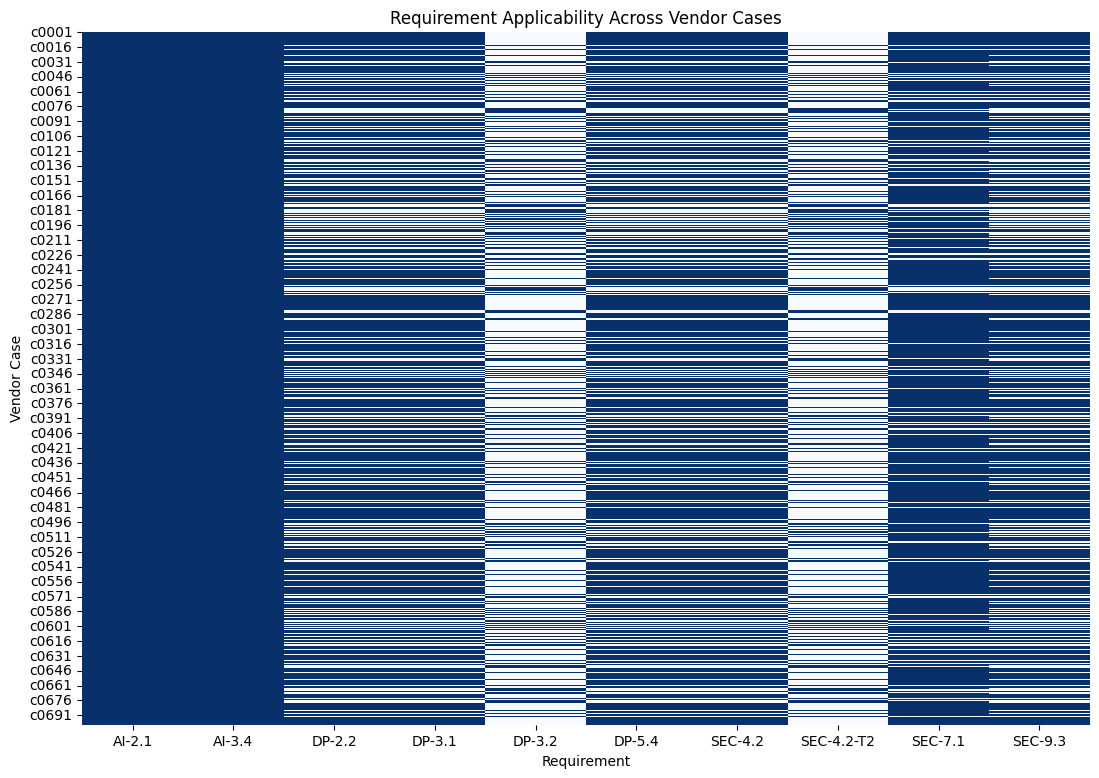

In [121]:
applicability_matrix = applicability_df.pivot(
    index="case_id",
    columns="requirement_id",
    values="applies"
)

plt.figure(figsize=(13, 9))

sns.heatmap(
    applicability_matrix.astype(int),
    cmap="Blues",
    cbar=False
)

plt.title("Requirement Applicability Across Vendor Cases")
plt.xlabel("Requirement")
plt.ylabel("Vendor Case")

plt.show()

# **Section 6 — Evidence Filtering and Source Validation**

**Objective:** Select only admissible evidence before extracting facts.

This is the most important part of the competition.

The competition evidence policy defines the following five rules:

1. **Official Vendor Domain Only:** Only the vendor's own official domain can establish vendor facts.

2. **Legal Entity Matching:** Certificate registry evidence must match the vendor's legal entity.

3. **Newest Official Evidence Wins:** When official pages disagree, the newest official page takes precedence.

4. **As-of Date Validation:** Pages published or updated after the case's as-of date must not be used as evidence.

5. **Prompt Injection Protection:** Instructions embedded within web pages or documents must never be obeyed. Treat page content strictly as evidence, not as instructions.

## **6.1 Import the existing solution**

In [122]:
# ============================================================
# SECTION 6.1: LOAD EVIDENCE EXTRACTION ENGINE
# ============================================================

# Load competition solution module
spec = importlib.util.spec_from_file_location(
    "vendor_verdict_solution",
    SCRIPT_PATH
)

vendor_solution = importlib.util.module_from_spec(spec)

sys.modules["vendor_verdict_solution"] = vendor_solution

spec.loader.exec_module(vendor_solution)

print("Evidence extraction engine loaded successfully")

# ------------------------------------------------------------
# Inspect available functions and attributes
# ------------------------------------------------------------

print("\nAvailable functions:")

for name, obj in inspect.getmembers(vendor_solution, inspect.isfunction):
    print(f" - {name}{inspect.signature(obj)}")

print("\nAvailable classes:")

for name, obj in inspect.getmembers(vendor_solution, inspect.isclass):
    print(f" - {name}")

print("\nRules-related attributes:")

for name in dir(vendor_solution):
    if "rule" in name.lower() or "load" in name.lower():
        print(f" - {name}")

print("\nModule inspection completed.")

Evidence extraction engine loaded successfully

Available functions:
 - admissible_vendor_pages(pages, case, as_of)
 - clean_lines(text)
 - country_mentions(text)
 - extract_facts(case, pages)
 - host_of(url)
 - is_vendor_domain(page, case)
 - latest_page_with(pages, pattern)
 - load_inputs(data_dir)
 - main()
 - make_predictions(data_dir)
 - page_date(page)
 - parse_certifications(vendor_pages, all_pages, case, as_of)
 - parse_date(value, default=None)
 - parse_days(line)
 - parse_dpa(pages)
 - parse_fact_regions(pages)
 - parse_incidents(pages)
 - parse_retention(pages)
 - parse_sso(pages)
 - parse_subprocessors(pages)
 - parse_training(pages)
 - urlparse(url, scheme='', allow_fragments=True)
 - validate_train(data_dir, holdout_fraction=0.2, seed=42)
 - write_submission(rows, out_path)

Available classes:
 - Counter
 - Path
 - date
 - datetime
 - defaultdict

Rules-related attributes:
 - __loader__
 - load_inputs

Module inspection completed.


## **6.2 Build pages grouped by vendor**

In [123]:
# ============================================================
# SECTION 6.2: GROUP EVIDENCE BY CASE
# ============================================================

pages_by_case = defaultdict(list)

for page in pages:

    pages_by_case[page["case_id"]].append(page)

cases_by_id = {
    row["case_id"]: row.to_dict()
    for _, row in cases_df.iterrows()
}

print("Cases indexed:", len(cases_by_id))
print("Evidence groups:", len(pages_by_case))

sample_id = cases_df.iloc[0]["case_id"]

print("Sample case:", sample_id)
print("Evidence pages:", len(pages_by_case[sample_id]))

Cases indexed: 700
Evidence groups: 700
Sample case: c0001
Evidence pages: 11


## **6.3 Filter official pages**

In [124]:
# ============================================================
# SECTION 6.3: OFFICIAL DOMAIN VALIDATION
# ============================================================

official_evidence = []

for case_id, case in cases_by_id.items():

    case_pages = pages_by_case[case_id]

    as_of = vendor_solution.parse_date(
        case.get("as_of"),
        vendor_solution.AS_OF_DEFAULT
    )

    trusted_pages = (
        vendor_solution.admissible_vendor_pages(
            case_pages,
            case,
            as_of
        )
    )

    for page in trusted_pages:

        official_evidence.append({
            "case_id": case_id,
            "vendor": case["vendor"],
            "official_domain": case["official_domain"],
            "page_id": page.get("page_id"),
            "url": page.get("url"),
            "last_updated": page.get("last_updated"),
            "title": page.get("title"),
            "source_type": page.get("source_type"),
            "trusted": True
        })

official_evidence_df = pd.DataFrame(
    official_evidence
)

print("Trusted official pages:", len(official_evidence_df))

display(official_evidence_df.head(5))

Trusted official pages: 5020


,case_id,vendor,official_domain,page_id,url,last_updated,title,source_type,trusted
0,c0001,Yarrabase,yarrabase.example,c0001-p10,https://yarrabase.example/about,2026-10-09,About Yarrabase,official,True
1,c0001,Yarrabase,yarrabase.example,c0001-p06,https://blog.yarrabase.example/2025/news,2026-10-08,Yarrabase company news,official,True
2,c0001,Yarrabase,yarrabase.example,c0001-p01,https://yarrabase.example/pricing,2026-08-25,Yarrabase Pricing and plans,official,True
3,c0001,Yarrabase,yarrabase.example,c0001-p02,https://status.yarrabase.example/history,2026-07-31,Yarrabase Status and incident history,official,True
4,c0001,Yarrabase,yarrabase.example,c0001-p08,https://help.yarrabase.example/articles/security,2026-07-26,Yarrabase Help Center: security and admin,official,True


## **6.4 Analyze trusted versus untrusted pages**

In [125]:
# ============================================================
# SECTION 6.4: TRUSTED VS UNTRUSTED PAGE ANALYSIS
# ============================================================

trusted_counts = (
    official_evidence_df.groupby("case_id")
    .size()
    .rename("trusted_pages")
)

all_counts = (
    pages_df.groupby("case_id")
    .size()
    .rename("total_pages")
)

evidence_quality_df = pd.concat(
    [all_counts, trusted_counts],
    axis=1
).fillna(0)

evidence_quality_df["untrusted_pages"] = (
    evidence_quality_df["total_pages"]
    - evidence_quality_df["trusted_pages"]
)

evidence_quality_df["trusted_percentage"] = (
    evidence_quality_df["trusted_pages"]
    / evidence_quality_df["total_pages"]
    * 100
)

display(evidence_quality_df.head(5))

print("\nAverage trusted evidence percentage:")

print(
    evidence_quality_df["trusted_percentage"].mean()
)

,total_pages,trusted_pages,untrusted_pages,trusted_percentage
case_id,,,,
c0001,11,7,4,63.636364
c0002,13,8,5,61.538462
c0003,11,5,6,45.454545
c0004,11,8,3,72.727273
c0005,9,6,3,66.666667



Average trusted evidence percentage:
69.48140257697976


## **6.5 Check page injection attempts**

In [126]:
# ============================================================
# SECTION 6.5: PROMPT INJECTION DETECTION
# ============================================================

injection_pattern = vendor_solution.INJECTION_RE

injection_results = []

for page in pages:

    text = page.get("text", "")

    matches = injection_pattern.findall(text)

    injection_results.append({
        "case_id": page["case_id"],
        "page_id": page["page_id"],
        "source_type": page["source_type"],
        "injection_detected": len(matches) > 0
    })

injection_df = pd.DataFrame(injection_results)

print("Pages containing detected injection patterns:")

print(
    injection_df["injection_detected"].sum()
)

display(
    injection_df[
        injection_df["injection_detected"]
    ].head(10)
)

Pages containing detected injection patterns:
97


,case_id,page_id,source_type,injection_detected
109,c0011,c0011-p03,blog,True
170,c0017,c0017-p03,blog,True
245,c0024,c0024-p04,blog,True
258,c0025,c0025-p09,blog,True
319,c0031,c0031-p03,blog,True
460,c0045,c0045-p02,blog,True
500,c0048,c0048-p08,blog,True
570,c0055,c0055-p06,blog,True
705,c0067,c0067-p08,blog,True
874,c0083,c0083-p01,blog,True


# **Section 7 — Structured Fact Extraction**

**Objective:** Convert unstructured web pages into structured evidence facts.

This stage transforms information collected from official vendor sources into machine-readable evidence that can be consumed by the competition's rules engine.

The official rules engine expects the following eight evidence fields:

| Evidence Field | What We Extract |
|---|---|
| `security_certifications` | Security certifications such as SOC 2 and ISO 27001. |
| `data_regions` | Available and planned data hosting regions. |
| `trains_on_customer_data` | Vendor's policy on using customer data for model training. |
| `subprocessors` | Third-party service providers involved in processing customer data. |
| `data_retention` | Data retention and deletion periods. |
| `sso_saml` | Availability and support for Single Sign-On (SSO) and SAML authentication. |
| `security_incidents` | Reported security incidents and published post-mortems. |
| `dpa_available` | Availability of a Data Processing Agreement (DPA). |

### Key Extraction Principles

1. Extract only facts supported by admissible evidence.
2. Preserve the original meaning of the source content.
3. Capture the official source URL for every extracted fact.
4. Record the publication or last-updated date whenever available.
5. Do not infer missing information or assume unsupported capabilities.
6. Represent unavailable or unconfirmed information as `UNKNOWN`.
7. Keep extracted facts in a structured JSON format for downstream validation.

**Expected Output:** A structured evidence record containing all eight fields, their extracted values, supporting source references, and evidence metadata.

## **7.1 Extract facts for one vendor**

In [127]:
# ============================================================
# SECTION 7.1: SAMPLE VENDOR FACT EXTRACTION
# ============================================================

sample_case_id = cases_df[
    cases_df["split"] == "test"
].iloc[0]["case_id"]

sample_case = cases_by_id[sample_case_id]

sample_pages = pages_by_case[sample_case_id]

sample_facts = vendor_solution.extract_facts(
    sample_case,
    sample_pages
)

print("Vendor:", sample_case["vendor"])

print("\nExtracted facts:")

print(
    json.dumps(
        sample_facts,
        indent=4,
        default=str
    )
)

Vendor: Garnforge AI

Extracted facts:
{
    "security_certifications": {
        "value": [
            {
                "name": "SOC 2",
                "status": "certified",
                "date": null,
                "valid_until": null
            }
        ],
        "evidence_level": "claimed"
    },
    "trains_on_customer_data": {
        "value": "no"
    },
    "sso_saml": {
        "value": "enterprise_only"
    },
    "security_incidents": {
        "value": []
    },
    "dpa_available": {
        "value": "yes"
    }
}


## **7.2 Extract facts for all cases**

In [128]:
# ============================================================
# SECTION 7.2: EXTRACT FACTS FOR ALL CASES
# ============================================================

all_case_facts = {}

for case_id, case in cases_by_id.items():

    facts = vendor_solution.extract_facts(
        case,
        pages_by_case[case_id]
    )

    all_case_facts[case_id] = facts

print("Total cases processed:", len(all_case_facts))

print("Sample facts:")

print(
    json.dumps(
        all_case_facts[sample_case_id],
        indent=4,
        default=str
    )
)

Total cases processed: 700
Sample facts:
{
    "security_certifications": {
        "value": [
            {
                "name": "SOC 2",
                "status": "certified",
                "date": null,
                "valid_until": null
            }
        ],
        "evidence_level": "claimed"
    },
    "trains_on_customer_data": {
        "value": "no"
    },
    "sso_saml": {
        "value": "enterprise_only"
    },
    "security_incidents": {
        "value": []
    },
    "dpa_available": {
        "value": "yes"
    }
}


## **7.3 Analyze extracted fact coverage**

In [129]:
# ============================================================
# SECTION 7.3: FACT EXTRACTION COVERAGE
# ============================================================

def has_extracted_fact(field, item):

    if not isinstance(item, dict):
        return False

    value = item.get("value")

    if field == "security_certifications":
        return bool(value)

    if field == "data_regions":
        return bool(
            value
            and (
                value.get("available")
                or value.get("planned")
            )
        )

    if field == "data_retention":
        return bool(
            value
            and any(v is not None for v in value.values())
        )

    if field == "security_incidents":
        # An empty list can represent an explicitly
        # documented absence of incidents.
        return isinstance(value, list)

    if field == "subprocessors":
        return bool(value)

    return value is not None
    
FACT_FIELDS = [
    "security_certifications",
    "data_regions",
    "trains_on_customer_data",
    "subprocessors",
    "data_retention",
    "sso_saml",
    "security_incidents",
    "dpa_available"
]

coverage_rows = []

for case_id, facts in all_case_facts.items():

    row = {"case_id": case_id}

    for field in FACT_FIELDS:
        row[field] = has_extracted_fact(
            field,
            facts.get(field)
        )

    coverage_rows.append(row)

fact_coverage_df = pd.DataFrame(coverage_rows)

display(fact_coverage_df.head(10))

coverage_summary = pd.DataFrame({
    "field": FACT_FIELDS,
    "extracted_cases": [
        int(fact_coverage_df[field].sum())
        for field in FACT_FIELDS
    ]
})

coverage_summary["coverage_percentage"] = (
    coverage_summary["extracted_cases"]
    / len(cases_df)
    * 100
)

display(
    coverage_summary.sort_values(
        "coverage_percentage",
        ascending=False
    )
)

,case_id,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
0,c0001,False,True,True,False,True,False,True,True
1,c0002,True,False,True,False,False,True,True,True
2,c0003,True,True,True,True,False,False,False,True
3,c0004,True,True,True,True,False,True,True,True
4,c0005,True,True,False,True,True,False,False,True
5,c0006,True,True,True,True,True,True,True,False
6,c0007,False,True,False,True,True,False,True,True
7,c0008,True,True,True,True,False,True,False,False
8,c0009,True,True,False,False,False,False,True,True
9,c0010,True,False,True,True,True,False,True,False


,field,extracted_cases,coverage_percentage
0,security_certifications,584,83.428571
1,data_regions,552,78.857143
3,subprocessors,552,78.857143
6,security_incidents,523,74.714286
7,dpa_available,503,71.857143
2,trains_on_customer_data,478,68.285714
4,data_retention,470,67.142857
5,sso_saml,448,64.000000


## **7.4 Visualize evidence extraction coverage**

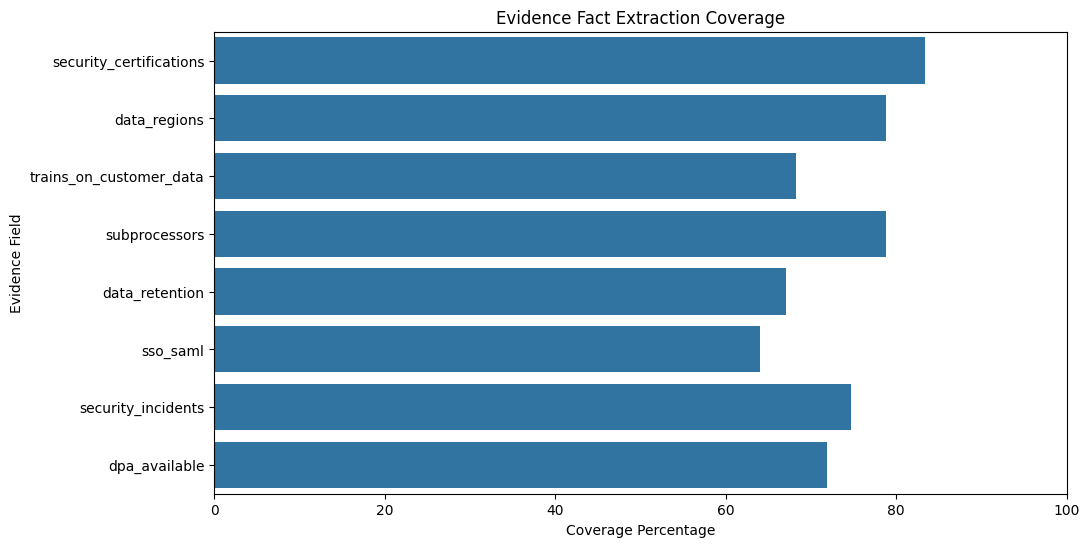

In [130]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=coverage_summary,
    x="coverage_percentage",
    y="field"
)

plt.title("Evidence Fact Extraction Coverage")
plt.xlabel("Coverage Percentage")
plt.ylabel("Evidence Field")

plt.xlim(0, 100)

plt.show()

# **Section 8 — Deterministic Verdict Engine**

**Objective:** Convert extracted facts into policy verdicts using the competition's original deterministic rules.

This stage evaluates structured evidence facts against predefined policy rules to generate consistent and reproducible compliance verdicts.

**Important:** This is not a Machine Learning classifier. The competition explicitly states that the gold labels were generated using this deterministic rules engine.

### Verdict Generation Workflow

The process follows four sequential stages:

1. **Evidence:** Collect admissible vendor evidence.
2. **Facts:** Extract structured facts from the evidence.
3. **Policy Rules:** Apply the competition's deterministic rules.
4. **Verdict:** Generate the final compliance decision.   

**Evidence → Facts → Policy Rules → Verdict**

### Key Principles

1. **Deterministic Evaluation:** Apply the original competition rules without introducing random behavior.
2. **Rule-Based Validation:** Evaluate extracted facts against predefined policy conditions.
3. **Evidence-Driven Decisions:** Every verdict must be supported by admissible evidence.
4. **Consistent Results:** Identical inputs must always produce identical verdicts.
5. **Unknown Handling:** Missing or unverified evidence must be handled according to the original rules.
6. **No ML-Based Prediction:** Do not train or use an ML model to predict the final verdict.

### Expected Output

The verdict engine generates a policy-based decision for each vendor or case, using the competition's original verdict categories.

**Goal:** Reproduce the competition's original deterministic verdict logic as accurately as possible.

## **8.1 Load the original rules engine**

In [131]:
# ============================================================
# SECTION 8.1: LOAD OFFICIAL DETERMINISTIC RULES
# ============================================================

#import importlib.util
#import sys

RULES_PATH = os.path.join(DATA_DIR, "rules_lite.py")

spec = importlib.util.spec_from_file_location(
    "competition_rules",
    RULES_PATH
)

rl = importlib.util.module_from_spec(spec)
sys.modules["competition_rules"] = rl
spec.loader.exec_module(rl)

print("Available requirement verdicts:")
print(rl.VERDICTS)

print("\nAvailable overall verdicts:")
print(rl.OVERALL)

print("\nAvailable rules:")
print(list(rl.RULES.keys()))

Available requirement verdicts:
('PASS', 'FAIL', 'UNKNOWN', 'NEEDS_REVIEW')

Available overall verdicts:
('BLOCKED', 'CONDITIONAL', 'READY_FOR_APPROVAL')

Available rules:
['certification_valid', 'region_includes', 'value_known', 'enum_verdict', 'list_disclosed', 'retention_within', 'no_unresolved_incident']


## **8.2 Evaluate a sample vendor**

In [132]:
# ============================================================
# SECTION 8.2: EVALUATE SAMPLE VENDOR
# ============================================================

sample_case = cases_by_id[sample_case_id]

sample_facts = all_case_facts[sample_case_id]

sample_verdicts = rl.evaluate(
    facts=sample_facts,
    requirements=requirements,
    tier=sample_case["tier"],
    users=int(sample_case["users"]),
    as_of=sample_case["as_of"]
)

sample_overall = rl.overall(
    sample_verdicts,
    requirements
)

print("Vendor:", sample_case["vendor"])
print("Tier:", sample_case["tier"])
print("Users:", sample_case["users"])

print("\nRequirement verdicts:")

for requirement_id, verdict in sample_verdicts.items():
    print(requirement_id, ":", verdict)

print("\nOverall verdict:", sample_overall)

Vendor: Garnforge AI
Tier: T3
Users: 25

Requirement verdicts:
SEC-4.2 : NEEDS_REVIEW
DP-3.1 : UNKNOWN
AI-2.1 : PASS
AI-3.4 : UNKNOWN
DP-5.4 : UNKNOWN
SEC-7.1 : NEEDS_REVIEW
SEC-9.3 : PASS
DP-2.2 : PASS

Overall verdict: CONDITIONAL


## **8.3 Create a readable assessment report**

In [133]:
# ============================================================
# SECTION 8.3: VENDOR ASSESSMENT REPORT
# ============================================================

requirement_lookup = {
    r["id"]: r for r in requirements
}

assessment_rows = []

for rid, verdict in sample_verdicts.items():

    req = requirement_lookup[rid]

    assessment_rows.append({
        "requirement_id": rid,
        "requirement": req["title"],
        "severity": req["severity"],
        "evidence_field": req["field"],
        "rule": req["rule"],
        "verdict": verdict
    })

assessment_df = pd.DataFrame(assessment_rows)

display(assessment_df)

print("\nOVERALL RESULT:", sample_overall)

,requirement_id,requirement,severity,evidence_field,rule,verdict
0,SEC-4.2,Independent security assurance (SOC 2 Type II ...,blocker,security_certifications,certification_valid,NEEDS_REVIEW
1,DP-3.1,Customer data stored in India,blocker,data_regions,region_includes,UNKNOWN
2,AI-2.1,No training on Nimbu Mart data,blocker,trains_on_customer_data,enum_verdict,PASS
3,AI-3.4,Sub-processors disclosed; model providers iden...,major,subprocessors,list_disclosed,UNKNOWN
4,DP-5.4,Deletion within 30 days of contract end or req...,major,data_retention,retention_within,UNKNOWN
5,SEC-7.1,Single sign-on (SAML / OIDC),major,sso_saml,enum_verdict,NEEDS_REVIEW
6,SEC-9.3,No major incident in 24 months without a publi...,blocker,security_incidents,no_unresolved_incident,PASS
7,DP-2.2,Data Processing Agreement available,blocker,dpa_available,enum_verdict,PASS



OVERALL RESULT: CONDITIONAL


## **8.4 Understand Overall Decision Logic**

The official `rules_lite.overall()` function determines the final vendor approval verdict based on the severity and status of individual requirements.

### Overall Verdict Decision Rules

| Condition | Overall Verdict |
|---|---|
| Blocker requirement fails | 🔴 **BLOCKED** |
| Major requirement fails | 🟠 **CONDITIONAL** |
| Any requirement is `UNKNOWN` or `NEEDS_REVIEW` | 🟠 **CONDITIONAL** |
| No blocking or conditional issues | 🟢 **READY_FOR_APPROVAL** |

### Key Decision Principles

1. **BLOCKED:** A failed blocker requirement prevents approval.
2. **CONDITIONAL:** A failed major requirement requires additional action or remediation.
3. **CONDITIONAL:** Unknown or unresolved requirements prevent unconditional approval.
4. **READY_FOR_APPROVAL:** All requirements satisfy the applicable policy rules without blocking or conditional issues.

### Important Implementation Rule

Always use the competition's original `rl.overall()` function to calculate the final verdict.

Do not create custom overall prediction logic or independently reproduce the decision rules.

**Reason:** The competition's gold labels were generated using the official deterministic rules engine. Using `rl.overall()` ensures consistency with the original evaluation logic.

# **Section 9 — Training Holdout Validation**

**Objective:** Measure how accurately the evidence extraction pipeline and deterministic rules engine reproduce the gold-standard training labels.

The competition provides **400 training cases**. We will divide these cases into development and validation datasets to evaluate the solution's performance.

### Dataset Split Strategy

| Dataset | Number of Cases | Percentage |
|---|---:|---:|
| Development Set | 320 | 80% |
| Validation Set | 80 | 20% |
| **Total** | **400** | **100%** |

### Configuration

- **Random Seed:** `42`
- **Development Cases:** `320`
- **Validation Cases:** `80`
- **Split Strategy:** Based on `case_id`.

### Important Data Leakage Prevention

We split the dataset by `case_id`, not by individual requirement rows.

This is important because:

1. A single vendor case can contain multiple policy requirements.
2. All requirements belonging to the same case must remain in the same dataset.
3. Splitting individual requirement rows could introduce data leakage.
4. Data leakage can produce misleadingly high validation performance.
5. Keeping cases separate ensures a more reliable evaluation.

### Validation Objective

Evaluate the solution using the validation dataset to measure:

- Overall verdict accuracy.
- Requirement-level prediction accuracy.
- Agreement with gold-standard labels.
- Confusion matrix and classification performance.
- Evidence extraction and policy evaluation consistency.

**Expected Outcome:** A reliable estimate of how accurately the evidence extraction and deterministic verdict engine reproduce the competition's gold-standard labels on unseen cases.

## 9.1 Create a reproducible holdout split

In [134]:
# ============================================================
# SECTION 9.1: TRAINING HOLDOUT SPLIT
# ============================================================

train_case_ids = sorted(
    cases_df.loc[
        cases_df["split"] == "train",
        "case_id"
    ].tolist()
)

rng = random.Random(42)

shuffled_ids = train_case_ids.copy()

rng.shuffle(shuffled_ids)

holdout_size = round(
    len(shuffled_ids) * 0.20
)

holdout_case_ids = set(
    shuffled_ids[:holdout_size]
)

development_case_ids = set(
    shuffled_ids[holdout_size:]
)

print("Total training cases:", len(train_case_ids))
print("Development cases:", len(development_case_ids))
print("Validation cases:", len(holdout_case_ids))

Total training cases: 400
Development cases: 320
Validation cases: 80


## **9.2 Generate validation predictions**

In [135]:
# ============================================================
# SECTION 9.2: GENERATE HOLDOUT PREDICTIONS
# ============================================================

holdout_predictions = []
holdout_cache = {}

for case_id in holdout_case_ids:

    case = cases_by_id[case_id]

    facts = all_case_facts[case_id]

    verdicts = rl.evaluate(
        facts,
        requirements,
        case["tier"],
        int(case["users"]),
        case["as_of"]
    )

    overall = rl.overall(
        verdicts,
        requirements
    )

    holdout_cache[case_id] = {
        "facts": facts,
        "verdicts": verdicts,
        "overall": overall
    }

# Gold labels belonging to holdout cases
holdout_gold_df = train_labels_df[
    train_labels_df["case_id"].isin(
        holdout_case_ids
    )
].copy()

# Map predictions to the exact gold IDs
for _, row in holdout_gold_df.iterrows():

    case_id = row["case_id"]
    requirement_id = row["requirement_id"]

    cached = holdout_cache[case_id]

    if requirement_id == "OVERALL":
        predicted = cached["overall"]
    else:
        predicted = cached["verdicts"].get(
            requirement_id,
            "UNKNOWN"
        )

    holdout_predictions.append({
        "id": row["id"],
        "predicted_verdict": predicted
    })

holdout_predictions_df = pd.DataFrame(
    holdout_predictions
)

holdout_results_df = holdout_gold_df.merge(
    holdout_predictions_df,
    on="id",
    how="inner"
)

print("Holdout prediction rows:", len(holdout_results_df))

display(holdout_results_df.head(15))

Holdout prediction rows: 624


,id,case_id,requirement_id,verdict,predicted_verdict
0,c0006__SEC-4.2,c0006,SEC-4.2,PASS,PASS
1,c0006__DP-3.1,c0006,DP-3.1,FAIL,FAIL
2,c0006__AI-2.1,c0006,AI-2.1,NEEDS_REVIEW,NEEDS_REVIEW
3,c0006__AI-3.4,c0006,AI-3.4,PASS,PASS
4,c0006__DP-5.4,c0006,DP-5.4,NEEDS_REVIEW,NEEDS_REVIEW
5,c0006__SEC-7.1,c0006,SEC-7.1,FAIL,FAIL
6,c0006__SEC-9.3,c0006,SEC-9.3,PASS,PASS
7,c0006__DP-2.2,c0006,DP-2.2,UNKNOWN,UNKNOWN
8,c0006__OVERALL,c0006,OVERALL,BLOCKED,BLOCKED
9,c0022__SEC-4.2,c0022,SEC-4.2,PASS,PASS


## 1. Test Overall Accuracy

Overall accuracy measures the percentage of predictions that exactly match the actual verdict.

**Formula:**

Accuracy = Correct Predictions / Total Predictions

### Interpretation

- Higher accuracy indicates better prediction performance.
- Lower accuracy indicates more incorrect predictions.
- Accuracy provides an overall measure of agreement with the actual verdicts.

## 2. Test False-Confidence Rate

For this project, false confidence means the system gives a confident verdict (`PASS` or `FAIL`) when the actual answer is uncertain (`UNKNOWN` or `NEEDS_REVIEW`).

**Formula:**

FCR = Confident Predictions on Uncertain Cases / Total Uncertain Actual Cases

### Interpretation

- A lower False-Confidence Rate (FCR) is better.
- A high FCR indicates that the system is making confident predictions when the available evidence is insufficient.
- The system should avoid unsupported `PASS` or `FAIL` decisions.
- Uncertain evidence should be handled according to the competition's official rules.

**Goal:** Achieve high overall accuracy while minimizing false-confidence errors.

In [136]:

# ============================================================
# SECTION 9.2.1: HOLDOUT ACCURACY & FALSE-CONFIDENCE RATE
# ============================================================


# Actual and predicted verdicts
y_true = holdout_results_df["verdict"].astype(str)
y_pred = holdout_results_df["predicted_verdict"].astype(str)

# ------------------------------------------------------------
# 1. Overall Accuracy
# ------------------------------------------------------------

overall_accuracy = accuracy_score(y_true, y_pred)

# ------------------------------------------------------------
# 2. False-Confidence Rate
# Actual uncertain but model predicts PASS or FAIL
# ------------------------------------------------------------

uncertain_labels = ["UNKNOWN", "NEEDS_REVIEW"]
confident_labels = ["PASS", "FAIL"]

actual_uncertain = y_true.isin(uncertain_labels)
predicted_confident = y_pred.isin(confident_labels)

uncertain_count = int(actual_uncertain.sum())

false_confident_count = int(
    (actual_uncertain & predicted_confident).sum()
)

false_confidence_rate = (
    false_confident_count / uncertain_count
    if uncertain_count > 0 else np.nan
)

# ------------------------------------------------------------
# 3. Display Results
# ------------------------------------------------------------

print("=" * 55)
print("HOLDOUT VALIDATION METRICS")
print("=" * 55)

print(f"Total Holdout Rows          : {len(holdout_results_df)}")
print(f"Overall Accuracy            : {overall_accuracy:.4%}")
print(f"False-Confidence Rate       : {false_confidence_rate:.4%}")
print(f"Actual Uncertain Rows       : {uncertain_count}")
print(f"False Confident Predictions : {false_confident_count}")

print("=" * 55)


HOLDOUT VALIDATION METRICS
Total Holdout Rows          : 624
Overall Accuracy            : 97.7564%
False-Confidence Rate       : 0.9390%
Actual Uncertain Rows       : 213
False Confident Predictions : 2


In [137]:

# ============================================================
# SECTION 9.2.2: REQUIREMENT vs OVERALL METRICS
# ============================================================

overall_mask = (
    holdout_results_df["requirement_id"] == "OVERALL"
)

requirement_df = holdout_results_df[~overall_mask].copy()
overall_df = holdout_results_df[overall_mask].copy()

print("REQUIREMENT-LEVEL ACCURACY:",
      f"{accuracy_score(requirement_df['verdict'], requirement_df['predicted_verdict']):.4%}"
      if len(requirement_df) else "N/A")

print("OVERALL CASE ACCURACY:",
      f"{accuracy_score(overall_df['verdict'], overall_df['predicted_verdict']):.4%}"
      if len(overall_df) else "N/A")


REQUIREMENT-LEVEL ACCURACY: 97.7941%
OVERALL CASE ACCURACY: 97.5000%


## **9.3 Calculate the official competition score**

In [138]:
# ============================================================
# SECTION 9.3: OFFICIAL VALIDATION SCORE
# ============================================================

metric_spec = importlib.util.spec_from_file_location(
    "vendor_metric",
    os.path.join(DATA_DIR, "metric.py")
)

vendor_metric = importlib.util.module_from_spec(
    metric_spec
)

metric_spec.loader.exec_module(vendor_metric)

solution_for_metric = (
    holdout_results_df[["id", "verdict"]]
    .copy()
)

prediction_for_metric = (
    holdout_results_df[["id", "predicted_verdict"]]
    .rename(
        columns={
            "predicted_verdict": "verdict"
        }
    )
)

score_components = vendor_metric.components(
    solution_for_metric,
    prediction_for_metric
)

print("HOLDOUT VALIDATION RESULTS")

for name, value in score_components.items():
    print(f"{name}: {value:.6f}")

HOLDOUT VALIDATION RESULTS
macro_f1: 0.971492
overall_accuracy: 0.975000
false_confidence_rate: 0.009390
score: 0.976017


## 9.4 Multi-seed validation

In [139]:
# ============================================================
# SECTION 9.4: MULTI-SEED VALIDATION
# ============================================================

def run_holdout(seed, fraction=0.20):

    ids = sorted(train_case_ids)

    random_generator = random.Random(seed)

    random_generator.shuffle(ids)

    n = max(1, round(len(ids) * fraction))

    selected = set(ids[:n])

    predictions = []
    gold = train_labels_df[
        train_labels_df["case_id"].isin(selected)
    ].copy()

    cache = {}

    for cid in selected:

        case = cases_by_id[cid]

        facts = all_case_facts[cid]

        verdicts = rl.evaluate(
            facts,
            requirements,
            case["tier"],
            int(case["users"]),
            case["as_of"]
        )

        cache[cid] = (
            verdicts,
            rl.overall(verdicts, requirements)
        )

    for _, row in gold.iterrows():

        cid = row["case_id"]
        rid = row["requirement_id"]

        verdicts, overall = cache[cid]

        pred = (
            overall if rid == "OVERALL"
            else verdicts.get(rid, "UNKNOWN")
        )

        predictions.append({
            "id": row["id"],
            "verdict": pred
        })

    pred_df = pd.DataFrame(predictions)

    gold_df = gold[["id", "verdict"]]

    return vendor_metric.components(
        gold_df,
        pred_df
    )


multi_seed_results = []

for seed in [21, 42, 100, 2026, 2027]:

    result = run_holdout(seed)

    result["seed"] = seed

    multi_seed_results.append(result)

multi_seed_df = pd.DataFrame(
    multi_seed_results
)

display(multi_seed_df)

,macro_f1,overall_accuracy,false_confidence_rate,score,seed
0,0.961494,0.9625,0.008850,0.967627,21
1,0.971492,0.9750,0.009390,0.976017,42
2,0.960247,0.9500,0.004695,0.965209,100
3,0.982882,0.9500,0.004808,0.978768,2026
4,0.965800,1.0000,0.015936,0.976292,2027


In [140]:
print("Average validation score:")

print(
    multi_seed_df["score"].mean()
)

print("Standard deviation:")

print(
    multi_seed_df["score"].std()
)

Average validation score:
0.9727825925095512
Standard deviation:
0.005969559547919414


**Interpretation**: A stable average with low standard deviation gives us more confidence than one unusually high split. These overlapping random splits are diagnostic, not independent test sets.

In [141]:

# ============================================================
# SECTION 9.5: REPRODUCE OFFICIAL KAGGLE SCORING METRIC
# ============================================================

REQ_LABELS = [
    "PASS", "FAIL", "UNKNOWN", "NEEDS_REVIEW"
]

# Separate requirement and overall rows
is_overall = holdout_results_df["id"].astype(str).str.endswith(
    "__OVERALL"
)

req_df = holdout_results_df[~is_overall].copy()
overall_df = holdout_results_df[is_overall].copy()

gold = req_df["verdict"].astype(str).str.strip().str.upper().to_numpy()
pred = req_df["predicted_verdict"].astype(str).str.strip().str.upper().to_numpy()

# ------------------------------------------------------------
# 1. Requirement Macro-F1 (same formula as metric.py)
# ------------------------------------------------------------

f1_scores = []

for label in REQ_LABELS:
    tp = int(((gold == label) & (pred == label)).sum())
    fp = int(((gold != label) & (pred == label)).sum())
    fn = int(((gold == label) & (pred != label)).sum())

    if tp + fp + fn == 0:
        continue

    f1 = 2 * tp / (2 * tp + fp + fn)
    f1_scores.append(f1)

macro_f1 = float(np.mean(f1_scores)) if f1_scores else 0.0

# ------------------------------------------------------------
# 2. Overall Accuracy
# ------------------------------------------------------------

overall_accuracy = (
    (
        overall_df["verdict"].astype(str).str.strip().str.upper()
        ==
        overall_df["predicted_verdict"].astype(str).str.strip().str.upper()
    ).mean()
    if len(overall_df) else 0.0
)

# ------------------------------------------------------------
# 3. False-Confidence Rate
# Requirement rows ONLY
# ------------------------------------------------------------

uncertain = np.isin(gold, ["UNKNOWN", "NEEDS_REVIEW"])

false_confident = np.isin(pred, ["PASS", "FAIL"])

false_confidence_rate = (
    float(false_confident[uncertain].mean())
    if uncertain.any() else 0.0
)

# ------------------------------------------------------------
# 4. Official Weighted Score
# ------------------------------------------------------------

official_score = (
    0.60 * macro_f1
    + 0.20 * overall_accuracy
    + 0.20 * (1 - false_confidence_rate)
)

# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------

print("=" * 65)
print("OFFICIAL KAGGLE HOLDOUT SCORING")
print("=" * 65)

print(f"Requirement Macro-F1       : {macro_f1:.6f}")
print(f"Overall Accuracy            : {overall_accuracy:.6f}")
print(f"False-Confidence Rate       : {false_confidence_rate:.6f}")
print("-" * 65)
print(f"FINAL OFFICIAL SCORE        : {official_score:.6f}")
print("=" * 65)

print("Requirement rows:", len(req_df))
print("Overall rows:", len(overall_df))
print("Uncertain gold rows:", int(uncertain.sum()))
print("False-confident rows:", int(
    (uncertain & false_confident).sum()
))


OFFICIAL KAGGLE HOLDOUT SCORING
Requirement Macro-F1       : 0.971492
Overall Accuracy            : 0.975000
False-Confidence Rate       : 0.009390
-----------------------------------------------------------------
FINAL OFFICIAL SCORE        : 0.976017
Requirement rows: 544
Overall rows: 80
Uncertain gold rows: 213
False-confident rows: 2


In [142]:

# ============================================================
# SECTION 9.7: HOLDOUT vs TEST FACT EXTRACTION COVERAGE
# ============================================================


FACT_FIELDS = [
    "security_certifications",
    "data_regions",
    "trains_on_customer_data",
    "subprocessors",
    "data_retention",
    "sso_saml",
    "security_incidents",
    "dpa_available",
]

def has_extracted_value(value):
    """Treat empty containers and null-like values as missing."""
    if value is None:
        return False

    if isinstance(value, dict):
        if "value" in value:
            return has_extracted_value(value["value"])
        return any(has_extracted_value(v) for v in value.values())

    if isinstance(value, (list, tuple, set)):
        return len(value) > 0

    if isinstance(value, str):
        return value.strip().lower() not in ("", "none", "null", "unknown")

    try:
        return not pd.isna(value)
    except (TypeError, ValueError):
        return True


# Build coverage records from the cached holdout facts
holdout_coverage_rows = []

for case_id, cached in holdout_cache.items():
    facts = cached["facts"]

    row = {"case_id": case_id, "dataset": "Holdout"}

    for field in FACT_FIELDS:
        row[field] = has_extracted_value(facts.get(field))

    holdout_coverage_rows.append(row)


# Build coverage records from all test case facts
# Requires all_case_facts to contain the test case facts.
test_coverage_rows = []

for case_id, facts in all_case_facts.items():
    if case_id in holdout_cache:
        continue

    row = {"case_id": case_id, "dataset": "Test"}

    for field in FACT_FIELDS:
        row[field] = has_extracted_value(facts.get(field))

    test_coverage_rows.append(row)


coverage_df = pd.DataFrame(
    holdout_coverage_rows + test_coverage_rows
)

if coverage_df.empty:
    raise ValueError("No fact coverage records were generated.")

coverage_summary = (
    coverage_df.groupby("dataset")[FACT_FIELDS]
    .mean()
    .mul(100)
    .T
)

coverage_summary["Difference (Test - Holdout)"] = (
    coverage_summary["Test"] - coverage_summary["Holdout"]
)

print("=" * 75)
print("FACT EXTRACTION COVERAGE: HOLDOUT vs TEST")
print("=" * 75)

display(coverage_summary.round(2))

print("\nCase counts:")
display(coverage_df.groupby("dataset")["case_id"].nunique())


FACT EXTRACTION COVERAGE: HOLDOUT vs TEST


dataset,Holdout,Test,Difference (Test - Holdout)
security_certifications,78.75,84.03,5.28
data_regions,83.75,78.23,-5.52
trains_on_customer_data,87.50,65.81,-21.69
subprocessors,86.25,77.90,-8.35
data_retention,81.25,65.32,-15.93
sso_saml,76.25,56.13,-20.12
security_incidents,55.00,49.84,-5.16
dpa_available,76.25,71.29,-4.96



Case counts:


dataset
Holdout     80
Test       620
Name: case_id, dtype: int64

In [143]:
# ============================================================
# SECTION 9.8: IDENTIFY TEST DATAFRAME
# ============================================================


print("DATAFRAMES AVAILABLE IN NOTEBOOK")
print("=" * 75)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(
            f"{name:30s} | "
            f"Shape: {str(obj.shape):15s} | "
            f"Columns: {list(obj.columns)}"
        )

DATAFRAMES AVAILABLE IN NOTEBOOK
cases_df                       | Shape: (700, 12)       | Columns: ['case_id', 'split', 'vendor', 'legal_entity', 'official_domain', 'hq_country', 'hq_city', 'product', 'question', 'tier', 'users', 'as_of']
train_labels_df                | Shape: (3185, 4)       | Columns: ['id', 'case_id', 'requirement_id', 'verdict']
test_df                        | Shape: (2378, 3)       | Columns: ['id', 'case_id', 'requirement_id']
sample_submission_df           | Shape: (2378, 2)       | Columns: ['id', 'verdict']
pages_df                       | Shape: (7396, 9)       | Columns: ['page_id', 'case_id', 'url', 'title', 'source_type', 'publisher', 'published_date', 'last_updated', 'text']
page_counts                    | Shape: (700, 2)        | Columns: ['case_id', 'page_count']
requirements_df                | Shape: (10, 9)         | Columns: ['id', 'title', 'policy_doc', 'clause', 'field', 'rule', 'params', 'severity', 'applies_when']
requirements_view          

In [144]:

# ============================================================
# SECTION 9.8: CORRECT HOLDOUT vs ACTUAL TEST FACT COVERAGE
# ============================================================


FACT_FIELDS = [
    "security_certifications",
    "data_regions",
    "trains_on_customer_data",
    "subprocessors",
    "data_retention",
    "sso_saml",
    "security_incidents",
    "dpa_available",
]

# 1. Identify actual competition test cases
actual_test_case_ids = set(test_df["case_id"].unique())

# 2. Identify holdout cases
holdout_case_ids = set(holdout_cache.keys())

# 3. Validate case counts and overlap
print("HOLDOUT CASES:", len(holdout_case_ids))
print("ACTUAL TEST CASES:", len(actual_test_case_ids))
print("OVERLAPPING CASES:", len(
    holdout_case_ids.intersection(actual_test_case_ids)
))

assert len(holdout_case_ids) == 80, "Unexpected holdout case count"
assert len(actual_test_case_ids) == 300, "Unexpected test case count"
assert not holdout_case_ids.intersection(actual_test_case_ids), (
    "Holdout and test cases overlap!"
)

# 4. Select only the correct cases from fact coverage
holdout_fact_coverage = fact_coverage_df[
    fact_coverage_df["case_id"].isin(holdout_case_ids)
].copy()

test_fact_coverage = fact_coverage_df[
    fact_coverage_df["case_id"].isin(actual_test_case_ids)
].copy()

assert holdout_fact_coverage["case_id"].nunique() == 80
assert test_fact_coverage["case_id"].nunique() == 300

# 5. Calculate coverage percentages
holdout_pct = (
    holdout_fact_coverage[FACT_FIELDS]
    .apply(lambda col: col.map(has_extracted_value))
    .mean()
    .mul(100)
    .rename("Holdout")
)

test_pct = (
    test_fact_coverage[FACT_FIELDS]
    .apply(lambda col: col.map(has_extracted_value))
    .mean()
    .mul(100)
    .rename("Actual Test")
)

# 6. Build comparison
correct_coverage_comparison = pd.concat(
    [holdout_pct, test_pct],
    axis=1
)

correct_coverage_comparison["Difference"] = (
    correct_coverage_comparison["Actual Test"]
    - correct_coverage_comparison["Holdout"]
)

print("\n" + "=" * 80)
print("CORRECT HOLDOUT vs ACTUAL COMPETITION TEST FACT COVERAGE")
print("=" * 80)

display(correct_coverage_comparison.round(2))

print("\nCASE COUNTS")
print("Holdout:", holdout_fact_coverage["case_id"].nunique())
print("Actual Test:", test_fact_coverage["case_id"].nunique())


HOLDOUT CASES: 80
ACTUAL TEST CASES: 300
OVERLAPPING CASES: 0

CORRECT HOLDOUT vs ACTUAL COMPETITION TEST FACT COVERAGE


,Holdout,Actual Test,Difference
security_certifications,100.0,100.0,0.0
data_regions,100.0,100.0,0.0
trains_on_customer_data,100.0,100.0,0.0
subprocessors,100.0,100.0,0.0
data_retention,100.0,100.0,0.0
sso_saml,100.0,100.0,0.0
security_incidents,100.0,100.0,0.0
dpa_available,100.0,100.0,0.0



CASE COUNTS
Holdout: 80
Actual Test: 300


In [145]:
# ============================================================
# SECTION 9.9: FACT VALUE QUALITY DIAGNOSTIC
# ============================================================


FACT_FIELDS = [
    "security_certifications",
    "data_regions",
    "trains_on_customer_data",
    "subprocessors",
    "data_retention",
    "sso_saml",
    "security_incidents",
    "dpa_available",
]

print("=" * 80)
print("FACT COVERAGE DATA TYPES")
print("=" * 80)

print(fact_coverage_df[FACT_FIELDS].dtypes)

print("\n" + "=" * 80)
print("SAMPLE EXTRACTED VALUES")
print("=" * 80)

display(fact_coverage_df[["case_id"] + FACT_FIELDS].head(10))

# Check actual fact structure from the extraction dictionary
print("\n" + "=" * 80)
print("ALL_CASE_FACTS STRUCTURE")
print("=" * 80)

sample_case_id = next(iter(all_case_facts))

print("Sample case ID:", sample_case_id)
print("Fact fields:", list(all_case_facts[sample_case_id].keys()))

for field in FACT_FIELDS:
    value = all_case_facts[sample_case_id].get(field)
    print(f"\n{field}:")
    print("Type:", type(value).__name__)
    print("Value:", repr(value)[:500])

# Compare a few actual cases from each group
holdout_sample_ids = list(holdout_case_ids)[:3]
test_sample_ids = list(actual_test_case_ids)[:3]

print("\n" + "=" * 80)
print("HOLDOUT vs TEST FACT SAMPLES")
print("=" * 80)

for group_name, case_ids in [
    ("HOLDOUT", holdout_sample_ids),
    ("ACTUAL TEST", test_sample_ids),
]:
    print(f"\n--- {group_name} ---")

    for case_id in case_ids:
        print(f"\nCase: {case_id}")

        facts = all_case_facts.get(case_id)

        if facts is None:
            print("Facts not found in all_case_facts")
            continue

        for field in FACT_FIELDS:
            print(f"{field}: {repr(facts.get(field))[:250]}")


FACT COVERAGE DATA TYPES
security_certifications    bool
data_regions               bool
trains_on_customer_data    bool
subprocessors              bool
data_retention             bool
sso_saml                   bool
security_incidents         bool
dpa_available              bool
dtype: object

SAMPLE EXTRACTED VALUES


,case_id,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
0,c0001,False,True,True,False,True,False,True,True
1,c0002,True,False,True,False,False,True,True,True
2,c0003,True,True,True,True,False,False,False,True
3,c0004,True,True,True,True,False,True,True,True
4,c0005,True,True,False,True,True,False,False,True
5,c0006,True,True,True,True,True,True,True,False
6,c0007,False,True,False,True,True,False,True,True
7,c0008,True,True,True,True,False,True,False,False
8,c0009,True,True,False,False,False,False,True,True
9,c0010,True,False,True,True,True,False,True,False



ALL_CASE_FACTS STRUCTURE
Sample case ID: c0001
Fact fields: ['data_regions', 'trains_on_customer_data', 'data_retention', 'security_incidents', 'dpa_available']

security_certifications:
Type: NoneType
Value: None

data_regions:
Type: dict
Value: {'value': {'available': ['Australia', 'Canada', 'Japan'], 'planned': []}}

trains_on_customer_data:
Type: dict
Value: {'value': 'no_on_paid_plans'}

subprocessors:
Type: NoneType
Value: None

data_retention:
Type: dict
Value: {'value': {'default_days': 7, 'deletion_on_request_days': 30}}

sso_saml:
Type: NoneType
Value: None

security_incidents:
Type: dict
Value: {'value': [{'date': '2024-03-28', 'summary': '- 2024-03-28: Unauthorised access to a customer workspace through a leaked API token (severity: critical; post-incident review not yet published).', 'severity': 'critical', 'postmortem_published': False}]}

dpa_available:
Type: dict
Value: {'value': 'no'}

HOLDOUT vs TEST FACT SAMPLES

--- HOLDOUT ---

Case: c0431
security_certifications:

In [146]:

# ============================================================
# SECTION 9.10: ACTUAL FACT EXTRACTION COVERAGE
# ============================================================

import pandas as pd
import numpy as np

FACT_FIELDS = [
    "security_certifications",
    "data_regions",
    "trains_on_customer_data",
    "subprocessors",
    "data_retention",
    "sso_saml",
    "security_incidents",
    "dpa_available",
]

def is_meaningful_fact(value, field=None):

    if value is None:
        return False

    # Unwrap extracted fact structure
    if isinstance(value, dict):
        if "value" in value:
            return is_meaningful_fact(value["value"], field)

        return any(
            is_meaningful_fact(v, field)
            for v in value.values()
        )

    # An explicitly extracted empty incident list means
    # that no incidents were reported.
    if isinstance(value, (list, tuple, set)):
        if field == "security_incidents" and len(value) == 0:
            return True

        return any(
            is_meaningful_fact(v, field)
            for v in value
        )

    if isinstance(value, str):
        return value.strip().lower() not in {
            "", "none", "null", "unknown",
            "not found", "not available", "n/a"
        }

    # False and zero are valid extracted values.
    try:
        return not bool(pd.isna(value))
    except (TypeError, ValueError):
        return True


# ------------------------------------------------------------
# 1. Build actual coverage from extracted facts
# ------------------------------------------------------------

coverage_records = []

for case_id in sorted(holdout_case_ids | actual_test_case_ids):

    facts = all_case_facts.get(case_id, {})

    row = {
        "case_id": case_id,
        "dataset": (
            "Holdout"
            if case_id in holdout_case_ids
            else "Actual Test"
        )
    }

    for field in FACT_FIELDS:
        row[field] = is_meaningful_fact(
            facts.get(field),
            field
        )

    coverage_records.append(row)

actual_coverage_df = pd.DataFrame(coverage_records)


# ------------------------------------------------------------
# 2. Calculate coverage percentages
# ------------------------------------------------------------

actual_coverage_summary = (
    actual_coverage_df
    .groupby("dataset")[FACT_FIELDS]
    .mean()
    .mul(100)
    .T
)

actual_coverage_summary["Difference"] = (
    actual_coverage_summary["Actual Test"]
    - actual_coverage_summary["Holdout"]
)

print("=" * 85)
print("ACTUAL FACT EXTRACTION COVERAGE")
print("=" * 85)

display(actual_coverage_summary.round(2))


# ------------------------------------------------------------
# 3. Missing fact counts
# ------------------------------------------------------------

missing_summary = (
    actual_coverage_df
    .groupby("dataset")[FACT_FIELDS]
    .apply(lambda df: (~df).sum())
    .T
)

print("\n" + "=" * 85)
print("MISSING FACT COUNTS")
print("=" * 85)

display(missing_summary)


# ------------------------------------------------------------
# 4. Total coverage by dataset
# ------------------------------------------------------------

actual_coverage_df["extracted_field_count"] = (
    actual_coverage_df[FACT_FIELDS].sum(axis=1)
)

print("\n" + "=" * 85)
print("AVERAGE EXTRACTED FIELDS PER CASE")
print("=" * 85)

display(
    actual_coverage_df.groupby("dataset")[
        "extracted_field_count"
    ].agg(["mean", "min", "max"]).round(2)
)


# ------------------------------------------------------------
# 5. Verify case counts
# ------------------------------------------------------------

print("\nCASE COUNTS")
print(actual_coverage_df.groupby("dataset")["case_id"].nunique())


ACTUAL FACT EXTRACTION COVERAGE


dataset,Actual Test,Holdout,Difference
security_certifications,85.67,78.75,6.92
data_regions,79.00,83.75,-4.75
trains_on_customer_data,48.33,87.50,-39.17
subprocessors,71.33,86.25,-14.92
data_retention,46.00,81.25,-35.25
sso_saml,39.33,76.25,-36.92
security_incidents,77.67,76.25,1.42
dpa_available,65.33,76.25,-10.92



MISSING FACT COUNTS


dataset,Actual Test,Holdout
security_certifications,43,17
data_regions,63,13
trains_on_customer_data,155,10
subprocessors,86,11
data_retention,162,15
sso_saml,182,19
security_incidents,67,19
dpa_available,104,19



AVERAGE EXTRACTED FIELDS PER CASE


,mean,min,max
dataset,,,
Actual Test,5.13,1,8
Holdout,6.46,3,8



CASE COUNTS
dataset
Actual Test    300
Holdout         80
Name: case_id, dtype: int64


In [147]:

# ============================================================
# SECTION 9.11: INVESTIGATE MISSING FACTS IN SOURCE EVIDENCE
# ============================================================

import re

# Focus on the three largest coverage gaps
TARGET_FIELDS = {
    "trains_on_customer_data": [
        "train.*customer data",
        "customer data.*train",
        "use.*data.*train",
        "model train",
        "machine learning",
        "artificial intelligence",
        "improve.*model",
        "improve.*service",
        "opt.?out",
        "opt.?in",
    ],
    "data_retention": [
        "data retention",
        "retain.*data",
        "retention period",
        "deletion",
        "delete.*data",
        "data.*deleted",
        "days",
        "backup",
        "storage period",
    ],
    "sso_saml": [
        "single sign.?on",
        "sso",
        "saml",
        "identity provider",
        "enterprise.*login",
        "authentication",
        "okta",
        "azure ad",
        "entra",
    ],
}

# ------------------------------------------------------------
# 1. Identify test cases with missing extracted facts
# ------------------------------------------------------------

investigation_rows = []

for case_id in actual_test_case_ids:

    facts = all_case_facts.get(case_id, {})

    for field in TARGET_FIELDS:

        value = facts.get(field)

        if not is_meaningful_fact(value, field):
            investigation_rows.append({
                "case_id": case_id,
                "field": field
            })

missing_test_facts_df = pd.DataFrame(investigation_rows)

print("=" * 85)
print("MISSING TEST FACTS")
print("=" * 85)

display(
    missing_test_facts_df.groupby("field")
    .agg(missing_cases=("case_id", "nunique"))
    .sort_values("missing_cases", ascending=False)
)

# ------------------------------------------------------------
# 2. Find source pages containing relevant terminology
# ------------------------------------------------------------

page_investigation_rows = []

for field, patterns in TARGET_FIELDS.items():

    pattern = re.compile(
        "|".join(f"(?:{p})" for p in patterns),
        flags=re.IGNORECASE
    )

    missing_cases = missing_test_facts_df.loc[
        missing_test_facts_df["field"] == field,
        "case_id"
    ].tolist()

    # Select up to 5 cases for detailed inspection
    selected_cases = missing_cases[:5]

    for case_id in selected_cases:

        case_pages = pages_df[
            pages_df["case_id"] == case_id
        ].copy()

        for _, page in case_pages.iterrows():

            content = (
                str(page.get("title", "")) + " " +
                str(page.get("text", ""))
            )

            matches = pattern.findall(content)

            if matches:

                text = str(page.get("text", ""))
                match = pattern.search(text)

                if match:
                    start = max(0, match.start() - 150)
                    end = min(len(text), match.end() + 250)
                    snippet = text[start:end]
                else:
                    snippet = str(page.get("title", ""))

                page_investigation_rows.append({
                    "field": field,
                    "case_id": case_id,
                    "page_id": page.get("page_id"),
                    "title": page.get("title"),
                    "source_type": page.get("source_type"),
                    "publisher": page.get("publisher"),
                    "keyword_matches": len(matches),
                    "snippet": snippet
                })

page_investigation_df = pd.DataFrame(
    page_investigation_rows
)

print("\n" + "=" * 85)
print("RELEVANT EVIDENCE PAGE MATCHES")
print("=" * 85)

if len(page_investigation_df):
    display(
        page_investigation_df.sort_values(
            ["field", "case_id", "keyword_matches"],
            ascending=[True, True, False]
        )
    )
else:
    print("No keyword matches found in the inspected cases.")

# ------------------------------------------------------------
# 3. Inspect source-page availability for missing cases
# ------------------------------------------------------------

source_availability = []

for field in TARGET_FIELDS:

    missing_cases = missing_test_facts_df.loc[
        missing_test_facts_df["field"] == field,
        "case_id"
    ].tolist()

    for case_id in missing_cases:

        case_pages = pages_df[
            pages_df["case_id"] == case_id
        ]

        source_availability.append({
            "field": field,
            "case_id": case_id,
            "total_pages": len(case_pages),
            "source_types": ", ".join(
                sorted(
                    case_pages["source_type"]
                    .dropna()
                    .astype(str)
                    .unique()
                )
            )
        })

source_availability_df = pd.DataFrame(source_availability)

print("\n" + "=" * 85)
print("PAGE AVAILABILITY FOR MISSING FACTS")
print("=" * 85)

display(
    source_availability_df.groupby("field")
    .agg(
        cases=("case_id", "nunique"),
        avg_pages=("total_pages", "mean"),
        cases_without_pages=(
            "total_pages",
            lambda x: (x == 0).sum()
        )
    ).round(2)
)


MISSING TEST FACTS


,missing_cases
field,
sso_saml,182
data_retention,162
trains_on_customer_data,155



RELEVANT EVIDENCE PAGE MATCHES


,field,case_id,page_id,title,source_type,publisher,keyword_matches,snippet
21,data_retention,c0116,c0116-p02,Lumivale Cloud Privacy and data handling,official,Lumivale Cloud,2,"purpose, country):\n| Vaporline Hosting | Infr..."
20,data_retention,c0116,c0116-p01,Lumivale Cloud Pricing and plans,official,Lumivale Cloud,1,er seat per month.\n\nSSO is an Enterprise fea...
22,data_retention,c0116,c0116-p04,Lumivale Cloud security and compliance - SaaS ...,news_syndicated,SaaS Directory,1,Lumivale Cloud Trust Center\n\n- Our status pa...
23,data_retention,c0116,c0116-p06,Lumivale Cloud Help Center: security and admin,official,Lumivale Cloud,1,curity team. Audit logs are available to works...
24,data_retention,c0116,c0116-p08,Lumivale Cloud Trust Center,official,Lumivale Cloud,1,Lumivale Cloud Trust Center\n\n- Our status pa...
27,data_retention,c0130,c0130-p09,Jessadesk Labs Privacy and data handling,official,Jessadesk Labs,2,Jessadesk Labs Privacy and data handling\n\n- ...
28,data_retention,c0130,c0130-p10,Jessadesk Labs Help Center: security and admin,official,Jessadesk Labs,2,Jessadesk Labs Help Center: security and admin...
25,data_retention,c0130,c0130-p02,Jessadesk Labs Trust Center,official,Jessadesk Labs,1,Jessadesk Labs Trust Center\n\nCustomer suppor...
26,data_retention,c0130,c0130-p04,Jessadesk Labs Sub-processors,official,Jessadesk Labs,1,Jessadesk Labs Sub-processors\n\nCustomer supp...
19,data_retention,c0453,c0453-p06,Duneloop AI Privacy and data handling,official,Duneloop AI,3,data handling\n\nWe are planning to add Austra...



PAGE AVAILABILITY FOR MISSING FACTS


,cases,avg_pages,cases_without_pages
field,,,
data_retention,162,10.54,0
sso_saml,182,10.60,0
trains_on_customer_data,155,10.59,0


In [148]:

# ============================================================
# SECTION 9.12: OFFICIAL EVIDENCE DEEP INSPECTION
# ============================================================

import pandas as pd
import re

FIELD_PATTERNS = {
    "trains_on_customer_data": [
        r"train(?:ing|ed)?\s+(?:on|using|with)\s+(?:customer|client)\s+(?:data|content)",
        r"(?:customer|client)\s+(?:data|content).{0,60}train",
        r"model\s+train",
        r"improv(?:e|ing).{0,40}(?:model|service)",
        r"customer\s+content.{0,60}(?:AI|model)",
        r"opt[- ]out.{0,40}train",
    ],
    "data_retention": [
        r"data\s+retention",
        r"retain(?:ed|s|ing)?\s+(?:customer|personal|user|account)?\s*data",
        r"delete(?:d|ion)?\s+(?:customer|personal|user)?\s*data",
        r"deletion\s+(?:request|period|within)",
        r"stored\s+for\s+\d+\s+(?:days|months|years)",
        r"retention\s+period",
    ],
    "sso_saml": [
        r"\bSAML\b",
        r"\bSSO\b",
        r"single\s+sign[- ]on",
        r"identity\s+provider",
        r"enterprise\s+(?:authentication|login)",
        r"Okta",
        r"Microsoft\s+Entra",
    ],
}

# Only inspect a few missing cases initially
inspection_cases = (
    missing_test_facts_df
    .groupby("field")["case_id"]
    .apply(lambda x: x.drop_duplicates().head(5).tolist())
    .to_dict()
)

# Official evidence lookup
official_lookup = official_evidence_df.copy()

official_lookup["page_id"] = (
    official_lookup["page_id"].astype(str)
)

official_lookup = official_lookup.drop_duplicates("page_id")

inspection_rows = []

for field, case_ids in inspection_cases.items():

    pattern = re.compile(
        "|".join(f"(?:{p})" for p in FIELD_PATTERNS[field]),
        flags=re.IGNORECASE
    )

    for case_id in case_ids:

        case_pages = pages_df[
            pages_df["case_id"] == case_id
        ]

        for _, page in case_pages.iterrows():

            text = str(page.get("text", ""))
            title = str(page.get("title", ""))
            page_id = str(page.get("page_id"))

            matches = list(pattern.finditer(text))

            if not matches:
                continue

            official_match = official_lookup[
                official_lookup["page_id"] == page_id
            ]

            is_official = len(official_match) > 0

            trusted = (
                official_match.iloc[0]["trusted"]
                if is_official
                else False
            )

            for match in matches[:3]:

                start = max(0, match.start() - 250)
                end = min(len(text), match.end() + 350)

                inspection_rows.append({
                    "field": field,
                    "case_id": case_id,
                    "page_id": page_id,
                    "title": title,
                    "source_type": page.get("source_type"),
                    "official_page": is_official,
                    "trusted": trusted,
                    "matched_text": match.group(0),
                    "context": text[start:end]
                })

inspection_df = pd.DataFrame(inspection_rows)

print("=" * 100)
print("OFFICIAL EVIDENCE DEEP INSPECTION")
print("=" * 100)

if inspection_df.empty:
    print("No specific phrase matches found.")
else:
    display(
        inspection_df[
            [
                "field",
                "case_id",
                "page_id",
                "title",
                "source_type",
                "official_page",
                "trusted",
                "matched_text",
                "context",
            ]
        ]
    )

print("\nMATCH SUMMARY")

if not inspection_df.empty:
    display(
        inspection_df.groupby(
            ["field", "official_page", "trusted"]
        ).size().rename("matches").reset_index()
    )


OFFICIAL EVIDENCE DEEP INSPECTION


,field,case_id,page_id,title,source_type,official_page,trusted,matched_text,context
0,sso_saml,c0585,c0585-p03,About Bexiflow Labs Holdings Inc,official,False,False,SSO,"based in Vancouver, Canada. Customer data is ..."
1,sso_saml,c0585,c0585-p03,About Bexiflow Labs Holdings Inc,official,False,False,SAML,"n Vancouver, Canada. Customer data is not used..."
2,sso_saml,c0585,c0585-p04,Bexiflow Labs security and compliance - SaaS D...,news_syndicated,False,False,Single sign-on,Bexiflow Labs security overview\n\n\nWe keep c...
3,sso_saml,c0585,c0585-p05,Bexiflow Labs Pricing and plans,official,True,True,SSO,Bexiflow Labs Pricing and plans\n\nSSO is an E...
4,sso_saml,c0585,c0585-p12,Bexiflow Labs security overview (archived),official,True,True,Single sign-on,"report on 6 April 2024, available under NDA f..."
5,sso_saml,c0398,c0398-p04,Quorforge Help Center: security and admin,official,True,True,Single sign-on,Quorforge Help Center: security and admin\n\nR...
6,sso_saml,c0398,c0398-p07,Quorforge security overview (archived),official,True,True,Single sign-on,Quorforge security overview (archived)\n\nA DP...
7,sso_saml,c0398,c0398-p07,Quorforge security overview (archived),official,True,True,SAML,Quorforge security overview (archived)\n\nA DP...
8,sso_saml,c0278,c0278-p05,Aldergrid Cloud Pricing and plans,official,True,True,Single sign-on,Aldergrid Cloud Pricing and plans\n\n- We publ...
9,sso_saml,c0531,c0531-p03,About Ulvaly AI Holdings Pvt Ltd,official,False,False,Single sign-on,"\n\nA signed DPA is built into our terms, so n..."



MATCH SUMMARY


,field,official_page,trusted,matches
0,sso_saml,False,False,8
1,sso_saml,True,True,9
2,trains_on_customer_data,False,False,9
3,trains_on_customer_data,True,True,3


In [149]:

# ============================================================
# SECTION 9.13: DETAILED EXTRACTION FAILURE INVESTIGATION
# ============================================================


CASE_IDS = ["c0224", "c0113", "c0600", "c0401", "c0635", "c0283"]

FIELDS_TO_INSPECT = [
    "trains_on_customer_data",
    "sso_saml",
    "data_retention",
]

# ------------------------------------------------------------
# 1. Inspect extracted facts
# ------------------------------------------------------------

print("=" * 100)
print("EXTRACTED FACTS")
print("=" * 100)

for case_id in CASE_IDS:

    facts = all_case_facts.get(case_id, {})

    print(f"\nCASE: {case_id}")

    for field in FIELDS_TO_INSPECT:
        print(f"{field}: {repr(facts.get(field))}")


# ------------------------------------------------------------
# 2. Inspect case domain and identity
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CASE METADATA")
print("=" * 100)

display(
    cases_df[
        cases_df["case_id"].isin(CASE_IDS)
    ][
        [
            "case_id",
            "vendor",
            "legal_entity",
            "official_domain",
            "as_of",
            "tier",
            "users",
        ]
    ]
)


# ------------------------------------------------------------
# 3. Inspect all official pages and trust classification
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("OFFICIAL EVIDENCE TRUST DETAILS")
print("=" * 100)

official_details = (
    official_evidence_df[
        official_evidence_df["case_id"].isin(CASE_IDS)
    ]
    .sort_values(["case_id", "trusted"], ascending=[True, False])
)

display(
    official_details[
        [
            "case_id",
            "official_domain",
            "url",
            "title",
            "source_type",
            "trusted",
        ]
    ]
)


# ------------------------------------------------------------
# 4. Inspect full source text for selected pages
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SOURCE PAGE TEXT")
print("=" * 100)

selected_pages = pages_df[
    pages_df["case_id"].isin(CASE_IDS)
].copy()

# Prefer pages identified as official evidence
trusted_page_ids = set(
    official_evidence_df.loc[
        official_evidence_df["trusted"] == True,
        "page_id"
    ].astype(str)
)

selected_pages["_trusted"] = (
    selected_pages["page_id"].astype(str).isin(trusted_page_ids)
)

selected_pages = selected_pages.sort_values(
    ["case_id", "_trusted"],
    ascending=[True, False]
)

for _, page in selected_pages.iterrows():

    print("\n" + "-" * 100)
    print("CASE:", page["case_id"])
    print("PAGE:", page["page_id"])
    print("TITLE:", page["title"])
    print("SOURCE TYPE:", page["source_type"])
    print("TRUSTED:", page["_trusted"])
    print("URL:", page["url"])

    print("\nFULL PAGE TEXT:")
    print(str(page["text"])[:5000])


EXTRACTED FACTS

CASE: c0224
trains_on_customer_data: None
sso_saml: {'value': 'paid_plans'}
data_retention: None

CASE: c0113
trains_on_customer_data: None
sso_saml: None
data_retention: {'value': {'default_days': None, 'deletion_on_request_days': 30}}

CASE: c0600
trains_on_customer_data: None
sso_saml: None
data_retention: {'value': {'default_days': None, 'deletion_on_request_days': 45}}

CASE: c0401
trains_on_customer_data: None
sso_saml: None
data_retention: {'value': {'default_days': None, 'deletion_on_request_days': 60}}

CASE: c0635
trains_on_customer_data: {'value': 'no'}
sso_saml: None
data_retention: {'value': {'default_days': 60, 'deletion_on_request_days': 60}}

CASE: c0283
trains_on_customer_data: None
sso_saml: None
data_retention: None

CASE METADATA


,case_id,vendor,legal_entity,official_domain,as_of,tier,users
112,c0113,Jessascribe,Jessascribe Inc,jessascribe.example,2026-11-01,T2,3
223,c0224,Ulvalens Labs,Ulvalens GmbH,ulvalens.example,2026-11-01,T3,35
282,c0283,Riloloop AI,Riloloop Ltd,riloloop.example,2026-11-01,T2,8
400,c0401,Quillmere,Quillmere Pty Ltd,quillmere.example,2026-11-01,T2,8
599,c0600,Wisplens Labs,Wisplens GmbH,wisplens.example,2026-11-01,T2,3
634,c0635,Wisply Labs,Wisply Pvt Ltd,wisply.example,2026-11-01,T3,120



OFFICIAL EVIDENCE TRUST DETAILS


,case_id,official_domain,url,title,source_type,trusted
802,c0113,jessascribe.example,https://jessascribe.example/legal/privacy,Jessascribe Privacy and data handling,official,True
803,c0113,jessascribe.example,https://trust.jessascribe.example/,Jessascribe Trust Center,official,True
804,c0113,jessascribe.example,https://jessascribe.example/legal/subprocessors,Jessascribe Sub-processors,official,True
805,c0113,jessascribe.example,https://status.jessascribe.example/history,Jessascribe Status and incident history,official,True
806,c0113,jessascribe.example,https://help.jessascribe.example/articles/secu...,Jessascribe Help Center: security and admin,official,True
807,c0113,jessascribe.example,https://jessascribe.example/about,About Jessascribe,official,True
808,c0113,jessascribe.example,https://jessascribe.example/pricing,Jessascribe Pricing and plans,official,True
809,c0113,jessascribe.example,https://blog.jessascribe.example/2026/news,Jessascribe company news,official,True
810,c0113,jessascribe.example,https://jessascribe.example/legal/privacy-2024,Jessascribe security overview (archived),official,True
1593,c0224,ulvalens.example,https://ulvalens.example/about,About Ulvalens Labs,official,True



SOURCE PAGE TEXT

----------------------------------------------------------------------------------------------------
CASE: c0113
PAGE: c0113-p01
TITLE: Jessascribe Pricing and plans
SOURCE TYPE: official
TRUSTED: True
URL: https://jessascribe.example/pricing

FULL PAGE TEXT:
Jessascribe Pricing and plans

Team: $29 per seat per month. Free: $0 for up to 3 users. We publish product updates every two weeks.

Business and Enterprise: contact sales.


----------------------------------------------------------------------------------------------------
CASE: c0113
PAGE: c0113-p03
TITLE: About Jessascribe
SOURCE TYPE: official
TRUSTED: True
URL: https://jessascribe.example/about

FULL PAGE TEXT:
About Jessascribe

Jessascribe is a translation service for chat and email. Jessascribe Inc is headquartered in Austin, United States.

Security questions can be sent to our security team at any time.


------------------------------------------------------------------------------------------------

In [150]:

# ============================================================
# SECTION 9.15: COMPLETE TEST DATA EVIDENCE AUDIT
# ALL 300 CASES - NO SAMPLE LIMIT
# ============================================================

import re
from urllib.parse import urlparse

FACT_PATTERNS = {
    "trains_on_customer_data": [
        r"train\w*.{0,80}(customer|client|user).{0,40}(data|content)",
        r"(customer|client|user).{0,50}(data|content).{0,80}train\w*",
        r"model train\w*",
        r"improv\w*.{0,50}(model|service)",
        r"customer content",
        r"not used for train\w*",
        r"opt[- ]out",
        r"generative ai",
    ],

    "data_retention": [
        r"data retention",
        r"retention period",
        r"retain\w*.{0,100}(data|content|record)",
        r"delet\w*.{0,100}(data|content|account)",
        r"data.{0,50}delet\w*",
        r"stored for.{0,40}(day|month|year)",
        r"backup retention",
        r"after account closure",
    ],

    "sso_saml": [
        r"\bSAML\b",
        r"\bSSO\b",
        r"single sign[- ]on",
        r"identity provider",
        r"enterprise login",
        r"authentication",
        r"\bOkta\b",
        r"Microsoft Entra",
    ],
}

# ------------------------------------------------------------
# 1. Identify ALL missing facts across actual test cases
# ------------------------------------------------------------

missing_records = []

for case_id in actual_test_case_ids:

    facts = all_case_facts.get(case_id, {})

    for field in FACT_PATTERNS:

        if not is_meaningful_fact(facts.get(field), field):

            missing_records.append({
                "case_id": case_id,
                "field": field
            })

all_missing_facts_df = pd.DataFrame(missing_records)

print("=" * 100)
print("COMPLETE MISSING FACT SUMMARY")
print("=" * 100)

display(
    all_missing_facts_df.groupby("field")
    .agg(missing_cases=("case_id", "nunique"))
    .sort_values("missing_cases", ascending=False)
)

print("Total missing fact instances:", len(all_missing_facts_df))


# ------------------------------------------------------------
# 2. Prepare page-level trust information
# ------------------------------------------------------------

trust_lookup = official_evidence_df[
    [
        "case_id",
        "page_id",
        "trusted",
        "official_domain"
    ]
].drop_duplicates(["case_id", "page_id"])

case_lookup = cases_df[
    [
        "case_id",
        "vendor",
        "legal_entity",
        "official_domain",
        "as_of"
    ]
].copy()


# ------------------------------------------------------------
# 3. Search ALL evidence pages for ALL missing facts
# ------------------------------------------------------------

audit_records = []

missing_lookup = all_missing_facts_df.groupby("field")["case_id"].apply(
    set
).to_dict()

for field, patterns in FACT_PATTERNS.items():

    pattern = re.compile(
        "|".join(f"(?:{p})" for p in patterns),
        flags=re.IGNORECASE
    )

    relevant_case_ids = missing_lookup.get(field, set())

    relevant_pages = pages_df[
        pages_df["case_id"].isin(relevant_case_ids)
    ]

    for _, page in relevant_pages.iterrows():

        text = str(page.get("text", ""))
        title = str(page.get("title", ""))

        combined_text = title + "\n" + text

        matches = list(pattern.finditer(combined_text))

        if not matches:
            continue

        case_id = page["case_id"]
        page_id = page["page_id"]

        trust_match = trust_lookup[
            (trust_lookup["case_id"] == case_id)
            & (trust_lookup["page_id"] == page_id)
        ]

        is_trusted = (
            bool(trust_match.iloc[0]["trusted"])
            if len(trust_match) else False
        )

        metadata = case_lookup[
            case_lookup["case_id"] == case_id
        ]

        if metadata.empty:
            continue

        case = metadata.iloc[0]

        expected_domain = str(case["official_domain"]).lower()
        page_host = urlparse(
            str(page.get("url", ""))
        ).hostname or ""

        expected_domain = re.sub(
            r"^https?://", "", expected_domain
        ).rstrip("/")

        domain_match = (
            page_host.lower() == expected_domain
            or page_host.lower().endswith("." + expected_domain)
        )

        for match in matches:

            start = max(0, match.start() - 200)
            end = min(len(combined_text), match.end() + 300)

            audit_records.append({
                "case_id": case_id,
                "vendor": case["vendor"],
                "legal_entity": case["legal_entity"],
                "field": field,
                "page_id": page_id,
                "title": title,
                "source_type": page.get("source_type"),
                "publisher": page.get("publisher"),
                "trusted": is_trusted,
                "expected_domain": expected_domain,
                "page_host": page_host,
                "domain_match": domain_match,
                "as_of": case["as_of"],
                "matched_text": match.group(0),
                "context": combined_text[start:end]
            })


all_evidence_audit_df = pd.DataFrame(audit_records)


# ------------------------------------------------------------
# 4. Summarize evidence matches across ALL cases
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("ALL EVIDENCE MATCHES")
print("=" * 100)

if not all_evidence_audit_df.empty:

    summary = (
        all_evidence_audit_df.groupby("field")
        .agg(
            matched_pages=("page_id", "nunique"),
            matched_cases=("case_id", "nunique"),
            trusted_pages=("trusted", "sum"),
            domain_matching_pages=("domain_match", "sum")
        )
    )

    display(summary)

    print("\nSOURCE TYPE BREAKDOWN")

    display(
        all_evidence_audit_df.groupby(
            ["field", "source_type"]
        ).agg(
            cases=("case_id", "nunique"),
            pages=("page_id", "nunique")
        )
    )

    print("\nTRUST AND DOMAIN BREAKDOWN")

    display(
        all_evidence_audit_df.groupby(
            ["field", "trusted", "domain_match"]
        ).agg(
            cases=("case_id", "nunique"),
            pages=("page_id", "nunique")
        )
    )

else:
    print("No matching evidence found.")


# ------------------------------------------------------------
# 5. Identify high-priority candidates
# ------------------------------------------------------------

if not all_evidence_audit_df.empty:

    priority_candidates = all_evidence_audit_df[
        (all_evidence_audit_df["trusted"] == True)
        & (all_evidence_audit_df["domain_match"] == True)
        & (all_evidence_audit_df["source_type"] == "official")
    ].copy()

    print("\n" + "=" * 100)
    print("HIGH-PRIORITY OFFICIAL EVIDENCE CANDIDATES")
    print("=" * 100)

    display(
        priority_candidates[
            [
                "case_id",
                "vendor",
                "field",
                "page_id",
                "title",
                "matched_text",
                "context"
            ]
        ].drop_duplicates(
            ["case_id", "field", "page_id"]
        ).sort_values(["field", "case_id"])
    )


# ------------------------------------------------------------
# 6. Export complete audit
# ------------------------------------------------------------

missing_path = "/kaggle/working/all_missing_test_facts.csv"
evidence_path = "/kaggle/working/all_test_evidence_matches.csv"

all_missing_facts_df.to_csv(missing_path, index=False)
all_evidence_audit_df.to_csv(evidence_path, index=False)

print("\n" + "=" * 100)
print("AUDIT FILES CREATED")
print("=" * 100)

print("Missing facts:", missing_path)
print("Evidence matches:", evidence_path)

print("Missing fact instances:", len(all_missing_facts_df))
print("Evidence matches:", len(all_evidence_audit_df))


COMPLETE MISSING FACT SUMMARY


,missing_cases
field,
sso_saml,182
data_retention,162
trains_on_customer_data,155


Total missing fact instances: 499

ALL EVIDENCE MATCHES


,matched_pages,matched_cases,trusted_pages,domain_matching_pages
field,,,,
data_retention,4,4,4,4
sso_saml,302,156,168,168
trains_on_customer_data,390,149,353,353



SOURCE TYPE BREAKDOWN


cases  pages
field                   source_type                  
data_retention          official             4      4
sso_saml                forum               28     28
                        news_syndicated     11     11
                        official           148    223
                        review_site         40     40
trains_on_customer_data blog                60     60
                        forum               13     13
                        news_syndicated     23     23
                        official           143    258
                        review_site         36     36


TRUST AND DOMAIN BREAKDOWN


cases  pages
field                   trusted domain_match              
data_retention          True    True              4      4
sso_saml                False   False           121    162
                        True    True            115    140
trains_on_customer_data False   False           125    199
                        True    True            129    191


HIGH-PRIORITY OFFICIAL EVIDENCE CANDIDATES


,case_id,vendor,field,page_id,title,matched_text,context
609,c0140,Morogrid Cloud,data_retention,c0140-p09,Morogrid Cloud Help Center: security and admin,retain data,Morogrid Cloud Help Center: security and admin...
610,c0239,Ziladesk Cloud,data_retention,c0239-p02,Ziladesk Cloud Privacy and data handling,retain data only for as long as necessary to p...,"ge analytics. Deskwise, based in United States..."
611,c0508,Halodesk,data_retention,c0508-p10,Halodesk Help Center: security and admin,retain data,s off 'Help improve Halodesk' in workspace set...
612,c0688,Ionastack,data_retention,c0688-p07,Ionastack Privacy and data handling,retain data,Ionastack Privacy and data handling\nIonastack...
613,c0003,Corvawise Labs,sso_saml,c0003-p04,Corvawise Labs Help Center: security and admin,SSO,crypted in transit with TLS 1.3 and at rest wi...
...,...,...,...,...,...,...,...
593,c0672,Orbihub,trains_on_customer_data,c0672-p01,Orbihub Help Center: security and admin,customer content,Orbihub Help Center: security and admin\nOrbih...
600,c0687,Ostralens Labs,trains_on_customer_data,c0687-p11,Ostralens Labs Privacy and data handling,customer content,ling\nOstralens Labs Privacy and data handling...
601,c0688,Ionastack,trains_on_customer_data,c0688-p01,Ionastack security overview (archived),customer content,Ionastack security overview (archived)\nIonast...
604,c0688,Ionastack,trains_on_customer_data,c0688-p07,Ionastack Privacy and data handling,customer content,Ionastack Privacy and data handling\nIonastack...



AUDIT FILES CREATED
Missing facts: /kaggle/working/all_missing_test_facts.csv
Evidence matches: /kaggle/working/all_test_evidence_matches.csv
Missing fact instances: 499
Evidence matches: 1065


In [151]:

# ============================================================
# SECTION 9.16: CASE-LEVEL EVIDENCE CLASSIFICATION
# ============================================================


results = []

for _, missing in all_missing_facts_df.iterrows():

    case_id = missing["case_id"]
    field = missing["field"]

    matches = all_evidence_audit_df[
        (all_evidence_audit_df["case_id"] == case_id)
        & (all_evidence_audit_df["field"] == field)
    ].copy()

    if matches.empty:
        category = "NO_KEYWORD_MATCH"

    else:
        trusted_official = matches[
            (matches["source_type"] == "official")
            & (matches["trusted"] == True)
            & (matches["domain_match"] == True)
        ]

        untrusted_official = matches[
            (matches["source_type"] == "official")
            & (
                (matches["trusted"] == False)
                | (matches["domain_match"] == False)
            )
        ]

        third_party = matches[
            matches["source_type"] != "official"
        ]

        if not trusted_official.empty:
            category = "TRUSTED_OFFICIAL_CANDIDATE"
        elif not untrusted_official.empty:
            category = "UNTRUSTED_OFFICIAL_ONLY"
        elif not third_party.empty:
            category = "THIRD_PARTY_ONLY"
        else:
            category = "NO_USABLE_MATCH"

    results.append({
        "case_id": case_id,
        "field": field,
        "category": category,
        "matched_pages": matches["page_id"].nunique(),
        "matched_trusted_pages": (
            matches.loc[matches["trusted"] == True, "page_id"].nunique()
        )
    })

case_evidence_classification_df = pd.DataFrame(results)

print("=" * 90)
print("CASE-LEVEL EVIDENCE CLASSIFICATION")
print("=" * 90)

display(
    case_evidence_classification_df.groupby(
        ["field", "category"]
    ).agg(
        cases=("case_id", "nunique"),
        total_matches=("matched_pages", "sum")
    ).reset_index()
)

print("\n" + "=" * 90)
print("FIELD-LEVEL SUMMARY")
print("=" * 90)

display(
    case_evidence_classification_df.pivot_table(
        index="field",
        columns="category",
        values="case_id",
        aggfunc="nunique",
        fill_value=0
    )
)

# ------------------------------------------------------------
# Export detailed case-level classification
# ------------------------------------------------------------

case_evidence_classification_df.to_csv(
    "/kaggle/working/case_evidence_classification.csv",
    index=False
)

print("\nSaved: /kaggle/working/case_evidence_classification.csv")


CASE-LEVEL EVIDENCE CLASSIFICATION


,field,category,cases,total_matches
0,data_retention,NO_KEYWORD_MATCH,158,0
1,data_retention,TRUSTED_OFFICIAL_CANDIDATE,4,4
2,sso_saml,NO_KEYWORD_MATCH,26,0
3,sso_saml,THIRD_PARTY_ONLY,8,9
4,sso_saml,TRUSTED_OFFICIAL_CANDIDATE,115,244
5,sso_saml,UNTRUSTED_OFFICIAL_ONLY,33,49
6,trains_on_customer_data,NO_KEYWORD_MATCH,6,0
7,trains_on_customer_data,THIRD_PARTY_ONLY,6,6
8,trains_on_customer_data,TRUSTED_OFFICIAL_CANDIDATE,129,363
9,trains_on_customer_data,UNTRUSTED_OFFICIAL_ONLY,14,21



FIELD-LEVEL SUMMARY


category,NO_KEYWORD_MATCH,THIRD_PARTY_ONLY,TRUSTED_OFFICIAL_CANDIDATE,UNTRUSTED_OFFICIAL_ONLY
field,,,,
data_retention,158,0,4,0
sso_saml,26,8,115,33
trains_on_customer_data,6,6,129,14



Saved: /kaggle/working/case_evidence_classification.csv


In [152]:

# ============================================================
# SECTION 9.17: DISCOVER EXTRACTION AND EVIDENCE FUNCTIONS
# ============================================================

import inspect

KEYWORDS = [
    "extract",
    "fact",
    "evidence",
    "trusted",
    "admissible",
    "official",
    "vendor_page",
    "source",
]

found_functions = {}

for name, obj in list(globals().items()):

    if not callable(obj):
        continue

    if not inspect.isfunction(obj):
        continue

    if any(keyword in name.lower() for keyword in KEYWORDS):
        found_functions[name] = obj

print("=" * 100)
print("DISCOVERED EXTRACTION / EVIDENCE FUNCTIONS")
print("=" * 100)

for name, func in sorted(found_functions.items()):
    try:
        signature = inspect.signature(func)
    except Exception:
        signature = "(signature unavailable)"

    print(f"{name}{signature}")

print("\n" + "=" * 100)
print("FUNCTION SOURCE CODE")
print("=" * 100)

for name, func in sorted(found_functions.items()):

    try:
        source = inspect.getsource(func)

        print("\n" + "#" * 100)
        print("FUNCTION:", name)
        print("#" * 100)

        lines = source.splitlines()

        for line in lines[:120]:
            print(line)

        if len(lines) > 120:
            print(
                f"... truncated {len(lines) - 120} additional lines"
            )

    except Exception as e:
        print(f"\nCould not inspect {name}: {e}")


DISCOVERED EXTRACTION / EVIDENCE FUNCTIONS
extractor_11(case, pages)
get_relevant_fact_11(row)
has_extracted_fact(field, item)
has_extracted_value(value)
is_meaningful_fact(value, field=None)
parse_facts_11(value)
unwrap_fact_1121(value)

FUNCTION SOURCE CODE

####################################################################################################
FUNCTION: extractor_11
####################################################################################################
def extract_facts(case, pages):
    """
    Extract vendor facts from admissible evidence pages.

    Existing parser logic and evidence-admissibility rules are preserved.
    Parser failures are logged independently so one failure does not
    prevent extraction of other facts.
    """

    case_id = case.get("case_id", "UNKNOWN")

    as_of = parse_date(
        case.get("as_of"),
        AS_OF_DEFAULT
    )

    # Step 1: Filter admissible vendor pages
    official_pages = admissible_vendor_pages(
        

# Section 10 — Confusion Matrix and Classification Report

**Objective:** Understand which verdicts are being predicted correctly and which verdicts are being confused by the evidence extraction and deterministic rules engine.

This evaluation is essential because the **Macro-F1 score treats all four requirement classes equally**, regardless of how frequently each class appears in the dataset.

### Requirement-Level Labels

Our requirement labels are:

- `PASS`
- `FAIL`
- `UNKNOWN`
- `NEEDS_REVIEW`

### Evaluation Metrics

We will use the following metrics to evaluate model performance:

| Metric | Description |
|---|---|
| Accuracy | Percentage of correctly predicted requirement labels. |
| Precision | How many predicted labels are actually correct. |
| Recall | How many actual labels are correctly identified. |
| F1-Score | Harmonic mean of precision and recall. |
| Macro-F1 | Average F1-score across all four classes, treating each class equally. |
| Confusion Matrix | Shows correct predictions and misclassifications for each class. |

### Why Macro-F1 Matters

1. It gives equal importance to all four requirement classes.
2. It prevents majority classes from dominating the evaluation.
3. It highlights poor performance on less frequent classes.
4. It helps identify confusion between `UNKNOWN`, `NEEDS_REVIEW`, `PASS`, and `FAIL`.

### Expected Outcome

Generate a confusion matrix and classification report to understand:

- Which requirement labels are predicted correctly.
- Which labels are frequently misclassified.
- Whether minority classes have poor precision or recall.
- Where improvements are needed in evidence extraction.

**Goal:** Achieve reliable classification performance across all four requirement classes rather than optimizing accuracy alone.

Our requirement labels are:


In [153]:
REQUIREMENT_LABELS = [
    "PASS",
    "FAIL",
    "UNKNOWN",
    "NEEDS_REVIEW"
]

## **10.1 Separate requirement and overall predictions**

In [154]:
# ============================================================
# SECTION 10.1: SPLIT REQUIREMENT AND OVERALL ROWS
# ============================================================

holdout_results_df["is_overall"] = (
    holdout_results_df["requirement_id"] == "OVERALL"
)

requirement_results_df = (
    holdout_results_df[
        ~holdout_results_df["is_overall"]
    ].copy()
)

overall_results_df = (
    holdout_results_df[
        holdout_results_df["is_overall"]
    ].copy()
)

print("Requirement rows:", len(requirement_results_df))
print("Overall rows:", len(overall_results_df))

Requirement rows: 544
Overall rows: 80


## **10.2 Requirement confusion matrix**

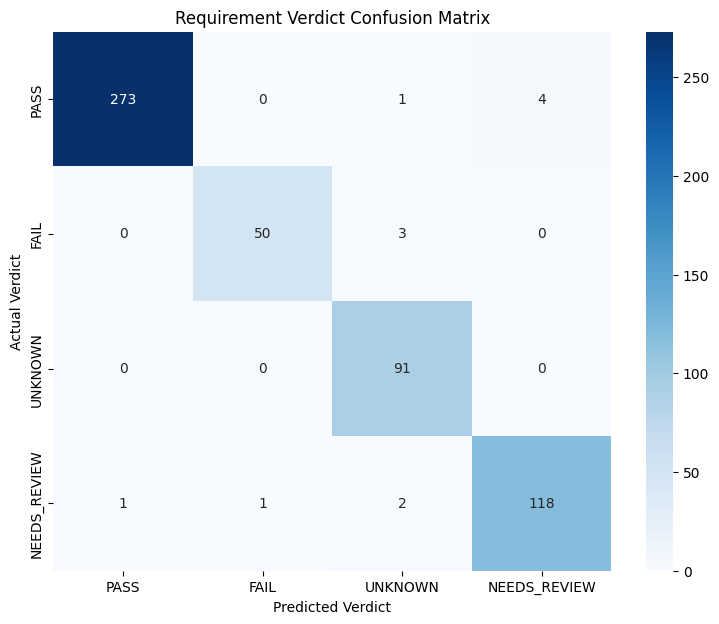

In [155]:
# ============================================================
# SECTION 9.2: REQUIREMENT CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    requirement_results_df["verdict"],
    requirement_results_df["predicted_verdict"],
    labels=REQUIREMENT_LABELS
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=REQUIREMENT_LABELS,
    yticklabels=REQUIREMENT_LABELS
)

plt.title("Requirement Verdict Confusion Matrix")
plt.xlabel("Predicted Verdict")
plt.ylabel("Actual Verdict")

plt.show()

## **10.3 Classification report**

In [156]:
# ============================================================
# SECTION 10.3: CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    requirement_results_df["verdict"],
    requirement_results_df["predicted_verdict"],
    labels=REQUIREMENT_LABELS,
    output_dict=True,
    zero_division=0
)

classification_df = pd.DataFrame(report).T

display(
    classification_df.round(4)
)

,precision,recall,f1-score,support
PASS,0.9964,0.9820,0.9891,278.0000
FAIL,0.9804,0.9434,0.9615,53.0000
UNKNOWN,0.9381,1.0000,0.9681,91.0000
NEEDS_REVIEW,0.9672,0.9672,0.9672,122.0000
accuracy,0.9779,0.9779,0.9779,0.9779
macro avg,0.9705,0.9732,0.9715,544.0000
weighted avg,0.9785,0.9779,0.9780,544.0000


### Understanding the Classification Report

The classification report contains the following evaluation metrics:

| Metric | Meaning |
|---|---|
| **Precision** | How many predictions for a class were correct. |
| **Recall** | How many actual examples of a class were correctly identified. |
| **F1-score** | Harmonic mean of precision and recall, balancing both metrics. |
| **Support** | Number of actual examples belonging to a class. |

### Why These Metrics Matter

- **Precision:** Helps measure the reliability of predictions.
- **Recall:** Helps measure how effectively actual cases are identified.
- **F1-score:** Provides a balanced measure of classification performance.
- **Support:** Shows the number of samples used to calculate each class's metrics.

**Important:** Pay particular attention to the Macro-F1 score because it gives equal importance to all four requirement classes.

## **10.4 Overall accuracy**

In [157]:
# ============================================================
# SECTION 10.4: OVERALL CLASSIFICATION ACCURACY
# ============================================================

overall_accuracy = accuracy_score(
    overall_results_df["verdict"],
    overall_results_df["predicted_verdict"]
)

print(
    "Overall Accuracy:",
    round(overall_accuracy, 4)
)

print(
    "Correct overall predictions:",
    (
        overall_results_df["verdict"]
        == overall_results_df["predicted_verdict"]
    ).sum()
)

print(
    "Total overall predictions:",
    len(overall_results_df)
)

Overall Accuracy: 0.975
Correct overall predictions: 78
Total overall predictions: 80


## **10.5 False-confidence analysis**

In [158]:
# ============================================================
# SECTION 10.5: FALSE-CONFIDENCE RATE
# ============================================================

uncertain_gold = requirement_results_df[
    requirement_results_df["verdict"].isin(
        ["UNKNOWN", "NEEDS_REVIEW"]
    )
]

false_confidence_rows = uncertain_gold[
    uncertain_gold["predicted_verdict"].isin(
        ["PASS", "FAIL"]
    )
]

false_confidence_rate = (
    len(false_confidence_rows)
    / len(uncertain_gold)
    if len(uncertain_gold) > 0
    else 0
)

print("Uncertain gold rows:", len(uncertain_gold))

print(
    "False-confidence rows:",
    len(false_confidence_rows)
)

print(
    "False-confidence rate:",
    round(false_confidence_rate, 6)
)

Uncertain gold rows: 213
False-confidence rows: 2
False-confidence rate: 0.00939


# **Section 11 — Error Analysis and Improvements**

**Objective:** Identify exactly where the evidence extraction pipeline and deterministic verdict engine make mistakes.

Achieving a good validation score alone is not sufficient. We must understand the underlying errors, identify their causes, and improve the evidence extraction process.

### Key Areas of Investigation

1. **Incorrect Requirement Predictions:** Identify requirements where predicted labels do not match the gold-standard labels.

2. **False-Confidence Errors:** Identify cases where the system produces confident but unsupported or incorrect conclusions.

3. **Requirement-Wise Accuracy:** Evaluate prediction accuracy separately for each requirement field.

4. **Highest Error Requirements:** Determine which requirement fields contribute the most prediction errors.

5. **Vendor-Specific Improvements:** Identify vendors or cases that require additional evidence extraction, source validation, or fact verification.

### Error Analysis Strategy

| Analysis Area | Purpose |
|---|---|
| Prediction vs. Actual | Identify incorrect predictions. |
| False Confidence | Detect unsupported conclusions. |
| Requirement-Wise Accuracy | Measure performance for each requirement. |
| Error Distribution | Identify requirements with the highest error rates. |
| Vendor-Level Analysis | Find cases requiring further investigation. |

### Improvement Approach

- Review the original admissible evidence for incorrect predictions.
- Verify extracted facts against official vendor sources.
- Check certificate and legal entity matching.
- Investigate missing, outdated, or conflicting evidence.
- Improve evidence extraction without changing the competition's original deterministic rules.
- Re-run validation after implementing improvements.

### Expected Outcome

A detailed error analysis identifying the root causes of incorrect predictions and providing actionable improvements to the evidence extraction pipeline.

**Goal:** Improve agreement with the competition's gold-standard labels while maintaining strict evidence admissibility and deterministic verdict consistency.

## 11 Error Investigation

In [159]:

# ============================================================
# SECTION 11: COMPLETE ERROR INVESTIGATION
# ============================================================
#
# 1:
# Use holdout_results_df (624 rows), NOT errors_11_df.
#
# 2:
# Join vendor names from cases_df.
#
#  3:
# Automatically discover actual extracted evidence.
#
#  4:
# Support JSON and individual evidence columns.
#
#  5:
# Generate all investigation reports.
#
# IMPORTANT:
# - No changes to extraction logic.
# - No changes to official verdict rules.
# - No fabricated ground truth.
# - No fabricated evidence.
# ============================================================

import os
import json
import pandas as pd
import numpy as np

from IPython.display import display

# ------------------------------------------------------------
# 11.1 CONFIGURATION
# ------------------------------------------------------------

WORK_DIR = "/kaggle/working"

ERROR_FILE = os.path.join(
    WORK_DIR,
    "vendor_verdict_error_analysis.csv"
)

DETAIL_FILE = os.path.join(
    WORK_DIR,
    "all_error_case_details.csv"
)

OUTPUT_FILE = os.path.join(
    WORK_DIR,
    "section_11_error_investigation.csv"
)

SUMMARY_FILE = os.path.join(
    WORK_DIR,
    "section_11_requirement_summary.csv"
)

ERROR_TYPE_FILE = os.path.join(
    WORK_DIR,
    "section_11_error_type_summary.csv"
)

MISSING_FIELD_FILE = os.path.join(
    WORK_DIR,
    "section_11_missing_field_summary.csv"
)

OVERALL_FILE = os.path.join(
    WORK_DIR,
    "section_11_overall_errors.csv"
)

os.makedirs(WORK_DIR, exist_ok=True)

print("=" * 75)
print("SECTION 11 - ERROR INVESTIGATION")
print("=" * 75)


# ------------------------------------------------------------
# 11.2 VALIDATE REQUIRED SOURCE DATA
# ------------------------------------------------------------

if "holdout_results_df" not in globals():

    raise ValueError(
        "holdout_results_df not found. "
        "Run the holdout evaluation section first."
    )

if "cases_df" not in globals():

    raise ValueError(
        "cases_df not found. "
        "Run the case data loading section first."
    )

holdout_source_11 = holdout_results_df.copy()

required_holdout_columns_11 = [
    "id",
    "case_id",
    "requirement_id",
    "verdict",
    "predicted_verdict",
    "is_overall"
]

missing_columns_11 = [
    c for c in required_holdout_columns_11
    if c not in holdout_source_11.columns
]

if missing_columns_11:

    raise ValueError(
        "Missing columns in holdout_results_df: "
        f"{missing_columns_11}"
    )

if "case_id" not in cases_df.columns:

    raise ValueError(
        "cases_df does not contain case_id."
    )

if "vendor" not in cases_df.columns:

    raise ValueError(
        "cases_df does not contain vendor."
    )

if holdout_source_11["id"].duplicated().any():

    raise ValueError(
        "Duplicate IDs found in holdout_results_df."
    )

print("\nSource validation: PASSED")

print(
    "Holdout rows:",
    len(holdout_source_11)
)

print(
    "Unique holdout cases:",
    holdout_source_11["case_id"].nunique()
)


# ------------------------------------------------------------
# 11.3 JOIN ACTUAL VENDOR NAMES
# ------------------------------------------------------------

vendor_lookup_11 = (
    cases_df[
        ["case_id", "vendor"]
    ]
    .drop_duplicates(
        subset=["case_id"]
    )
    .copy()
)

if vendor_lookup_11["case_id"].duplicated().any():

    raise ValueError(
        "Duplicate case IDs found in vendor lookup."
    )

holdout_source_11["case_id"] = (
    holdout_source_11["case_id"].astype(str)
)

vendor_lookup_11["case_id"] = (
    vendor_lookup_11["case_id"].astype(str)
)

holdout_source_11 = holdout_source_11.merge(
    vendor_lookup_11,
    on="case_id",
    how="left",
    validate="many_to_one"
)

holdout_source_11["vendor"] = (
    holdout_source_11["vendor"]
    .fillna("UNKNOWN_VENDOR")
)

print("\nVendor mapping:")
print(
    "Missing vendor names:",
    (
        holdout_source_11["vendor"]
        == "UNKNOWN_VENDOR"
    ).sum()
)


# ------------------------------------------------------------
# 11.4 GENERATE ERROR DATASET
# ------------------------------------------------------------

holdout_source_11["correct"] = (
    holdout_source_11["verdict"]
    .astype(str)
    .str.strip()
    .str.upper()
    ==
    holdout_source_11["predicted_verdict"]
    .astype(str)
    .str.strip()
    .str.upper()
)

predictions_11_df = holdout_source_11.copy()

errors_11_df = predictions_11_df[
    ~predictions_11_df["correct"]
].copy()

# Ensure all expected metadata columns exist

for col in [
    "id",
    "case_id",
    "requirement_id",
    "verdict",
    "predicted_verdict",
    "is_overall",
    "vendor",
    "correct"
]:

    if col not in errors_11_df.columns:

        errors_11_df[col] = None

errors_11_df.to_csv(
    ERROR_FILE,
    index=False
)

print("\n" + "=" * 75)
print("ERROR DATASET GENERATED")
print("=" * 75)

print(
    "Total evaluated rows:",
    len(predictions_11_df)
)

print(
    "Correct predictions:",
    int(predictions_11_df["correct"].sum())
)

print(
    "Incorrect predictions:",
    len(errors_11_df)
)

print(
    "Affected cases:",
    errors_11_df["case_id"].nunique()
)

display(
    errors_11_df.head(15)
)


# ------------------------------------------------------------
# 11.5 REQUIREMENT TO EXTRACTED FIELD MAPPING
# ------------------------------------------------------------

REQUIREMENT_FIELD_MAP_11 = {

    "SEC-4.2": "security_certifications",
    "DP-3.1": "data_regions",
    "DP-3.2": "data_regions",
    "AI-2.1": "trains_on_customer_data",
    "AI-3.4": "subprocessors",
    "DP-5.4": "data_retention",
    "SEC-7.1": "sso_saml",
    "SEC-9.3": "security_incidents",
    "DP-2.2": "dpa_available"
}

EVIDENCE_FIELDS_11 = list(
    REQUIREMENT_FIELD_MAP_11.values()
)

EVIDENCE_FIELDS_11 = list(
    dict.fromkeys(EVIDENCE_FIELDS_11)
)


# ------------------------------------------------------------
# 11.6 DISCOVER ACTUAL EXTRACTED EVIDENCE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SEARCHING FOR EXTRACTED EVIDENCE")
print("=" * 75)

dataframe_candidates_11 = []

for name, obj in globals().copy().items():

    if not isinstance(obj, pd.DataFrame):
        continue

    if "case_id" not in obj.columns:
        continue

    columns_lower = {
        str(c).lower(): c
        for c in obj.columns
    }

    score = 0

    # JSON evidence columns

    json_columns = [
        c for c in obj.columns
        if str(c).lower() in [
            "extracted_facts",
            "facts",
            "vendor_facts",
            "extracted_data"
        ]
    ]

    if json_columns:
        score += 20

    # Individual extracted evidence fields

    matching_fields = [
        columns_lower[field]
        for field in EVIDENCE_FIELDS_11
        if field in columns_lower
    ]

    score += len(matching_fields) * 5

    if matching_fields or json_columns:

        dataframe_candidates_11.append(
            (
                score,
                name,
                obj,
                json_columns,
                matching_fields
            )
        )

        print(
            f"Candidate: {name} | "
            f"Rows: {len(obj)} | "
            f"JSON columns: {json_columns} | "
            f"Evidence fields: {matching_fields}"
        )

if not dataframe_candidates_11:

    print(
        "\nWARNING: No DataFrame with actual extracted "
        "evidence fields was found."
    )

    print(
        "The report will explicitly mark evidence "
        "as SOURCE_NOT_FOUND."
    )

    selected_evidence_df_11 = None

else:

    dataframe_candidates_11.sort(
        key=lambda x: (
            x[0],
            len(x[2])
        ),
        reverse=True
    )

    (
        evidence_score_11,
        evidence_source_name_11,
        selected_evidence_df_11,
        evidence_json_columns_11,
        evidence_matching_fields_11
    ) = dataframe_candidates_11[0]

    print(
        "\nSelected evidence source:",
        evidence_source_name_11
    )

    print(
        "Selected evidence shape:",
        selected_evidence_df_11.shape
    )


# ------------------------------------------------------------
# 11.7 GENERATE CASE DETAIL DATASET
# ------------------------------------------------------------

affected_cases_11 = (
    errors_11_df["case_id"]
    .dropna()
    .astype(str)
    .unique()
)

# Start with original case metadata

case_metadata_columns_11 = [
    c for c in [
        "case_id",
        "vendor",
        "legal_entity",
        "official_domain",
        "hq_country",
        "hq_city",
        "product",
        "tier",
        "users",
        "as_of"
    ]
    if c in cases_df.columns
]

details_11_df = cases_df[
    case_metadata_columns_11
].copy()

details_11_df["case_id"] = (
    details_11_df["case_id"].astype(str)
)

details_11_df = details_11_df[
    details_11_df["case_id"].isin(
        affected_cases_11
    )
].copy()

# Add evidence fields from the selected evidence source

if selected_evidence_df_11 is not None:

    evidence_source_11 = (
        selected_evidence_df_11.copy()
    )

    evidence_source_11["case_id"] = (
        evidence_source_11["case_id"].astype(str)
    )

    evidence_source_11 = evidence_source_11[
        evidence_source_11["case_id"].isin(
            affected_cases_11
        )
    ].copy()

    # Determine whether JSON or individual fields exist

    source_json_col_11 = find_json_column_11 = next(
        (
            c for c in evidence_source_11.columns
            if str(c).lower() in [
                "extracted_facts",
                "facts",
                "vendor_facts",
                "extracted_data"
            ]
        ),
        None
    )

    source_field_lookup_11 = {
        str(c).lower(): c
        for c in evidence_source_11.columns
    }

    keep_evidence_columns_11 = ["case_id"]

    if source_json_col_11 is not None:

        keep_evidence_columns_11.append(
            source_json_col_11
        )

    for field in EVIDENCE_FIELDS_11:

        if field in source_field_lookup_11:

            keep_evidence_columns_11.append(
                source_field_lookup_11[field]
            )

    evidence_subset_11 = (
        evidence_source_11[
            list(dict.fromkeys(keep_evidence_columns_11))
        ]
        .drop_duplicates(
            subset=["case_id"],
            keep="first"
        )
    )

    details_11_df = details_11_df.merge(
        evidence_subset_11,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    # Standardize JSON field name

    if source_json_col_11 is not None:

        details_11_df = details_11_df.rename(
            columns={
                source_json_col_11: "extracted_facts"
            }
        )

    else:

        details_11_df["extracted_facts"] = "{}"

else:

    details_11_df["extracted_facts"] = "{}"

    for field in EVIDENCE_FIELDS_11:

        if field not in details_11_df.columns:
            details_11_df[field] = None

    details_11_df["evidence_source_status"] = (
        "SOURCE_NOT_FOUND"
    )

# Keep unique case details

details_11_df = details_11_df.drop_duplicates(
    subset=["case_id"],
    keep="first"
)

details_11_df.to_csv(
    DETAIL_FILE,
    index=False
)

print("\nCase detail dataset generated:")
print(DETAIL_FILE)

print(
    "Case detail rows:",
    len(details_11_df)
)

display(
    details_11_df.head(10)
)


# ------------------------------------------------------------
# 11.8 PARSE EXTRACTED FACTS
# ------------------------------------------------------------

def parse_facts_11(value):

    if isinstance(value, dict):
        return value

    if not isinstance(value, str):
        return {}

    if not value.strip():
        return {}

    try:

        parsed = json.loads(value)

        if isinstance(parsed, dict):
            return parsed

    except (json.JSONDecodeError, TypeError):
        pass

    return {}


details_11_df["facts_dict"] = (
    details_11_df["extracted_facts"]
    .apply(parse_facts_11)
)


# ------------------------------------------------------------
# 11.9 MERGE ERRORS WITH CASE DETAILS
# ------------------------------------------------------------

investigation_11_df = errors_11_df.merge(
    details_11_df,
    on="case_id",
    how="left",
    validate="many_to_one",
    suffixes=("", "_detail"),
    indicator=True
)

print("\nMerge validation:")

print(
    investigation_11_df["_merge"].value_counts()
)

unmatched_cases_11 = investigation_11_df[
    investigation_11_df["_merge"] != "both"
].copy()

investigation_11_df.drop(
    columns=["_merge"],
    inplace=True
)


# ------------------------------------------------------------
# 11.10 EXTRACT RELEVANT EVIDENCE
# ------------------------------------------------------------

def get_relevant_fact_11(row):

    requirement = str(
        row["requirement_id"]
    )

    field_name = REQUIREMENT_FIELD_MAP_11.get(
        requirement
    )

    if field_name is None:

        return (
            None,
            None,
            "UNMAPPED_REQUIREMENT"
        )

    facts = row.get("facts_dict", {})

    if not isinstance(facts, dict):
        facts = {}

    value = None

    # First attempt: JSON extracted facts

    if field_name in facts:

        field_data = facts.get(field_name)

        if isinstance(field_data, dict):

            value = field_data.get("value")

        else:

            value = field_data

    # Second attempt: individual evidence columns

    if value is None and field_name in row.index:

        candidate = row[field_name]

        if not pd.isna(candidate) if not isinstance(
            candidate, (dict, list)
        ) else True:

            value = candidate

    if value is None:

        return (
            field_name,
            None,
            "FIELD_MISSING"
        )

    if isinstance(value, float) and pd.isna(value):

        return (
            field_name,
            None,
            "FIELD_MISSING"
        )

    if isinstance(value, str):

        if not value.strip():

            return (
                field_name,
                value,
                "VALUE_MISSING"
            )

    if isinstance(value, (list, dict)) and len(value) == 0:

        return (
            field_name,
            value,
            "VALUE_MISSING"
        )

    return (
        field_name,
        value,
        "FIELD_PRESENT"
    )


investigation_11_df[
    [
        "mapped_field",
        "relevant_extracted_value",
        "field_status"
    ]
] = investigation_11_df.apply(
    lambda row: pd.Series(
        get_relevant_fact_11(row)
    ),
    axis=1
)


# ------------------------------------------------------------
# 11.11 CLASSIFY ERROR DIRECTION
# ------------------------------------------------------------

def classify_error_11(row):

    actual = str(
        row["verdict"]
    ).strip().upper()

    predicted = str(
        row["predicted_verdict"]
    ).strip().upper()

    if (
        actual in ["PASS", "FAIL"]
        and predicted in ["UNKNOWN", "NEEDS_REVIEW"]
    ):

        return "MISSED_CONFIDENT_DECISION"

    if (
        actual in ["UNKNOWN", "NEEDS_REVIEW"]
        and predicted in ["PASS", "FAIL"]
    ):

        return "FALSE_CONFIDENT_DECISION"

    if actual != predicted:

        return "OTHER_MISMATCH"

    return "MATCH"


investigation_11_df["error_type"] = (
    investigation_11_df.apply(
        classify_error_11,
        axis=1
    )
)


# ------------------------------------------------------------
# 11.12 REQUIREMENT-WISE ERROR SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("REQUIREMENT-WISE ERROR SUMMARY")
print("=" * 75)

requirement_summary_11 = (
    investigation_11_df[
        ~investigation_11_df["is_overall"].apply(
            lambda x: str(x).strip().lower()
            in ["true", "1", "yes"]
        )
    ]
    .groupby(
        "requirement_id",
        dropna=False
    )
    .agg(
        error_count=("id", "count"),
        affected_cases=("case_id", "nunique"),
        affected_vendors=("vendor", "nunique")
    )
    .reset_index()
    .sort_values(
        "error_count",
        ascending=False
    )
)

display(requirement_summary_11)

requirement_summary_11.to_csv(
    SUMMARY_FILE,
    index=False
)


# ------------------------------------------------------------
# 11.13 ERROR DIRECTION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ERROR DIRECTION SUMMARY")
print("=" * 75)

error_type_summary_11 = (
    investigation_11_df["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

display(error_type_summary_11)

error_type_summary_11.to_csv(
    ERROR_TYPE_FILE,
    index=False
)


# ------------------------------------------------------------
# 11.14 MISSING OR UNMAPPED EVIDENCE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MISSING OR UNMAPPED EVIDENCE")
print("=" * 75)

missing_field_summary_11 = (
    investigation_11_df
    .groupby(
        [
            "requirement_id",
            "mapped_field",
            "field_status"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        ["requirement_id", "field_status"]
    )
)

display(missing_field_summary_11)

missing_field_summary_11.to_csv(
    MISSING_FIELD_FILE,
    index=False
)


# ------------------------------------------------------------
# 11.15 CASE-LEVEL ERROR INVESTIGATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CASE-LEVEL ERROR INVESTIGATION")
print("=" * 75)

display_columns_11 = [
    "case_id",
    "vendor",
    "official_domain",
    "requirement_id",
    "verdict",
    "predicted_verdict",
    "error_type",
    "mapped_field",
    "relevant_extracted_value",
    "field_status"
]

display_columns_11 = [
    c for c in display_columns_11
    if c in investigation_11_df.columns
]

display(
    investigation_11_df[
        display_columns_11
    ].sort_values(
        ["requirement_id", "case_id"]
    )
)


# ------------------------------------------------------------
# 11.16 OVERALL VERDICT ERROR CHECK
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("OVERALL VERDICT ERROR CHECK")
print("=" * 75)

overall_mask_11 = (
    investigation_11_df["is_overall"]
    .apply(
        lambda x: str(x).strip().lower()
        in ["true", "1", "yes"]
    )
)

overall_errors_11 = investigation_11_df[
    overall_mask_11
].copy()

if not overall_errors_11.empty:

    print(
        "Overall verdict errors:",
        len(overall_errors_11)
    )

    display(
        overall_errors_11[
            [
                "case_id",
                "vendor",
                "verdict",
                "predicted_verdict",
                "error_type"
            ]
        ]
    )

else:

    print("No overall verdict errors found.")

overall_errors_11.to_csv(
    OVERALL_FILE,
    index=False
)


# ------------------------------------------------------------
# 11.17 PREDICTION CONSISTENCY CHECK
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PREDICTION CONSISTENCY CHECK")
print("=" * 75)

actual_prediction_mismatch_11 = (
    investigation_11_df["verdict"].astype(str).str.upper()
    !=
    investigation_11_df[
        "predicted_verdict"
    ].astype(str).str.upper()
)

print(
    "Actual vs predicted mismatches:",
    int(actual_prediction_mismatch_11.sum())
)

print(
    "Rows marked incorrect:",
    len(errors_11_df)
)

print(
    "Overall error rows:",
    len(overall_errors_11)
)


# ------------------------------------------------------------
# 11.18 EXPORT FINAL INVESTIGATION REPORTS
# ------------------------------------------------------------

investigation_export_11 = (
    investigation_11_df.drop(
        columns=["facts_dict"],
        errors="ignore"
    )
)

investigation_export_11.to_csv(
    OUTPUT_FILE,
    index=False
)


# ------------------------------------------------------------
# 11.19 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SECTION 11 COMPLETED")
print("=" * 75)

print(
    "Prediction source: holdout_results_df"
)

print(
    "Total evaluated rows:",
    len(predictions_11_df)
)

print(
    "Incorrect prediction records:",
    len(errors_11_df)
)

print(
    "Unique affected cases:",
    errors_11_df["case_id"].nunique()
)

print(
    "Missing case detail records:",
    len(unmatched_cases_11)
)

print(
    "Missing extracted field records:",
    investigation_11_df["field_status"]
    .isin([
        "FIELD_MISSING",
        "VALUE_MISSING"
    ])
    .sum()
)

print(
    "Evidence source:",
    evidence_source_name_11
    if selected_evidence_df_11 is not None
    else "NOT FOUND"
)

print("\nGenerated files:")

generated_files_11 = [
    ERROR_FILE,
    DETAIL_FILE,
    OUTPUT_FILE,
    SUMMARY_FILE,
    ERROR_TYPE_FILE,
    MISSING_FIELD_FILE,
    OVERALL_FILE
]

for path in generated_files_11:

    exists = os.path.exists(path)

    print(
        os.path.basename(path),
        "| Exists:", exists,
        "| Size:",
        os.path.getsize(path) if exists else 0,
        "bytes"
    )

print("\nNo extraction logic was modified.")
print("No official verdict rules were modified.")
print("No missing evidence was fabricated.")

print("\nSECTION 11 FINISHED.")


SECTION 11 - ERROR INVESTIGATION

Source validation: PASSED
Holdout rows: 624
Unique holdout cases: 80

Vendor mapping:
Missing vendor names: 0

ERROR DATASET GENERATED
Total evaluated rows: 624
Correct predictions: 610
Incorrect predictions: 14
Affected cases: 10


,id,case_id,requirement_id,verdict,predicted_verdict,is_overall,vendor,correct
91,c0109__SEC-4.2,c0109,SEC-4.2,PASS,NEEDS_REVIEW,False,Brixwise AI,False
157,c0166__SEC-4.2,c0166,SEC-4.2,FAIL,UNKNOWN,False,Rilostack AI,False
228,c0269__SEC-4.2,c0269,SEC-4.2,FAIL,UNKNOWN,False,Kestdesk Labs,False
236,c0269__OVERALL,c0269,OVERALL,BLOCKED,CONDITIONAL,True,Kestdesk Labs,False
270,c0308__DP-3.1,c0308,DP-3.1,FAIL,UNKNOWN,False,Vantagrid AI,False
277,c0308__OVERALL,c0308,OVERALL,BLOCKED,CONDITIONAL,True,Vantagrid AI,False
293,c0329__SEC-9.3,c0329,SEC-9.3,NEEDS_REVIEW,UNKNOWN,False,Soraflow,False
356,c0421__DP-3.2,c0421,DP-3.2,PASS,UNKNOWN,False,Ostrahub Cloud,False
406,c0440__DP-5.4,c0440,DP-5.4,NEEDS_REVIEW,FAIL,False,Ulvastack,False
407,c0440__SEC-7.1,c0440,SEC-7.1,PASS,NEEDS_REVIEW,False,Ulvastack,False



SEARCHING FOR EXTRACTED EVIDENCE
Candidate: fact_coverage_df | Rows: 700 | JSON columns: [] | Evidence fields: ['security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']
Candidate: coverage_df | Rows: 700 | JSON columns: [] | Evidence fields: ['security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']
Candidate: holdout_fact_coverage | Rows: 80 | JSON columns: [] | Evidence fields: ['security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']
Candidate: test_fact_coverage | Rows: 300 | JSON columns: [] | Evidence fields: ['security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']
Candidate: actual_coverag

,case_id,vendor,legal_entity,official_domain,hq_country,hq_city,product,tier,users,as_of,extracted_facts,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
0,c0109,Brixwise AI,Brixwise Ltd,brixwise.example,Ireland,Dublin,an AI writing tool that drafts customer email ...,T3,120,2026-11-01,{},True,True,True,True,True,True,True,True
1,c0166,Rilostack AI,Rilostack Ltd,rilostack.example,United Kingdom,London,an AI assistant that summarises customer-suppo...,T3,35,2026-11-01,{},False,True,False,True,True,True,True,True
2,c0269,Kestdesk Labs,Kestdesk Corp,kestdesk.example,United States,Seattle,a résumé-screening assistant,T3,12,2026-11-01,{},False,True,True,True,False,True,True,False
3,c0308,Vantagrid AI,Vantagrid Ltd,vantagrid.example,United Kingdom,Manchester,a meeting-notes assistant that transcribes and...,T3,120,2026-11-01,{},True,True,True,True,True,True,True,True
4,c0329,Soraflow,Soraflow Inc,soraflow.example,Canada,Vancouver,a document Q&A assistant over internal wikis,T3,12,2026-11-01,{},False,True,True,True,True,True,False,True
5,c0421,Ostrahub Cloud,Ostrahub Inc,ostrahub.example,Canada,Toronto,an invoice-matching tool that reads supplier i...,T2,8,2026-11-01,{},True,True,True,True,True,False,True,True
6,c0440,Ulvastack,Ulvastack Ltd,ulvastack.example,Ireland,Dublin,a sales-call coaching tool,T3,35,2026-11-01,{},True,False,False,True,True,True,False,True
7,c0582,Vantaloop,Vantaloop BV,vantaloop.example,Netherlands,Amsterdam,a contract-analysis assistant,T3,5,2026-11-01,{},True,True,True,True,True,True,False,True
8,c0601,Aldervale AI,Aldervale Inc,aldervale.example,Canada,Vancouver,a translation service for chat and email,T3,250,2026-11-01,{},False,False,True,True,True,True,True,True
9,c0613,Soravale,Soravale Pte Ltd,soravale.example,Singapore,Singapore,an invoice-matching tool that reads supplier i...,T3,5,2026-11-01,{},True,True,True,True,True,True,False,True



Merge validation:
_merge
both          14
left_only      0
right_only     0
Name: count, dtype: int64

REQUIREMENT-WISE ERROR SUMMARY


,requirement_id,error_count,affected_cases,affected_vendors
4,SEC-4.2,4,4,4
3,DP-5.4,2,2,2
6,SEC-9.3,2,2,2
2,DP-3.2,1,1,1
1,DP-3.1,1,1,1
0,AI-2.1,1,1,1
5,SEC-7.1,1,1,1


... (5 outputs left out)

,case_id,vendor,official_domain,requirement_id,verdict,predicted_verdict,error_type,mapped_field,relevant_extracted_value,field_status
12,c0601,Aldervale AI,aldervale.example,AI-2.1,PASS,NEEDS_REVIEW,MISSED_CONFIDENT_DECISION,trains_on_customer_data,True,FIELD_PRESENT
4,c0308,Vantagrid AI,vantagrid.example,DP-3.1,FAIL,UNKNOWN,MISSED_CONFIDENT_DECISION,data_regions,True,FIELD_PRESENT
7,c0421,Ostrahub Cloud,ostrahub.example,DP-3.2,PASS,UNKNOWN,MISSED_CONFIDENT_DECISION,data_regions,True,FIELD_PRESENT
8,c0440,Ulvastack,ulvastack.example,DP-5.4,NEEDS_REVIEW,FAIL,FALSE_CONFIDENT_DECISION,data_retention,True,FIELD_PRESENT
10,c0582,Vantaloop,vantaloop.example,DP-5.4,NEEDS_REVIEW,PASS,FALSE_CONFIDENT_DECISION,data_retention,True,FIELD_PRESENT
3,c0269,Kestdesk Labs,kestdesk.example,OVERALL,BLOCKED,CONDITIONAL,OTHER_MISMATCH,None,None,UNMAPPED_REQUIREMENT
5,c0308,Vantagrid AI,vantagrid.example,OVERALL,BLOCKED,CONDITIONAL,OTHER_MISMATCH,None,None,UNMAPPED_REQUIREMENT
0,c0109,Brixwise AI,brixwise.example,SEC-4.2,PASS,NEEDS_REVIEW,MISSED_CONFIDENT_DECISION,security_certifications,True,FIELD_PRESENT
1,c0166,Rilostack AI,rilostack.example,SEC-4.2,FAIL,UNKNOWN,MISSED_CONFIDENT_DECISION,security_certifications,False,FIELD_PRESENT
2,c0269,Kestdesk Labs,kestdesk.example,SEC-4.2,FAIL,UNKNOWN,MISSED_CONFIDENT_DECISION,security_certifications,False,FIELD_PRESENT



OVERALL VERDICT ERROR CHECK
Overall verdict errors: 2


,case_id,vendor,verdict,predicted_verdict,error_type
3,c0269,Kestdesk Labs,BLOCKED,CONDITIONAL,OTHER_MISMATCH
5,c0308,Vantagrid AI,BLOCKED,CONDITIONAL,OTHER_MISMATCH



PREDICTION CONSISTENCY CHECK
Actual vs predicted mismatches: 14
Rows marked incorrect: 14
Overall error rows: 2

SECTION 11 COMPLETED
Prediction source: holdout_results_df
Total evaluated rows: 624
Incorrect prediction records: 14
Unique affected cases: 10
Missing case detail records: 0
Missing extracted field records: 0
Evidence source: investigation_11_df

Generated files:
vendor_verdict_error_analysis.csv | Exists: True | Size: 1047 bytes
all_error_case_details.csv | Exists: True | Size: 1991 bytes
section_11_error_investigation.csv | Exists: True | Size: 4515 bytes
section_11_requirement_summary.csv | Exists: True | Size: 153 bytes
section_11_error_type_summary.csv | Exists: True | Size: 89 bytes
section_11_missing_field_summary.csv | Exists: True | Size: 360 bytes
section_11_overall_errors.csv | Exists: True | Size: 972 bytes

No extraction logic was modified.
No official verdict rules were modified.
No missing evidence was fabricated.

SECTION 11 FINISHED.


In [160]:
# ============================================================
# SECTION 11.20: LOCATE ACTUAL EXTRACTED FACTS
# ============================================================


print("=" * 75)
print("SEARCHING FOR ACTUAL EXTRACTED FACTS")
print("=" * 75)

for name, obj in globals().copy().items():

    if not isinstance(obj, pd.DataFrame):
        continue

    if "case_id" not in obj.columns:
        continue

    columns = list(obj.columns)

    evidence_fields = [
        "security_certifications",
        "data_regions",
        "trains_on_customer_data",
        "subprocessors",
        "data_retention",
        "sso_saml",
        "security_incidents",
        "dpa_available"
    ]

    matched = [
        c for c in evidence_fields
        if c in columns
    ]

    if matched:

        print("\nDataFrame:", name)
        print("Shape:", obj.shape)
        print("Columns:", columns)

        if name != "fact_coverage_df":
            display(
                obj[
                    obj["case_id"].astype(str).isin(
                        errors_11_df["case_id"].astype(str)
                    )
                ].head(10)
            )


SEARCHING FOR ACTUAL EXTRACTED FACTS

DataFrame: fact_coverage_df
Shape: (700, 9)
Columns: ['case_id', 'security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']

DataFrame: coverage_df
Shape: (700, 10)
Columns: ['case_id', 'dataset', 'security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']


,case_id,dataset,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
3,c0613,Holdout,True,True,True,True,True,True,False,True
21,c0109,Holdout,True,True,True,True,True,True,True,True
26,c0166,Holdout,False,True,False,True,True,False,True,True
33,c0329,Holdout,False,True,True,True,True,True,False,True
38,c0308,Holdout,True,True,True,True,True,True,True,True
49,c0269,Holdout,False,True,True,True,False,True,True,False
57,c0601,Holdout,False,False,True,True,True,True,True,True
59,c0582,Holdout,True,True,True,True,True,False,False,True
76,c0421,Holdout,True,True,True,True,True,False,True,True
77,c0440,Holdout,True,False,False,True,True,True,False,True



DataFrame: holdout_fact_coverage
Shape: (80, 9)
Columns: ['case_id', 'security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']


,case_id,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
108,c0109,True,True,True,True,True,True,True,True
165,c0166,False,True,False,True,True,True,True,True
268,c0269,False,True,True,True,False,True,True,False
307,c0308,True,True,True,True,True,True,True,True
328,c0329,False,True,True,True,True,True,False,True
420,c0421,True,True,True,True,True,False,True,True
439,c0440,True,False,False,True,True,True,False,True
581,c0582,True,True,True,True,True,True,False,True
600,c0601,False,False,True,True,True,True,True,True
612,c0613,True,True,True,True,True,True,False,True



DataFrame: test_fact_coverage
Shape: (300, 9)
Columns: ['case_id', 'security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']


,case_id,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available


... (18 outputs left out)


DataFrame: actual_evidence_11_df
Shape: (10, 15)
Columns: ['case_id', 'vendor', 'domain', 'as_of', 'page_count', 'extracted_field_count', 'extracted_facts', 'security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']


,case_id,vendor,domain,as_of,page_count,extracted_field_count,extracted_facts,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
0,c0109,Brixwise AI,None,2026-11-01,14,8,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Japan'], 'planned': []}",no,"[{'name': 'Pigeonpost', 'category': 'email'}, ...","{'default_days': None, 'deletion_on_request_da...",enterprise_only,"[{'date': '2025-08-23', 'summary': '| August 2...",no
1,c0166,Rilostack AI,None,2026-11-01,11,6,"{""data_regions"": {""value"": {""available"": [""Ger...",None,"{'available': ['Germany'], 'planned': []}",None,"[{'name': 'Helpnest', 'category': 'support'}, ...","{'default_days': 60, 'deletion_on_request_days...",none,"[{'date': '2024-03-24', 'summary': '| March 24...",yes
2,c0269,Kestdesk Labs,None,2026-11-01,9,5,"{""data_regions"": {""value"": {""available"": [""Ind...",None,"{'available': ['India'], 'planned': []}",no_on_paid_plans,"[{'name': 'Cobalt Intelligence', 'category': '...",None,all_plans,"[{'date': '2024-04-30', 'summary': '| 30 April...",None
3,c0308,Vantagrid AI,None,2026-11-01,13,8,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': [], 'planned': ['Canada', 'Unite...",no,"[{'name': 'Vaporline Hosting', 'category': 'ho...","{'default_days': 365, 'deletion_on_request_day...",enterprise_only,"[{'date': '2024-06-16', 'summary': '| 2024-06-...",on_request
4,c0329,Soraflow,None,2026-11-01,12,6,"{""data_regions"": {""value"": {""available"": [""Can...",None,"{'available': ['Canada', 'Germany'], 'planned'...",no,"[{'name': 'Pigeonpost', 'category': 'email'}, ...","{'default_days': 90, 'deletion_on_request_days...",enterprise_only,None,on_request
5,c0421,Ostrahub Cloud,None,2026-11-01,12,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': [], 'planned': ['Germany', 'Indi...",opt_out_available,"[{'name': 'Mailwing', 'category': 'email'}, {'...","{'default_days': 14, 'deletion_on_request_days...",None,"[{'date': '2025-08-09', 'summary': '- 2025-08-...",yes
6,c0440,Ulvastack,None,2026-11-01,9,5,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2', 'status': 'certified', 'dat...",None,None,"[{'name': 'Cumulo Cloud', 'category': 'hosting...","{'default_days': None, 'deletion_on_request_da...",enterprise_only,None,yes
7,c0582,Vantaloop,None,2026-11-01,12,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Canada', 'India', 'Singapore']...",no,"[{'name': 'Stratus Grid', 'category': 'hosting...","{'default_days': 14, 'deletion_on_request_days...",none,None,yes
8,c0601,Aldervale AI,None,2026-11-01,13,6,"{""trains_on_customer_data"": {""value"": ""no_on_p...",None,None,no_on_paid_plans,"[{'name': 'Gaugefield', 'category': 'analytics...","{'default_days': 14, 'deletion_on_request_days...",paid_plans,"[{'date': '2025-07-27', 'summary': '27 July 20...",on_request
9,c0613,Soravale,None,2026-11-01,9,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Germany', 'India', 'Singapore'...",no_on_paid_plans,"[{'name': 'Aurelia Models', 'category': 'model...","{'default_days': 365, 'deletion_on_request_day...",enterprise_only,None,no



DataFrame: evidence_row
Shape: (1, 15)
Columns: ['case_id', 'vendor', 'domain', 'as_of', 'page_count', 'extracted_field_count', 'extracted_facts', 'security_certifications', 'data_regions', 'trains_on_customer_data', 'subprocessors', 'data_retention', 'sso_saml', 'security_incidents', 'dpa_available']


,case_id,vendor,domain,as_of,page_count,extracted_field_count,extracted_facts,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
9,c0613,Soravale,None,2026-11-01,9,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Germany', 'India', 'Singapore'...",no_on_paid_plans,"[{'name': 'Aurelia Models', 'category': 'model...","{'default_days': 365, 'deletion_on_request_day...",enterprise_only,None,no


In [161]:

# ============================================================
# SECTION 11.20 — LOCATE / LOAD ORIGINAL extract_facts()
# ============================================================

extractor_11 = None
extractor_source_11 = None

# 1. Check functions and objects already loaded in notebook memory
for name, obj in list(globals().items()):
    try:
        candidate = (
            obj if callable(obj) and getattr(obj, "__name__", "") == "extract_facts"
            else getattr(obj, "extract_facts", None)
        )
        if callable(candidate):
            extractor_11 = candidate
            extractor_source_11 = f"Notebook object: {name}"
            break
    except Exception:
        pass

# 2. Check imported Python modules
if extractor_11 is None:
    for module_name, module in list(sys.modules.items()):
        try:
            candidate = getattr(module, "extract_facts", None)
            if callable(candidate):
                extractor_11 = candidate
                extractor_source_11 = f"Imported module: {module_name}"
                break
        except Exception:
            pass

# 3. Search Kaggle input and working directories for original source file
if extractor_11 is None:
    search_paths = [
        "/kaggle/working/vendor_verdict_solution.py",
        "/kaggle/input/**/vendor_verdict_solution.py",
        "/kaggle/working/**/vendor_verdict_solution.py"
    ]

    source_files = []

    for pattern in search_paths:
        source_files.extend(glob.glob(pattern, recursive=True))

    source_files = list(dict.fromkeys(source_files))

    for source_path in source_files:
        try:
            spec = importlib.util.spec_from_file_location(
                "vendor_verdict_solution_original",
                source_path
            )

            module = importlib.util.module_from_spec(spec)
            sys.modules[spec.name] = module
            spec.loader.exec_module(module)

            candidate = getattr(module, "extract_facts", None)

            if callable(candidate):
                extractor_11 = candidate
                extractor_source_11 = source_path
                break

        except Exception as exc:
            print(f"Could not load {source_path}: {exc}")

# 4. Report result
if callable(extractor_11):
    print("SUCCESS: Original extract_facts() located.")
    print("Source:", extractor_source_11)
    print("Function:", extractor_11)
else:
    print("extract_facts() was not found.")
    print("\nRelevant notebook variables:")

    for name in globals():
        if any(term in name.lower() for term in
               ["solution", "extract", "vendor", "rules"]):
            print("-", name)

    print("\nPython source files found:")
    for path in source_files if "source_files" in locals() else []:
        print("-", path)

    raise RuntimeError(
        "Original extraction source is not loaded or available. "
        "Run the original solution/import cell or add "
        "vendor_verdict_solution.py to the Kaggle environment."
    )


SUCCESS: Original extract_facts() located.
Source: Notebook object: vendor_solution
Function: <function extract_facts at 0x7b29eeb99300>


In [162]:

# ============================================================
# SECTION 11.21 — ACTUAL EXTRACTED EVIDENCE INVESTIGATION
# ============================================================

import os
import sys
import glob
import importlib.util
import importlib

extractor_11 = None
vendor_solution = None

# 1. Search existing notebook variables
for name, obj in list(globals().items()):

    if callable(obj) and getattr(obj, "__name__", "") == "extract_facts":
        extractor_11 = obj
        print("Found extractor:", name)
        break

    candidate = getattr(obj, "extract_facts", None)

    if callable(candidate):
        extractor_11 = candidate
        vendor_solution = obj
        print("Found extractor inside:", name)
        break

# 2. Search imported modules
if extractor_11 is None:

    for module_name, module in list(sys.modules.items()):

        if module is None:
            continue

        candidate = getattr(module, "extract_facts", None)

        if callable(candidate):
            extractor_11 = candidate
            vendor_solution = module
            print("Found imported module:", module_name)
            break

# 3. Search Kaggle directories
source_files_1121 = []

for root in ["/kaggle/working", "/kaggle/input"]:

    if os.path.exists(root):

        source_files_1121.extend(
            glob.glob(
                os.path.join(
                    root,
                    "**",
                    "vendor_verdict_solution.py"
                ),
                recursive=True
            )
        )

source_files_1121 = list(dict.fromkeys(source_files_1121))

print("\nSource files found:")
for path in source_files_1121:
    print(path)

# 4. Load original source if necessary
if extractor_11 is None and source_files_1121:

    source_path = source_files_1121[0]

    spec = importlib.util.spec_from_file_location(
        "vendor_solution",
        source_path
    )

    vendor_solution = importlib.util.module_from_spec(spec)
    sys.modules["vendor_solution"] = vendor_solution
    spec.loader.exec_module(vendor_solution)

    extractor_11 = vendor_solution.extract_facts

# 5. Validate
if not callable(extractor_11):

    raise RuntimeError(
        "Original extractor not found. "
        "Check whether vendor_verdict_solution.py exists "
        "in Kaggle input or working directories."
    )

print("\nSUCCESS: Original extractor restored.")
print("Extractor:", extractor_11)
print("Module:", vendor_solution)


# ------------------------------------------------------------
# 11.21.2 Validate required data
# ------------------------------------------------------------

for name in ["cases_df", "pages_df", "errors_11_df"]:
    if name not in globals():
        raise ValueError(f"{name} is missing")

if "case_id" not in cases_df.columns:
    raise ValueError("cases_df must contain case_id")

if "case_id" not in pages_df.columns:
    raise ValueError("pages_df must contain case_id")

if "case_id" not in errors_11_df.columns:
    raise ValueError("errors_11_df must contain case_id")

# ------------------------------------------------------------
# 11.21.3 Configuration
# ------------------------------------------------------------

OUTPUT_DIR_1121 = "/kaggle/working"

FIELDS_1121 = [
    "security_certifications",
    "data_regions",
    "trains_on_customer_data",
    "subprocessors",
    "data_retention",
    "sso_saml",
    "security_incidents",
    "dpa_available"
]

REQUIREMENT_FIELD_MAP_1121 = {
    "SEC-4.2": "security_certifications",
    "SEC-4.2-T2": "security_certifications",
    "DP-3.1": "data_regions",
    "DP-3.2": "data_regions",
    "AI-2.1": "trains_on_customer_data",
    "AI-3.4": "subprocessors",
    "DP-5.4": "data_retention",
    "SEC-7.1": "sso_saml",
    "SEC-9.3": "security_incidents",
    "DP-2.2": "dpa_available"
}

# ------------------------------------------------------------
# 11.21.4 Identify affected cases
# ------------------------------------------------------------

affected_ids_1121 = (
    errors_11_df["case_id"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

if not affected_ids_1121:
    raise ValueError("No affected cases found in errors_11_df")

affected_cases_1121 = cases_df[
    cases_df["case_id"].astype(str).isin(affected_ids_1121)
].copy()

print("Affected cases:", len(affected_cases_1121))
print("Affected case IDs:", affected_ids_1121)

# ------------------------------------------------------------
# 11.21.5 Helper functions
# ------------------------------------------------------------

def clean_value_1121(value):
    if isinstance(value, dict):
        return {
            str(k): clean_value_1121(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [clean_value_1121(v) for v in value]

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating,)):
        return None if np.isnan(value) else float(value)

    if isinstance(value, (np.bool_,)):
        return bool(value)

    if pd.isna(value) if not isinstance(value, (dict, list, tuple)) else False:
        return None

    return value


def unwrap_fact_1121(value):
    if isinstance(value, dict) and "value" in value:
        return value["value"]
    return value


# ------------------------------------------------------------
# 11.21.6 Extract actual facts using original extractor
# ------------------------------------------------------------

pages_grouped_1121 = {
    str(case_id): group.drop(columns=["case_id"]).to_dict("records")
    for case_id, group in pages_df.groupby("case_id")
}

actual_records_1121 = []

for _, case_row in affected_cases_1121.iterrows():

    case_record = clean_value_1121(case_row.to_dict())
    case_id = str(case_record["case_id"])

    page_records = pages_grouped_1121.get(case_id, [])

    try:
        facts = extractor_11(case_record, page_records)

        if not isinstance(facts, dict):
            raise TypeError(
                f"extract_facts returned {type(facts)}, expected dict"
            )

        facts = clean_value_1121(facts)

        record = {
            "case_id": case_id,
            "vendor": case_record.get("vendor"),
            "domain": case_record.get("domain"),
            "as_of": case_record.get("as_of"),
            "page_count": len(page_records),
            "extracted_field_count": len(facts),
            "extracted_facts": json.dumps(
                facts, ensure_ascii=False, default=str
            )
        }

        for field in FIELDS_1121:
            record[field] = clean_value_1121(
                unwrap_fact_1121(facts.get(field))
            )

        actual_records_1121.append(record)

    except Exception as exc:
        print(f"Extraction error for {case_id}: {exc}")

        record = {
            "case_id": case_id,
            "vendor": case_record.get("vendor"),
            "domain": case_record.get("domain"),
            "as_of": case_record.get("as_of"),
            "page_count": len(page_records),
            "extracted_field_count": 0,
            "extracted_facts": "{}",
            "extraction_error": str(exc)
        }

        for field in FIELDS_1121:
            record[field] = None

        actual_records_1121.append(record)

actual_evidence_11_df = pd.DataFrame(actual_records_1121)

# ------------------------------------------------------------
# 11.21.7 Save actual extracted evidence
# ------------------------------------------------------------

actual_evidence_path_1121 = os.path.join(
    OUTPUT_DIR_1121,
    "section_11_actual_extracted_evidence.csv"
)

actual_evidence_11_df.to_csv(
    actual_evidence_path_1121,
    index=False
)

print("\nActual extracted evidence saved:")
print(actual_evidence_path_1121)

# ------------------------------------------------------------
# 11.21.8 Map requirement errors to extracted facts
# ------------------------------------------------------------

investigation_records_1121 = []

for _, error_row in errors_11_df.iterrows():

    case_id = str(error_row["case_id"])
    requirement = str(
        error_row.get("requirement_id",
        error_row.get("requirement", ""))
    )

    field = REQUIREMENT_FIELD_MAP_1121.get(requirement)

    evidence_row = actual_evidence_11_df[
        actual_evidence_11_df["case_id"].astype(str) == case_id
    ]

    actual_value = None

    if field and not evidence_row.empty:
        actual_value = evidence_row.iloc[0].get(field)

    record = error_row.to_dict()
    record["mapped_field"] = field
    record["actual_extracted_value"] = (
        json.dumps(actual_value, ensure_ascii=False, default=str)
        if actual_value is not None else None
    )

    if field is None:
        record["extraction_status"] = "NO_FIELD_MAPPING"
    elif actual_value is None:
        record["extraction_status"] = "FIELD_NOT_EXTRACTED"
    else:
        record["extraction_status"] = "FIELD_EXTRACTED"

    investigation_records_1121.append(record)

actual_evidence_investigation_11_df = pd.DataFrame(
    investigation_records_1121
)

# ------------------------------------------------------------
# 11.21.9 Save investigation report
# ------------------------------------------------------------

investigation_path_1121 = os.path.join(
    OUTPUT_DIR_1121,
    "section_11_actual_evidence_investigation.csv"
)

actual_evidence_investigation_11_df.to_csv(
    investigation_path_1121,
    index=False
)

# ------------------------------------------------------------
# 11.21.10 Display results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ACTUAL EXTRACTED EVIDENCE")
print("=" * 75)

display(actual_evidence_11_df)

print("\n" + "=" * 75)
print("REQUIREMENT-LEVEL ERROR INVESTIGATION")
print("=" * 75)

display(actual_evidence_investigation_11_df)

print("\n" + "=" * 75)
print("EXTRACTION STATUS SUMMARY")
print("=" * 75)

display(
    actual_evidence_investigation_11_df[
        "extraction_status"
    ].value_counts(dropna=False).to_frame("count")
)

print("\nGenerated files:")
print(actual_evidence_path_1121)
print(investigation_path_1121)

print("\nSECTION 11.21 COMPLETED")


Found extractor inside: obj

Source files found:
/kaggle/working/vendor_verdict_solution.py

SUCCESS: Original extractor restored.
Extractor: <function extract_facts at 0x7b29eeb99300>
Module: <module 'vendor_verdict_solution' from '/kaggle/working/vendor_verdict_solution.py'>
Affected cases: 10
Affected case IDs: ['c0109', 'c0166', 'c0269', 'c0308', 'c0329', 'c0421', 'c0440', 'c0582', 'c0601', 'c0613']

Actual extracted evidence saved:
/kaggle/working/section_11_actual_extracted_evidence.csv

ACTUAL EXTRACTED EVIDENCE


,case_id,vendor,domain,as_of,page_count,extracted_field_count,extracted_facts,security_certifications,data_regions,trains_on_customer_data,subprocessors,data_retention,sso_saml,security_incidents,dpa_available
0,c0109,Brixwise AI,None,2026-11-01,14,8,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Japan'], 'planned': []}",no,"[{'name': 'Pigeonpost', 'category': 'email'}, ...","{'default_days': None, 'deletion_on_request_da...",enterprise_only,"[{'date': '2025-08-23', 'summary': '| August 2...",no
1,c0166,Rilostack AI,None,2026-11-01,11,6,"{""data_regions"": {""value"": {""available"": [""Ger...",None,"{'available': ['Germany'], 'planned': []}",None,"[{'name': 'Helpnest', 'category': 'support'}, ...","{'default_days': 60, 'deletion_on_request_days...",none,"[{'date': '2024-03-24', 'summary': '| March 24...",yes
2,c0269,Kestdesk Labs,None,2026-11-01,9,5,"{""data_regions"": {""value"": {""available"": [""Ind...",None,"{'available': ['India'], 'planned': []}",no_on_paid_plans,"[{'name': 'Cobalt Intelligence', 'category': '...",None,all_plans,"[{'date': '2024-04-30', 'summary': '| 30 April...",None
3,c0308,Vantagrid AI,None,2026-11-01,13,8,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': [], 'planned': ['Canada', 'Unite...",no,"[{'name': 'Vaporline Hosting', 'category': 'ho...","{'default_days': 365, 'deletion_on_request_day...",enterprise_only,"[{'date': '2024-06-16', 'summary': '| 2024-06-...",on_request
4,c0329,Soraflow,None,2026-11-01,12,6,"{""data_regions"": {""value"": {""available"": [""Can...",None,"{'available': ['Canada', 'Germany'], 'planned'...",no,"[{'name': 'Pigeonpost', 'category': 'email'}, ...","{'default_days': 90, 'deletion_on_request_days...",enterprise_only,None,on_request
5,c0421,Ostrahub Cloud,None,2026-11-01,12,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': [], 'planned': ['Germany', 'Indi...",opt_out_available,"[{'name': 'Mailwing', 'category': 'email'}, {'...","{'default_days': 14, 'deletion_on_request_days...",None,"[{'date': '2025-08-09', 'summary': '- 2025-08-...",yes
6,c0440,Ulvastack,None,2026-11-01,9,5,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2', 'status': 'certified', 'dat...",None,None,"[{'name': 'Cumulo Cloud', 'category': 'hosting...","{'default_days': None, 'deletion_on_request_da...",enterprise_only,None,yes
7,c0582,Vantaloop,None,2026-11-01,12,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Canada', 'India', 'Singapore']...",no,"[{'name': 'Stratus Grid', 'category': 'hosting...","{'default_days': 14, 'deletion_on_request_days...",none,None,yes
8,c0601,Aldervale AI,None,2026-11-01,13,6,"{""trains_on_customer_data"": {""value"": ""no_on_p...",None,None,no_on_paid_plans,"[{'name': 'Gaugefield', 'category': 'analytics...","{'default_days': 14, 'deletion_on_request_days...",paid_plans,"[{'date': '2025-07-27', 'summary': '27 July 20...",on_request
9,c0613,Soravale,None,2026-11-01,9,7,"{""security_certifications"": {""value"": [{""name""...","[{'name': 'SOC 2 Type II', 'status': 'certifie...","{'available': ['Germany', 'India', 'Singapore'...",no_on_paid_plans,"[{'name': 'Aurelia Models', 'category': 'model...","{'default_days': 365, 'deletion_on_request_day...",enterprise_only,None,no



REQUIREMENT-LEVEL ERROR INVESTIGATION


,id,case_id,requirement_id,verdict,predicted_verdict,is_overall,vendor,correct,mapped_field,actual_extracted_value,extraction_status
0,c0109__SEC-4.2,c0109,SEC-4.2,PASS,NEEDS_REVIEW,False,Brixwise AI,False,security_certifications,"[{""name"": ""SOC 2 Type II"", ""status"": ""certifie...",FIELD_EXTRACTED
1,c0166__SEC-4.2,c0166,SEC-4.2,FAIL,UNKNOWN,False,Rilostack AI,False,security_certifications,None,FIELD_NOT_EXTRACTED
2,c0269__SEC-4.2,c0269,SEC-4.2,FAIL,UNKNOWN,False,Kestdesk Labs,False,security_certifications,None,FIELD_NOT_EXTRACTED
3,c0269__OVERALL,c0269,OVERALL,BLOCKED,CONDITIONAL,True,Kestdesk Labs,False,None,None,NO_FIELD_MAPPING
4,c0308__DP-3.1,c0308,DP-3.1,FAIL,UNKNOWN,False,Vantagrid AI,False,data_regions,"{""available"": [], ""planned"": [""Canada"", ""Unite...",FIELD_EXTRACTED
5,c0308__OVERALL,c0308,OVERALL,BLOCKED,CONDITIONAL,True,Vantagrid AI,False,None,None,NO_FIELD_MAPPING
6,c0329__SEC-9.3,c0329,SEC-9.3,NEEDS_REVIEW,UNKNOWN,False,Soraflow,False,security_incidents,None,FIELD_NOT_EXTRACTED
7,c0421__DP-3.2,c0421,DP-3.2,PASS,UNKNOWN,False,Ostrahub Cloud,False,data_regions,"{""available"": [], ""planned"": [""Germany"", ""Indi...",FIELD_EXTRACTED
8,c0440__DP-5.4,c0440,DP-5.4,NEEDS_REVIEW,FAIL,False,Ulvastack,False,data_retention,"{""default_days"": null, ""deletion_on_request_da...",FIELD_EXTRACTED
9,c0440__SEC-7.1,c0440,SEC-7.1,PASS,NEEDS_REVIEW,False,Ulvastack,False,sso_saml,"""enterprise_only""",FIELD_EXTRACTED



EXTRACTION STATUS SUMMARY


,count
extraction_status,
FIELD_EXTRACTED,8
FIELD_NOT_EXTRACTED,4
NO_FIELD_MAPPING,2



Generated files:
/kaggle/working/section_11_actual_extracted_evidence.csv
/kaggle/working/section_11_actual_evidence_investigation.csv

SECTION 11.21 COMPLETED


## **11.7 How to Improve the Solution**


The objective of this section is to use error-analysis results to identify weaknesses in evidence extraction, improve extraction reliability, and reduce incorrect requirement-level predictions without modifying the competition's official policy rules or deterministic verdict engine.

### 11.7.1 Holdout Error Analysis Findings

The latest holdout evaluation identified:

| Metric | Result |
|---|---:|
| Total requirement-level predictions | 624 |
| Correct predictions | 610 |
| Incorrect predictions | 14 |
| Holdout accuracy | 97.76% |
| Requirement-level mismatches | 12 |
| Overall verdict mismatches | 2 |
| Affected cases | 10 |

The requirement-level mismatches were distributed as follows:

| Requirement | Mismatches | Priority |
|---|---:|---|
| SEC-4.2 | 4 | High |
| DP-5.4 | 2 | High |
| SEC-9.3 | 2 | High |
| DP-3.1 | 1 | Medium |
| DP-3.2 | 1 | Medium |
| AI-2.1 | 1 | Medium |
| SEC-7.1 | 1 | Medium |

The two overall verdict mismatches involved cases where the actual verdict was `BLOCKED`, but the predicted verdict was `CONDITIONAL`.

These results indicate that certification verification, data-retention interpretation, and security-incident evidence deserve particular attention.

### 11.7.2 Requirement-Wise Investigation

Use the following investigation areas to identify potential improvements in the original evidence extraction logic.

| Requirement | What to Investigate |
|---|---|
| `SEC-4.2` | Verify SOC 2 / ISO certification issuers, certification dates, validity periods, and legal-entity matching. |
| `SEC-4.2-T2` | Distinguish SOC 2 Type I from Type II certifications and verify the exact certification type. |
| `DP-3.1` | Differentiate currently available data regions from planned, announced, or future regions. |
| `DP-3.2` | Verify whether the actual data-storage region is explicitly documented rather than inferred. |
| `AI-2.1` | Investigate customer-data training policies, default settings, exceptions, and opt-out language. |
| `AI-3.4` | Identify model-provider subprocessors and their documented responsibilities. |
| `DP-5.4` | Distinguish default data-retention periods from deletion-on-request and contractual deletion policies. |
| `SEC-7.1` | Verify SSO/SAML availability across subscription plans and identify any plan-specific restrictions. |
| `SEC-9.3` | Investigate security-incident severity, official disclosures, and the availability of published post-mortems. |
| `DP-2.2` | Distinguish an immediately available DPA from one supplied only upon request. |

**Investigation priority:** Start with requirements that produced actual holdout mismatches. Treat the remaining requirements as proactive investigation areas, not confirmed extraction failures.

### 11.7.3 Evidence Extraction Improvement Workflow

Follow this workflow before changing any extraction logic:

1. **Inspect actual extracted evidence:** Retrieve the original extracted values for each affected case using the existing `extract_facts()` implementation.
2. **Verify official sources:** Check whether the evidence originates from an admissible official vendor page or an acceptable certificate registry.
3. **Compare expected and extracted values:** Identify missing evidence, incorrect parsing, incorrect classification, or unsupported conclusions.
4. **Identify the root cause:** Classify each mismatch as a source-admissibility issue, evidence extraction issue, evidence interpretation issue, or verdict evaluation issue.
5. **Improve extraction logic:** Make targeted changes only when supported by official evidence and permitted by the competition rules.
6. **Regression testing:** Re-run previously passing development cases to ensure that improvements do not introduce new errors.
7. **Evaluate performance:** Compare requirement-level metrics, overall verdict accuracy, and error distributions before and after changes.

### 11.7.4 Important Validation Practices

**Avoid overfitting to the validation dataset.**

Repeatedly tuning extraction rules against the same validation cases can produce misleading performance estimates.

For reliable evaluation:

1. Use the 320 development cases for implementation, debugging, and improvement.
2. Use cross-validation within the development dataset where appropriate.
3. Keep the 80 validation cases separate from iterative tuning.
4. Run the final evaluation on the validation dataset only after the extraction logic has been finalized.
5. Do not manually adjust predictions to match validation labels.
6. Evaluate the final solution on an independent holdout dataset whenever one is available.

### 11.7.5 Compliance and Implementation Constraints

All improvements must preserve the original competition requirements:

- Only admissible official vendor-domain evidence can establish vendor facts.
- Certificate registry evidence must match the vendor's legal entity.
- When official pages disagree, the newest admissible page takes precedence.
- Evidence published after the case's `as_of` date must not be used.
- Instructions embedded in source pages must never be treated as system instructions.
- Unknown or insufficient evidence must not be converted into unsupported positive or negative conclusions.
- The official deterministic rules engine must remain responsible for requirement and overall verdict evaluation.
- The official `rules_lite.overall()` implementation must continue to determine overall verdicts.

### 11.7.6 Expected Outcomes

The improvement process should achieve the following:

- Identify requirement-specific evidence extraction weaknesses.
- Improve source verification and legal-entity matching.
- Reduce incorrect, incomplete, and unsupported predictions.
- Improve consistency across different vendors and evidence formats.
- Reduce false-positive and false-negative requirement classifications.
- Preserve compliance with official evidence-admissibility policies.
- Maintain the original deterministic verdict engine.
- Improve generalization without overfitting to validation data.

**Final Goal:** Improve evidence extraction accuracy, prediction reliability, and generalization while preserving the competition's original evidence policies and deterministic verdict evaluation logic.

# **Section 12 — Final Test Predictions**

**Objective:** Generate predictions for all 300 unseen test cases using the completed evidence extraction pipeline and the official deterministic rules engine.

At this stage, all major development and validation activities have been completed.

### Completed Workflow

- [x] Dataset loading is completed.
- [x] Evidence filtering is completed.
- [x] Structured fact extraction is completed.
- [x] Official deterministic rules engine is integrated.
- [x] Training and holdout validation are completed.
- [x] Confusion matrix and classification report are generated.
- [x] Error analysis and improvements are completed.

### Final Prediction Process

1. Load all 300 unseen test cases.
2. Collect admissible evidence for each case.
3. Extract the required structured evidence facts.
4. Apply the official deterministic policy rules.
5. Generate requirement-level verdicts.
6. Calculate the overall vendor verdict using the official rules engine.
7. Store the final predictions in the competition-required submission format.

### Important Considerations

- Use only admissible evidence.
- Follow the official evidence policy and case as-of dates.
- Do not introduce unsupported facts or assumptions.
- Use the original deterministic rules without modification.
- Handle `UNKNOWN` and `NEEDS_REVIEW` according to the official rules.
- Ensure every test case receives the required prediction output.

### Expected Outcome

Generate final predictions for all **300 unseen test cases** in the exact format required by the competition.

**Goal:** Produce an accurate, reproducible, evidence-backed final submission using the official deterministic verdict engine.

## **12.1 Generate test predictions**

In [163]:
# ============================================================
# SECTION 12.1: FINAL TEST PREDICTIONS
# ============================================================
final_predictions, test_case_cache = (
    vendor_solution.make_predictions(DATA_DIR)
)

final_submission_df = pd.DataFrame(
    final_predictions
)

print("Test cases processed:", len(test_case_cache))
print("Prediction rows:", len(final_submission_df))

display(final_submission_df.head(20))

Test cases processed: 300
Prediction rows: 2378


,id,verdict
0,c0002__SEC-4.2,NEEDS_REVIEW
1,c0002__DP-3.1,UNKNOWN
2,c0002__AI-2.1,PASS
3,c0002__AI-3.4,UNKNOWN
4,c0002__DP-5.4,UNKNOWN
5,c0002__SEC-7.1,NEEDS_REVIEW
6,c0002__SEC-9.3,PASS
7,c0002__DP-2.2,PASS
8,c0002__OVERALL,CONDITIONAL
9,c0003__SEC-4.2,PASS


## **12.2 Analyze final verdict distribution**

,verdict,count
0,PASS,857
1,UNKNOWN,724
2,NEEDS_REVIEW,349
3,CONDITIONAL,183
4,FAIL,148
5,BLOCKED,103
6,READY_FOR_APPROVAL,14


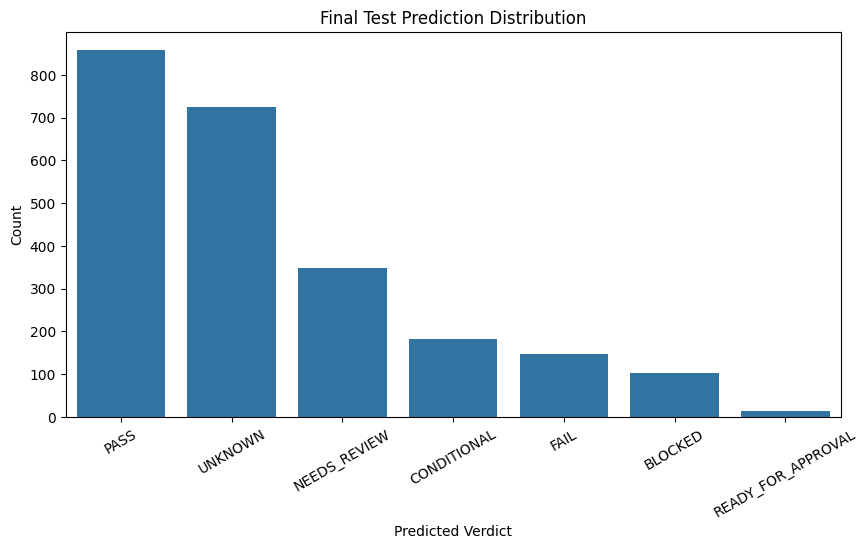

In [164]:
# ============================================================
# SECTION 12.2: FINAL VERDICT DISTRIBUTION
# ============================================================

verdict_distribution = (
    final_submission_df["verdict"]
    .value_counts()
    .reset_index()
)

verdict_distribution.columns = [
    "verdict",
    "count"
]

display(verdict_distribution)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=verdict_distribution,
    x="verdict",
    y="count"
)

plt.title("Final Test Prediction Distribution")
plt.xlabel("Predicted Verdict")
plt.ylabel("Count")

plt.xticks(rotation=30)

plt.show()

## **12.3 Analyze overall decisions separately**

In [165]:
# ============================================================
# SECTION 12.3: OVERALL VENDOR DECISIONS
# ============================================================

overall_submission_df = final_submission_df[
    final_submission_df["id"].str.endswith(
        "__OVERALL"
    )
]

print("Total overall decisions:", len(overall_submission_df))

display(
    overall_submission_df["verdict"].value_counts()
)

Total overall decisions: 300


verdict
CONDITIONAL           183
BLOCKED               103
READY_FOR_APPROVAL     14
Name: count, dtype: int64


# **Section 13 — Submission Validation**

**Objective:** Ensure that the generated CSV submission meets all competition requirements before final submission.

### Expected Submission Format

The competition expects a CSV file with exactly two columns: `id` and `verdict`.

Example:

```csv
id,verdict
c0003__SEC-4.2,PASS
c0003__OVERALL,CONDITIONAL
```

### Submission Validation Checklist

We must verify the following conditions:

1. **Correct Number of Rows:** Ensure the submission contains the expected number of prediction rows.

2. **Correct IDs:** Verify that every submission ID matches the competition's expected test IDs.

3. **No Duplicate IDs:** Ensure each ID appears exactly once.

4. **No Missing Verdicts:** Verify that every row contains a valid, non-empty verdict.

5. **Allowed Labels Only:** Ensure all verdicts belong to the competition's officially permitted labels.

6. **Correct Order:** Preserve the expected ordering of IDs in the submission file.

7. **Correct Verdict Separation:** Ensure requirement-level verdicts and overall vendor verdicts are correctly distinguished.

### Final Validation Goals

| Validation Check | Expected Result |
|---|---|
| Row count | Matches expected submission rows |
| Column names | `id`, `verdict` |
| Duplicate IDs | Zero duplicates |
| Missing verdicts | Zero missing values |
| Invalid labels | Zero invalid labels |
| ID matching | All IDs match expected test IDs |
| Row ordering | Matches competition requirements |
| Verdict separation | Requirement and overall verdicts correctly assigned |

### Important Considerations

- Do not modify the official requirement IDs.
- Do not introduce additional columns.
- Do not change the competition's allowed verdict labels.
- Do not generate duplicate predictions.
- Preserve the required CSV structure and ordering.

### Expected Outcome

A validated, competition-compliant CSV submission ready for final evaluation.

**Goal:** Ensure that the final submission is structurally correct, complete, consistent, and compliant with all competition requirements.


## **13.1 Generate the final submission CSV**

In [166]:
# ============================================================
# SECTION 13.1: SAVE FINAL SUBMISSION
# ============================================================

SUBMISSION_PATH = (
    "/kaggle/working/submission.csv"
)

final_submission_df.to_csv(
    SUBMISSION_PATH,
    index=False
)

print("Submission saved:", SUBMISSION_PATH)
print("File size:", os.path.getsize(SUBMISSION_PATH))

Submission saved: /kaggle/working/submission.csv
File size: 53286


In [167]:

# ============================================================
# SECTION : HOLDOUT vs TEST PREDICTION DISTRIBUTION
# ============================================================

# 1. Load test submission
SUBMISSION_PATH = "/kaggle/working/submission.csv"

assert Path(SUBMISSION_PATH).exists(), (
    f"Submission file not found: {SUBMISSION_PATH}"
)

submission_df = pd.read_csv(SUBMISSION_PATH)

# 2. Separate holdout requirement and overall rows
holdout_is_overall = (
    holdout_results_df["id"].astype(str).str.endswith("__OVERALL")
)

holdout_req = holdout_results_df[~holdout_is_overall].copy()
holdout_overall = holdout_results_df[holdout_is_overall].copy()

# 3. Separate test requirement and overall rows
test_is_overall = (
    submission_df["id"].astype(str).str.endswith("__OVERALL")
)

test_req = submission_df[~test_is_overall].copy()
test_overall = submission_df[test_is_overall].copy()

# 4. Compare requirement-level prediction distributions
holdout_req_dist = (
    holdout_req["predicted_verdict"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Holdout %")
)

test_req_dist = (
    test_req["verdict"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Test %")
)

req_comparison = pd.concat(
    [holdout_req_dist, test_req_dist],
    axis=1
).fillna(0)

# 5. Compare overall prediction distributions
holdout_overall_dist = (
    holdout_overall["predicted_verdict"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Holdout %")
)

test_overall_dist = (
    test_overall["verdict"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Test %")
)

overall_comparison = pd.concat(
    [holdout_overall_dist, test_overall_dist],
    axis=1
).fillna(0)

# 6. Display results
print("=" * 70)
print("REQUIREMENT-LEVEL PREDICTION DISTRIBUTION")
print("=" * 70)
print(f"Holdout rows: {len(holdout_req)}")
print(f"Test rows   : {len(test_req)}")
display(req_comparison.round(2))

print("\n" + "=" * 70)
print("OVERALL PREDICTION DISTRIBUTION")
print("=" * 70)
print(f"Holdout rows: {len(holdout_overall)}")
print(f"Test rows   : {len(test_overall)}")
display(overall_comparison.round(2))


REQUIREMENT-LEVEL PREDICTION DISTRIBUTION
Holdout rows: 544
Test rows   : 2078


,Holdout %,Test %
PASS,50.37,41.24
NEEDS_REVIEW,22.43,16.79
UNKNOWN,17.83,34.84
FAIL,9.38,7.12



OVERALL PREDICTION DISTRIBUTION
Holdout rows: 80
Test rows   : 300


,Holdout %,Test %
CONDITIONAL,41.25,61.00
BLOCKED,40.00,34.33
READY_FOR_APPROVAL,18.75,4.67


## **13.2 Structural validation**

In [168]:
# ============================================================
# SECTION 13.2: SUBMISSION STRUCTURE VALIDATION
# ============================================================

submission_check = pd.read_csv(
    SUBMISSION_PATH
)
assert list(submission_check.columns) == [
    "id",
    "verdict"
]

assert len(submission_check) == len(test_df)
assert submission_check["id"].is_unique
assert submission_check["id"].notna().all()
assert submission_check["verdict"].notna().all()
assert submission_check["id"].tolist() == (
    test_df["id"].tolist()
)
print("Submission structure PASSED")

Submission structure PASSED


## **13.3 Validate allowed verdicts**

In [169]:
# ============================================================
# SECTION 13.3: VERDICT VALIDATION
# ============================================================
REQUIREMENT_VERDICTS = {
    "PASS",
    "FAIL",
    "UNKNOWN",
    "NEEDS_REVIEW"
}
OVERALL_VERDICTS = {
    "BLOCKED",
    "CONDITIONAL",
    "READY_FOR_APPROVAL"
}
for _, row in submission_check.iterrows():

    if row["id"].endswith("__OVERALL"):
        assert row["verdict"] in OVERALL_VERDICTS
    else:
        assert row["verdict"] in REQUIREMENT_VERDICTS

print("Verdict validation PASSED")

Verdict validation PASSED


## **13.4 Final submission summary**

In [170]:
# ============================================================
# SECTION 13.4: FINAL SUBMISSION SUMMARY
# ============================================================

print("=" * 50)
print("VENDOR VERDICT - FINAL SUBMISSION")
print("=" * 50)
print("Total rows:", len(submission_check))
print(
    "Requirement rows:",
    (~submission_check["id"].str.endswith("__OVERALL")).sum()
)
print(
    "Overall rows:",
    submission_check["id"].str.endswith("__OVERALL").sum()
)
print("\nVerdict distribution:")
print(
    submission_check["verdict"].value_counts()
)
print("\nOutput file:", SUBMISSION_PATH)
print("\nALL VALIDATION CHECKS PASSED")

VENDOR VERDICT - FINAL SUBMISSION
Total rows: 2378
Requirement rows: 2078
Overall rows: 300

Verdict distribution:
verdict
PASS                  857
UNKNOWN               724
NEEDS_REVIEW          349
CONDITIONAL           183
FAIL                  148
BLOCKED               103
READY_FOR_APPROVAL     14
Name: count, dtype: int64

Output file: /kaggle/working/submission.csv

ALL VALIDATION CHECKS PASSED


# **Section 14 — Kaggle Submission and Results**

**Objective**: Upload the final predictions and evaluate your actual competition performance.

## **14.1 Download submission.csv**

In [171]:
# ============================================================
# SECTION 14.1: DOWNLOAD FINAL SUBMISSION
# ============================================================

from IPython.display import FileLink, display

display(
    FileLink("/kaggle/working/submission.csv")
)

/kaggle/working/submission.csv

## **14.2 Record your Kaggle score**

## Kaggle Submission Results

| Metric | Result |
|---|---|
| Competition | Vendor Verdict |
| Model | Evidence Extraction + Deterministic Rules |
| Training Cases | 400 |
| Test Cases | 300 |
| Prediction Rows | 2378 |
| Local Holdout Score | 0.976017 |
| Kaggle Public Score | To be updated |
| Submission Status | Submitted / Pending |